### Загрузка данных

Объединяем таблицы в единый датасет

In [ ]:
# Конвертируем ts и start_at
merged['ts'] = pd.to_datetime(merged['ts'])
merged['start_at'] = pd.to_datetime(merged['start_at'])

# Убедимся, что время обнулено
print(f"Уникальные времена в ts: {merged['ts'].dt.time.unique()}")
# Должно быть: [00:00:00]

# Проверяем диапазоны
print(f"Минимальная дата события: {merged['ts'].min()}")
print(f"Максимальная дата события: {merged['ts'].max()}")
print(f"Минимальная дата смены: {merged['start_at'].min()}")
print(f"Максимальная дата смены: {merged['start_at'].max()}")


Уникальные времена в ts: [datetime.time(0, 0)]
Минимальная дата события: 2026-01-01 00:00:00
Максимальная дата события: 2026-03-22 00:00:00
Минимальная дата смены: 2026-01-01 07:00:00+00:00
Максимальная дата смены: 2026-03-22 23:00:00+00:00


Посмотрим, есть ли повторяющиеся пары (user_id, shift_id)

In [ ]:
# Проверяем количество уникальных пар
unique_pairs = merged.groupby(['user_id', 'shift_id']).size().reset_index(name='count')
print(f"Всего записей в merged: {len(merged)}")
print(f"Уникальных пар (user_id, shift_id): {len(unique_pairs)}")

# Смотрим распределение количества записей на пару
print(f"\nСтатистика по количеству записей на пару:")
print(unique_pairs['count'].describe())

# Сколько пар имеют более одной записи?
duplicated_pairs = unique_pairs[unique_pairs['count'] > 1]
print(f"\nПар с несколькими записями: {len(duplicated_pairs)}")
print(f"Доля от всех пар: {len(duplicated_pairs) / len(unique_pairs) * 100:.2f}%")

Всего записей в merged: 840850
Уникальных пар (user_id, shift_id): 767065

Статистика по количеству записей на пару:
count    767065.000000
mean          1.096191
std           0.427923
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max           3.000000
Name: count, dtype: float64

Пар с несколькими записями: 36897
Доля от всех пар: 4.81%


In [ ]:
# Посмотрим на структуру дублирующихся пар
duplicated_examples = merged[merged.groupby(['user_id', 'shift_id'])['user_id'].transform('size') > 1]

print("Примеры дублирующихся пар (первые 10):")
print(duplicated_examples[['user_id', 'shift_id', 'interaction', 'ts']].head(10))

# Какие последовательности событий встречаются чаще всего?
from collections import Counter

# Для каждой пары собираем последовательность interaction в порядке ts
sequences = []
for (user, shift), group in duplicated_examples.groupby(['user_id', 'shift_id']):
    # Сортируем по времени
    seq = tuple(group.sort_values('ts')['interaction'].values)
    sequences.append(seq)

# Топ-5 последовательностей
sequence_counts = Counter(sequences)
print("\nТоп-5 последовательностей событий в дублирующихся парах:")
for seq, count in sequence_counts.most_common(5):
    print(f"  {seq}: {count} раз")

Примеры дублирующихся пар (первые 10):
                             user_id  shift_id interaction         ts
0   d0b587858e4eba68a2d5b71dd7cc91b3     64679        VIEW 2026-02-23
1   d0b587858e4eba68a2d5b71dd7cc91b3     64679       APPLY 2026-02-23
2   d0b587858e4eba68a2d5b71dd7cc91b3     64679    FINISHED 2026-02-23
3   d0b587858e4eba68a2d5b71dd7cc91b3     65231        VIEW 2026-02-24
4   d0b587858e4eba68a2d5b71dd7cc91b3     65231       APPLY 2026-02-24
5   d0b587858e4eba68a2d5b71dd7cc91b3     65231    FINISHED 2026-02-24
6   d0b587858e4eba68a2d5b71dd7cc91b3     67373        VIEW 2026-02-26
7   d0b587858e4eba68a2d5b71dd7cc91b3     67373       APPLY 2026-02-26
8   d0b587858e4eba68a2d5b71dd7cc91b3     67373    FINISHED 2026-02-26
10  d0b587858e4eba68a2d5b71dd7cc91b3     69052        VIEW 2026-02-27

Топ-5 последовательностей событий в дублирующихся парах:
  ('VIEW', 'APPLY', 'FINISHED'): 15728 раз
  ('VIEW', 'APPLY', 'USER_CANCEL'): 11503 раз
  ('VIEW', 'APPLY', 'SYSTEM_CANCEL'): 8885 р

дублирующиеся пары - это просто разные события

In [ ]:
# Проверяем FINISHED без APPLY
finished_without_apply = merged[
    (merged['interaction'] == 'FINISHED') &
    (~merged.duplicated(subset=['user_id', 'shift_id', 'interaction'], keep=False))
]

# Лучше проверить через groupby
pairs_with_finished = merged[merged['interaction'] == 'FINISHED'][['user_id', 'shift_id']].drop_duplicates()
pairs_with_apply = merged[merged['interaction'] == 'APPLY'][['user_id', 'shift_id']].drop_duplicates()

# Находим FINISHED без APPLY
finished_no_apply = pairs_with_finished.merge(
    pairs_with_apply,
    on=['user_id', 'shift_id'],
    how='left',
    indicator=True
)
finished_no_apply = finished_no_apply[finished_no_apply['_merge'] == 'left_only']

print(f"Пар с FINISHED: {len(pairs_with_finished)}")
print(f"Пар с APPLY: {len(pairs_with_apply)}")
print(f"Пар с FINISHED но без APPLY: {len(finished_no_apply)}")

Пар с FINISHED: 15910
Пар с APPLY: 36897
Пар с FINISHED но без APPLY: 0


Посмотрим, есть ли кейсы, когда пользовател отменил свое участие в смене, после этого был apply

In [ ]:
# Получаем все пары, где есть и USER_CANCEL и APPLY
pairs_with_both = merged[merged['interaction'].isin(['USER_CANCEL', 'APPLY'])].groupby(['user_id', 'shift_id']).filter(
    lambda x: len(x['interaction'].unique()) == 2
)

# Проверяем дневные последовательности
cancel_apply_pairs = []

for (user, shift), group in pairs_with_both.groupby(['user_id', 'shift_id']):
    cancel_dates = group[group['interaction'] == 'USER_CANCEL']['ts'].values
    apply_dates = group[group['interaction'] == 'APPLY']['ts'].values

    for cancel_date in cancel_dates:
        for apply_date in apply_dates:
            if apply_date > cancel_date:
                days_diff = (apply_date - cancel_date) / np.timedelta64(1, 'D')
                cancel_apply_pairs.append({
                    'user_id': user,
                    'shift_id': shift,
                    'cancel_date': cancel_date,
                    'apply_date': apply_date,
                    'days_after': int(days_diff)
                })

df_cancel_then_apply = pd.DataFrame(cancel_apply_pairs)

print(f"Пар с APPLY после USER_CANCEL (в разные дни): {len(df_cancel_then_apply)}")

if len(df_cancel_then_apply) > 0:
    print(f"\nПримеры:")
    print(df_cancel_then_apply.head(10))

    print(f"\nРаспределение дней между CANCEL и APPLY:")
    print(df_cancel_then_apply['days_after'].value_counts().sort_index())
else:
    print("Нет пар с APPLY после USER_CANCEL в разные дни")

Пар с APPLY после USER_CANCEL (в разные дни): 7

Примеры:
                            user_id  shift_id cancel_date apply_date  \
0  1187e53e77be87f644e8cea78023543f     46711  2026-01-18 2026-01-20   
1  1d8c0d319450a4547a15a67aba23af7b    103350  2026-02-23 2026-02-24   
2  343713b8d35190a3823602ed0811ae53     97592  2026-02-17 2026-02-18   
3  351afd17ba379b3802bf3739477c481a     15876  2026-01-02 2026-01-03   
4  6a6338f6c67737024623bf4f4443984c      2205  2026-01-31 2026-02-12   
5  b9c9641a918b77f13161027300e6da2b     85273  2026-02-24 2026-02-25   
6  c7d4a1baaa416fee577ffd82dae49cb0     71727  2026-03-12 2026-03-13   

   days_after  
0           2  
1           1  
2           1  
3           1  
4          12  
5           1  
6           1  

Распределение дней между CANCEL и APPLY:
days_after
1     5
2     1
12    1
Name: count, dtype: int64


APPLY после USER_CANCEL в разные дни: ТОЛЬКО 7 случаев (из 630,100 пар!)
Это 0.001% от всех пар
Можно считать статистической аномалией, оставляем как есть. не должно повлиять на результат

Посмотрим однодневные пары по порядку следования в df

In [ ]:
same_day_pairs = []  # список кортежей (user_id, shift_id)

for (user, shift), group in pairs_with_both.groupby(['user_id', 'shift_id']):
    cancel_dates = set(group[group['interaction'] == 'USER_CANCEL']['ts'].values)
    apply_dates = set(group[group['interaction'] == 'APPLY']['ts'].values)

    # Если есть пересечение дат (хотя бы один день, когда были оба события)
    if cancel_dates & apply_dates:
        same_day_pairs.append((user, shift))

print(f"Найдено пар (с Apply и User_Cancel): {len(same_day_pairs)}")

# Для обратной совместимости создаем список shift_id (уникальные смены)
same_day_shifts = list(set([shift for (user, shift) in same_day_pairs]))
# Используем уже готовый same_day_shifts из предыдущего анализа
# У нас уже есть список смен с однодневными событиями
print(f"Всего однодневных смен: {len(same_day_shifts)}")

# Быстро анализируем порядок, используя готовые данные
cancel_then_apply_count = 0
apply_then_cancel_count = 0
cancel_then_apply_with_finished = 0
cancel_then_apply_without_finished = 0

# Проходим только по однодневным сменам
for shift_id in same_day_shifts:
    # Получаем все события для этой смены (без группировки по пользователям)
    group = merged[merged['shift_id'] == shift_id].sort_index()

    # Нужно анализировать в разрезе пользователей
    for user_id in group['user_id'].unique():
        user_group = group[group['user_id'] == user_id]
        interactions = user_group['interaction'].tolist()

        if 'APPLY' in interactions and 'USER_CANCEL' in interactions:
            # Определяем последнее событие
            last_apply = max([i for i, e in enumerate(interactions) if e == 'APPLY'])
            last_cancel = max([i for i, e in enumerate(interactions) if e == 'USER_CANCEL'])
            has_finished = 'FINISHED' in interactions

            if last_apply > last_cancel:
                cancel_then_apply_count += 1
                if has_finished:
                    cancel_then_apply_with_finished += 1
                else:
                    cancel_then_apply_without_finished += 1
            else:
                apply_then_cancel_count += 1

print(f"\nРЕЗУЛЬТАТЫ БЫСТРОГО АНАЛИЗА:")
print(f"  CANCEL_then_APPLY (всего): {cancel_then_apply_count}")
print(f"    из них с FINISHED: {cancel_then_apply_with_finished}")
print(f"    из них без FINISHED: {cancel_then_apply_without_finished}")
print(f"  APPLY_then_CANCEL: {apply_then_cancel_count}")



Найдено пар (с Apply и User_Cancel): 6554
Всего однодневных смен: 5868

РЕЗУЛЬТАТЫ БЫСТРОГО АНАЛИЗА:
  CANCEL_then_APPLY (всего): 1
    из них с FINISHED: 0
    из них без FINISHED: 1
  APPLY_then_CANCEL: 7560


### Создаем целевую переменную

Так, как описано в требованиях: target = 1, если у пары User+shift было событие "Apply" или "Finished", и не было отмен.
Смены с System_cancel удаляем (они не будут участвовать в оценке результатов)

In [ ]:
# Группируем по (user_id, shift_id) и агрегируем
target_agg = merged.groupby(['user_id', 'shift_id']).agg(
    has_apply=('interaction', lambda x: ('APPLY' in x.values)),
    has_finished=('interaction', lambda x: ('FINISHED' in x.values)),
    has_cancel=('interaction', lambda x: ('USER_CANCEL' in x.values)),
    has_system_cancel=('interaction', lambda x: ('SYSTEM_CANCEL' in x.values))
).reset_index()

print(f"Агрегировано: {len(target_agg):,} пар")

# Применяем логику target
def set_target(row):
    if row['has_system_cancel']:
        return None  # исключаем
    if row['has_cancel']:
        return 0  # если есть USER_CANCEL
    if row['has_apply'] or row['has_finished']:
        return 1  # если есть APPLY или FINISHED
    return 0  # остальные

target_agg['target'] = target_agg.apply(set_target, axis=1)

# Удаляем None (смены с SYSTEM_CANCEL)
target_correct = target_agg.dropna(subset=['target']).copy()  # .copy() для явного создания копии
target_correct['target'] = target_correct['target'].astype(int)

print(f"\nРЕЗУЛЬТАТЫ:")
print(f"  Всего пар: {len(target_correct):,}")
print(f"  target=1: {target_correct['target'].sum():,} ({target_correct['target'].mean():.4%})")
print(f"  target=0: {len(target_correct) - target_correct['target'].sum():,}")

Агрегировано: 767,065 пар

РЕЗУЛЬТАТЫ:
  Всего пар: 757,976
  target=1: 15,919 (2.1002%)
  target=0: 742,057


Проверим корректность таргета

In [ ]:
# 1. Пары с USER_CANCEL (отмена пользователем)
pairs_user_cancel = merged[merged['interaction'] == 'USER_CANCEL'][['user_id', 'shift_id']].drop_duplicates()
print(f"\nПары с USER_CANCEL: {len(pairs_user_cancel):,}")

# 2. Пары с SYSTEM_CANCEL (отмена системой)
pairs_system_cancel = merged[merged['interaction'] == 'SYSTEM_CANCEL'][['user_id', 'shift_id']].drop_duplicates()
print(f"Пары с SYSTEM_CANCEL: {len(pairs_system_cancel):,}")

# 3. Объединенные пары (хотя бы одна отмена)
all_cancel_pairs = pd.concat([pairs_user_cancel, pairs_system_cancel]).drop_duplicates()
print(f"Пары с любой отменой (USER или SYSTEM): {len(all_cancel_pairs):,}")

# 4. Пары, где есть и USER, и SYSTEM (пересечение)
both_cancel = pairs_user_cancel.merge(pairs_system_cancel, on=['user_id', 'shift_id'], how='inner')
print(f"Пары с обеими отменами: {len(both_cancel):,}")

# ПРОВЕРКА НА ПЕРЕСЕЧЕНИЕ С TARGET

# Получаем target=1 пары
target_true = target_correct[target_correct['target'] == 1][['user_id', 'shift_id']]

# Проверяем, есть ли среди target=1 пары с отменами
target_with_user_cancel = target_true.merge(pairs_user_cancel, on=['user_id', 'shift_id'], how='inner')
target_with_system_cancel = target_true.merge(pairs_system_cancel, on=['user_id', 'shift_id'], how='inner')
target_with_any_cancel = target_true.merge(all_cancel_pairs, on=['user_id', 'shift_id'], how='inner')

print(f"target=1, но есть USER_CANCEL: {len(target_with_user_cancel):,} (должно быть 0)")
print(f"target=1, но есть SYSTEM_CANCEL: {len(target_with_system_cancel):,} (должно быть 0)")
print(f"target=1, но есть любая отмена: {len(target_with_any_cancel):,} (должно быть 0)")

# СТАТИСТИКА ПО СМЕНАМ (уникальные shift_id)

print("\nСТАТИСТИКА ПО УНИКАЛЬНЫМ СМЕНАМ\n")


shifts_with_user_cancel = merged[merged['interaction'] == 'USER_CANCEL']['shift_id'].nunique()
shifts_with_system_cancel = merged[merged['interaction'] == 'SYSTEM_CANCEL']['shift_id'].nunique()
shifts_with_any_cancel = len(set(merged[merged['interaction'] == 'USER_CANCEL']['shift_id'].unique()) |
                               set(merged[merged['interaction'] == 'SYSTEM_CANCEL']['shift_id'].unique()))

print(f"Смены с USER_CANCEL (хотя бы у одного пользователя): {shifts_with_user_cancel:,}")
print(f"Смены с SYSTEM_CANCEL: {shifts_with_system_cancel:,}")
print(f"Смены с любой отменой: {shifts_with_any_cancel:,}")


# ПРОВЕРКА ЛОГИКИ TARGET


print("\nПРОВЕРКА ЛОГИКИ TARGET\n")

# Создаем временный датафрейм для проверки
check_df = merged.groupby(['user_id', 'shift_id']).agg(
    has_apply=('interaction', lambda x: ('APPLY' in x.values)),
    has_finished=('interaction', lambda x: ('FINISHED' in x.values)),
    has_user_cancel=('interaction', lambda x: ('USER_CANCEL' in x.values)),
    has_system_cancel=('interaction', lambda x: ('SYSTEM_CANCEL' in x.values))
).reset_index()

# Сколько пар с APPLY и USER_CANCEL одновременно?
apply_and_user_cancel = check_df[(check_df['has_apply'] == True) & (check_df['has_user_cancel'] == True)]
print(f"Пары с APPLY и USER_CANCEL: {len(apply_and_user_cancel):,}")

# Сколько пар с APPLY, но без USER_CANCEL и без FINISHED?
apply_only_no_finished = check_df[((check_df['has_apply'] == True) | (check_df['has_finished'] == True))
                                  & (check_df['has_user_cancel'] == False)
                                & (check_df['has_system_cancel'] == False) ]
print(f"Пары с APPLY, но без USER_CANCEL : {len(apply_only_no_finished):,}")


Пары с USER_CANCEL: 11,889
Пары с SYSTEM_CANCEL: 9,089
Пары с любой отменой (USER или SYSTEM): 20,978
Пары с обеими отменами: 0
target=1, но есть USER_CANCEL: 0 (должно быть 0)
target=1, но есть SYSTEM_CANCEL: 0 (должно быть 0)
target=1, но есть любая отмена: 0 (должно быть 0)

СТАТИСТИКА ПО УНИКАЛЬНЫМ СМЕНАМ

Смены с USER_CANCEL (хотя бы у одного пользователя): 9,866
Смены с SYSTEM_CANCEL: 8,242
Смены с любой отменой: 16,097

ПРОВЕРКА ЛОГИКИ TARGET

Пары с APPLY и USER_CANCEL: 11,889
Пары с APPLY, но без USER_CANCEL : 15,919


In [ ]:
# Проверим на конкретном примере

# Смена 49938 (APPLY + USER_CANCEL от одного пользователя)
test1 = target_correct[target_correct['shift_id'] == 49938]
if len(test1) > 0:
    print(f"\nСмена 49938:")
    print(test1[['user_id', 'shift_id', 'has_apply', 'has_finished', 'has_cancel', 'target']].to_string())
    print(f"  target = {test1['target'].iloc[0]} (должен быть 0)")

# Смена 64679 - проверяем конкретного пользователя с FINISHED
correct_user = 'd0b587858e4eba68a2d5b71dd7cc91b3'
test2 = target_correct[(target_correct['shift_id'] == 64679) &
                        (target_correct['user_id'] == correct_user)]
if len(test2) > 0:
    print(f"\nСмена 64679, пользователь с FINISHED:")
    print(test2[['user_id', 'shift_id', 'has_apply', 'has_finished', 'has_cancel', 'target']].to_string())
    print(f"  target = {test2['target'].iloc[0]} (должен быть 1)")
else:
    print(f"\nСмена 64679, пользователь {correct_user[:30]}... не найден в target_correct")

# Проверяем пользователя с SYSTEM_CANCEL (должен быть исключен)
system_user = '7cdf53fb7eec3353e93cbf41a2f0e3c6'
test3 = target_correct[(target_correct['shift_id'] == 64679) &
                        (target_correct['user_id'] == system_user)]
print(f"\nПользователь с SYSTEM_CANCEL: присутствует в target? {len(test3) > 0} (должен быть исключен)")


Смена 49938:
                                 user_id  shift_id  has_apply  has_finished  has_cancel  target
624425  d0b587858e4eba68a2d5b71dd7cc91b3     49938       True         False        True       0
  target = 0 (должен быть 0)

Смена 64679, пользователь с FINISHED:
                                 user_id  shift_id  has_apply  has_finished  has_cancel  target
624431  d0b587858e4eba68a2d5b71dd7cc91b3     64679       True          True       False       1
  target = 1 (должен быть 1)

Пользователь с SYSTEM_CANCEL: присутствует в target? False (должен быть исключен)


In [ ]:

print("\nФИНАЛЬНАЯ ПРОВЕРКА КОРРЕКТНОСТИ\n")

# 1. Проверяем, что нет пар с USER_CANCEL и target=1
invalid_cancel = target_correct[target_correct['has_cancel'] & (target_correct['target'] == 1)]
print(f"Пары с USER_CANCEL и target=1: {len(invalid_cancel)} (должно быть 0)")

# 2. Проверяем, что все пары с FINISHED и без CANCEL имеют target=1
finished_no_cancel = target_correct[target_correct['has_finished'] & ~target_correct['has_cancel']]
print(f"Пары с FINISHED без CANCEL: {len(finished_no_cancel)}")
print(f"  Из них target=1: {finished_no_cancel['target'].sum()}")
print(f"  Из них target=0: {len(finished_no_cancel) - finished_no_cancel['target'].sum()} (должно быть 0)")

# 3. Проверяем, что все пары с APPLY без CANCEL и FINISHED имеют target=1
apply_no_cancel_no_finished = target_correct[target_correct['has_apply'] &
                                               ~target_correct['has_cancel'] &
                                               ~target_correct['has_finished']]
print(f"\nПары с APPLY без CANCEL и без FINISHED: {len(apply_no_cancel_no_finished)}")
print(f"  Из них target=1: {apply_no_cancel_no_finished['target'].sum()}")
print(f"  Из них target=0: {len(apply_no_cancel_no_finished) - apply_no_cancel_no_finished['target'].sum()} (должно быть 0)")

# Сохраняем финальный target
target_correct[['user_id', 'shift_id', 'target']].to_csv('target_final.csv', index=False)

# Добавляем target к merged
merged_with_target = merged.merge(
    target_correct[['user_id', 'shift_id', 'target']],
    on=['user_id', 'shift_id'],
    how='left'
)
print(f"Таблица merged_with_target: {len(merged_with_target):,} записей")


ФИНАЛЬНАЯ ПРОВЕРКА КОРРЕКТНОСТИ

Пары с USER_CANCEL и target=1: 0 (должно быть 0)
Пары с FINISHED без CANCEL: 15910
  Из них target=1: 15910
  Из них target=0: 0 (должно быть 0)

Пары с APPLY без CANCEL и без FINISHED: 9
  Из них target=1: 9
  Из них target=0: 0 (должно быть 0)
Таблица merged_with_target: 840,850 записей


## Формирование признаков

#### Справочник признаков для модели предсказания выхода на смену

###### Общая информация
- **Целевая переменная:** `target` (1 - пользователь записался на смену, 0 - не записался)
- **Момент предсказания:** за 2 дня до начала смены (`start_at - 2 дня`)
- **Окно для исторических признаков:** `[T-30, T-2]` (28 дней)

---

##### ГРУППА 1: Базовые признаки смены

| Признак | Тип | Описание | Способ расчета |
|---------|-----|----------|----------------|
| `hours` | numeric | Длительность смены в часах | Из данных смены |
| `reward` | numeric | Оплата за смену | Из данных смены |
| `reward_per_hour` | numeric | Почасовая оплата | `reward / hours` |
| `capacity` | numeric | Количество человек на смену | Из данных смены |
| `need_mk` | binary | Требуется ли медкнижка | Из данных смены |
| `is_long_shift` | binary | Длинная смена | `1` если `hours > 8`, иначе `0` |
| `is_short_shift` | binary | Короткая смена | `1` если `hours < 4`, иначе `0` |

---

##### ГРУППА 2: Временные признаки смены

| Признак | Тип | Описание | Способ расчета |
|---------|-----|----------|----------------|
| `shift_day_of_week` | categorical | День недели | `0` (пн) - `6` (вс) из `start_at` |
| `shift_hour` | categorical | Час начала смены | `0-23` из `start_at` |
| `shift_time_of_day` | categorical | Время суток | `morning` (6-11), `day` (12-17), `evening` (18-23), `night` (0-5) |
| `is_weekday` | binary | Будний день | `1` если пн-пт и не праздник, иначе `0` |

---

##### ГРУППА 3: Оконные признаки (контекст рынка)

| Признак | Тип | Описание | Способ расчета |
|---------|-----|----------|----------------|
| `median_pay_window` | numeric | Медианная оплата в окне | Скользящая медиана `reward_per_hour` за `[T-30, T-2]` |
| `is_high_paid_window` | binary | Высокая оплата относительно рынка | `1` если `reward_per_hour > median_pay_window`, иначе `0` |

---

##### ГРУППА 4: Взаимодействие пользователя со сменой

| Признак | Тип | Описание | Способ расчета |
|---------|-----|----------|----------------|
| `mk_match` | binary | Совпадение медкнижки | `1` если `has_mk == need_mk`, иначе `0` |
| `mk_match_2` | categorical | Состояние медкнижки (3 состояния) | `0` - книжка нужна, но нет; `1` - книжка нужна и есть; `2` - книжка не нужна |
| `location_match` | binary | Совпадение локации | `1` если `location_id_user == location_id_shift`, иначе `0` |
| `task_category` | categorical | Категория задания | Маппинг `task_type` в 9 категорий |

---

##### ГРУППА 5: Исторические признаки пользователя (окно `[T-30, T-2]`)

| Признак | Тип | Описание | Способ расчета |
|---------|-----|----------|----------------|
| `user_total_views` | numeric | Количество просмотренных смен | Число уникальных `shift_id` с `interaction='VIEW'` |
| `user_total_successful_actions` | numeric | Количество успешных записей | Число уникальных `shift_id` с `is_successful=1` |
| `user_success_rate` | numeric | Доля успешных записей | `user_total_successful_actions / user_total_views` (0 если нет просмотров) |
| `user_active_days` | numeric | Количество активных дней | Число уникальных дней с любыми событиями |
| `user_unique_employers` | numeric | Уникальные работодатели | `-1` если нет успешных действий, иначе число уникальных `employer_id` |
| `user_unique_task_types` | numeric | Уникальные типы заданий | `-1` если нет успешных действий, иначе число уникальных `task_type` |
| `user_location_experience` | numeric | Опыт в данной локации | `-1` если нет успешных действий, иначе число успешных записей в той же локации |
| `user_high_paid_ratio` | numeric | Доля высокооплачиваемых смен | `-1` если нет успешных действий, иначе доля смен с `reward_per_hour > median_pay_global` |
| `user_long_shift_ratio` | numeric | Доля длинных смен | `-1` если нет успешных действий, иначе доля смен с `hours > 8` |
| `user_short_shift_ratio` | numeric | Доля коротких смен | `-1` если нет успешных действий, иначе доля смен с `hours < 4` |
| `user_avg_reward_per_hour` | numeric | Средняя почасовая оплата | `-1` если нет успешных действий, иначе среднее `reward_per_hour` |

---

##### ГРУППА 6: Скользящие окна успешных действий

| Признак | Тип | Описание | Способ расчета |
|---------|-----|----------|----------------|
| `user_successful_actions_last_7d` | numeric | Успешных действий за 7 дней | Число успешных записей в `[T-7, T-2]` |
| `user_successful_actions_last_14d` | numeric | Успешных действий за 14 дней | Число успешных записей в `[T-14, T-2]` |

---

##### ГРУППА 7: Опыт по типу задач и работодателю

| Признак | Тип | Описание | Способ расчета |
|---------|-----|----------|----------------|
| `user_task_type_experience` | binary | Опыт с данным типом задачи | `1` если пользователь успешно работал с этим `task_type`, иначе `0` |
| `user_employer_experience` | binary | Опыт работы с данным работодателем | `1` если у пользователя был успешный выход у этого работодателя в окне `[T-30, T-2]`, иначе `0` |

---

##### ГРУППА 8: Признаки заказчика (накопленные за всю историю)

| Признак | Тип | Описание | Способ расчета |
|---------|-----|----------|----------------|
| `employer_avg_reward` | numeric | Средняя оплата смен | Среднее арифметическое `reward` по всем сменам |
| `employer_popularity` | numeric | Популярность среди пользователей | Число уникальных `user_id`, работавших у заказчика |
| `employer_reliability` | numeric | Надёжность заказчика | `1 - (system_cancels / total_shifts)` |

---

##### ГРУППА 9: Популярность смены

| Признак | Тип | Описание | Способ расчета |
|---------|-----|----------|----------------|
| `shift_total_views` | numeric | Всего просмотров смены | Число `VIEW` до момента предсказания |
| `free_spots_at_prediction` | numeric | Свободных мест на момент предсказания | `capacity - applies_before_prediction` (минимум 0) |
| `is_full_at_prediction` | binary | Смена заполнена | `1` если `free_spots_at_prediction == 0`, иначе `0` |

---

##### ГРУППА 10: Взаимодействие со сменой

| Признак | Тип | Описание | Способ расчета |
|---------|-----|----------|----------------|
| `view_count_for_shift` | numeric | Сколько раз пользователь просматривал эту смену | Число `VIEW` от этого пользователя на эту смену |
| `has_apply_before` | binary | Записывался ли ранее на эту смену | `1` если был `APPLY` от этого пользователя |

---

##### ГРУППА 11: Предпочтения пользователя

| Признак | Тип | Описание | Способ расчета |
|---------|-----|----------|----------------|
| `user_weekend_ratio` | numeric | Доля успехов в выходные | `-1` если нет успешных действий, иначе доля успехов в выходные |
| `user_day_ratio` | numeric | Доля успехов днём | `-1` если нет успешных действий, иначе доля успехов в `day` |
| `user_evening_ratio` | numeric | Доля успехов вечером | `-1` если нет успешных действий, иначе доля успехов в `evening` |
| `user_night_ratio` | numeric | Доля успехов ночью | `-1` если нет успешных действий, иначе доля успехов в `night` |

---

##### ГРУППА 12: Совпадение предпочтений

| Признак | Тип | Описание | Способ расчета |
|---------|-----|----------|----------------|
| `matches_high_paid` | binary | Совпадение по высокой оплате | `1` если смена высокооплачиваемая и `user_high_paid_ratio > 0.5`, `-1` если нет истории |
| `matches_long_shift` | binary | Совпадение по длинным сменам | `1` если смена длинная и `user_long_shift_ratio > 0.5` |
| `matches_short_shift` | binary | Совпадение по коротким сменам | `1` если смена короткая и `user_short_shift_ratio > 0.5` |
| `matches_time_of_day` | binary | Совпадение по времени суток | `1` если время смены совпадает с предпочтительным временем пользователя (на основе `day`/`evening`/`night`) |
| `matches_location` | binary | Совпадение по локации | `1` если у пользователя есть успешные записи в этой локации |

---

##### ГРУППА 13: Занятость в день смены

| Признак | Тип | Описание | Способ расчета |
|---------|-----|----------|----------------|
| `user_shifts_on_same_day` | numeric | Количество смен в тот же день | `-1` если уже записан на эту смену, иначе число других смен пользователя в этот день |

---

##### ГРУППА 14: Признаки взаимодействия

| Признак | Тип | Описание | Способ расчета |
|---------|-----|----------|----------------|
| `is_full_and_has_apply` | binary | Смена заполнена и пользователь записан | `1` если `is_full_at_prediction == 1` и `has_apply_before == 1` |

---

##### Сводная информация

| Группа | Признаки | Типы признаков |
|--------|----------|----------------|
| 1 | 7 | Базовые характеристики смены |
| 2 | 4 | Временные характеристики |
| 3 | 2 | Оконные статистики (рыночный контекст) |
| 4 | 4 | Взаимодействие пользователь-смена |
| 5 | 11 | История пользователя |
| 6 | 2 | Скользящие окна успехов |
| 7 | 2 | Опыт по задачам и работодателю |
| 8 | 3 | Характеристики заказчика |
| 9 | 3 | Популярность смены |
| 10 | 2 | Взаимодействие со сменой |
| 11 | 4 | Предпочтения пользователя |
| 12 | 5 | Совпадение предпочтений |
| 13 | 1 | Занятость в день смены |
| 14 | 1 | Комбинированные признаки |
| **Итого** | **51** | |

---

##### Важные замечания

1. **Заглушка `-1`** используется для признаков, когда нет данных для расчёта (нет истории, нет успешных действий)
2. **Момент предсказания** — за 2 дня до начала смены (`start_at - 2 дня`)
3. **Все исторические признаки** используют только события с `ts < start_at - 2 дня`
4. **Окно для исторических признаков** — `[T-30, T-2]` (28 дней), кроме специально оговоренных случаев

### Посмотрим на типы задач (task_type) и время между просмотром и сменой

In [ ]:
merged['task_type'].value_counts()

,count
task_type,
Выкладка товара,332745
Помощь в торговом зале,84170
Помощь в прикассовой зоне,61946
Обслуживание покупателей,58032
Погрузка и разгрузка товара,56131
Мойка посуды и инвентаря,55434
Доставка заказов на авто,51020
Сборка заказов,34612
Приготовление пищи,25212


Задач достаточно много, есть редкие (менее 1% от общего объема задач). Создадим сгруппированный признак по смыслу задачи.
Предлагаю обучить алгоритм на 2 вариациях данного признака - детальном и сгруппированном. Посмотреть, какой вариант покажут лучшее качество модели

In [ ]:

print("\nАНАЛИЗ ВРЕМЕНИ МЕЖДУ VIEW И START_AT\n")

# Берем только события VIEW
view_events = merged[merged['interaction'] == 'VIEW'].copy()

# Конвертируем даты в datetime с единым подходом
# Убираем часовой пояс для start_at
view_events['start_at'] = pd.to_datetime(view_events['start_at']).dt.tz_localize(None)
view_events['ts'] = pd.to_datetime(view_events['ts'])

# Вычисляем разницу в днях
view_events['days_between'] = (view_events['start_at'] - view_events['ts']).dt.days

# Фильтруем корректные значения (неотрицательные)
view_events_valid = view_events[view_events['days_between'] >= 0]

print(f"Всего VIEW событий: {len(view_events):,}")
print(f"Из них с корректной датой (VIEW до смены): {len(view_events_valid):,}")

# Базовая статистика

print(f"Среднее: {view_events_valid['days_between'].mean():.2f} дней")
print(f"Медиана: {view_events_valid['days_between'].median():.2f} дней")
print(f"Мода: {view_events_valid['days_between'].mode().iloc[0] if len(view_events_valid['days_between'].mode()) > 0 else 'N/A'} дней")
print(f"Стандартное отклонение: {view_events_valid['days_between'].std():.2f}")
print(f"Минимум: {view_events_valid['days_between'].min()} дней")
print(f"Максимум: {view_events_valid['days_between'].max()} дней")

# Квантили

print("\nКВАНТИЛИ\n")

for p in [25, 50, 75, 90, 95, 99]:
    quantile_val = view_events_valid['days_between'].quantile(p/100)
    print(f"{p}%: {quantile_val:.2f} дней")


АНАЛИЗ ВРЕМЕНИ МЕЖДУ VIEW И START_AT

Всего VIEW событий: 767,065
Из них с корректной датой (VIEW до смены): 767,065
Среднее: 4.41 дней
Медиана: 2.00 дней
Мода: 1 дней
Стандартное отклонение: 4.86
Минимум: 0 дней
Максимум: 39 дней

КВАНТИЛИ

25%: 1.00 дней
50%: 2.00 дней
75%: 6.00 дней
90%: 11.00 дней
95%: 15.00 дней
99%: 22.00 дней



ГИСТОГРАММА РАСПРЕДЕЛЕНИЯ ДНЕЙ МЕЖДУ VIEW И START_AT



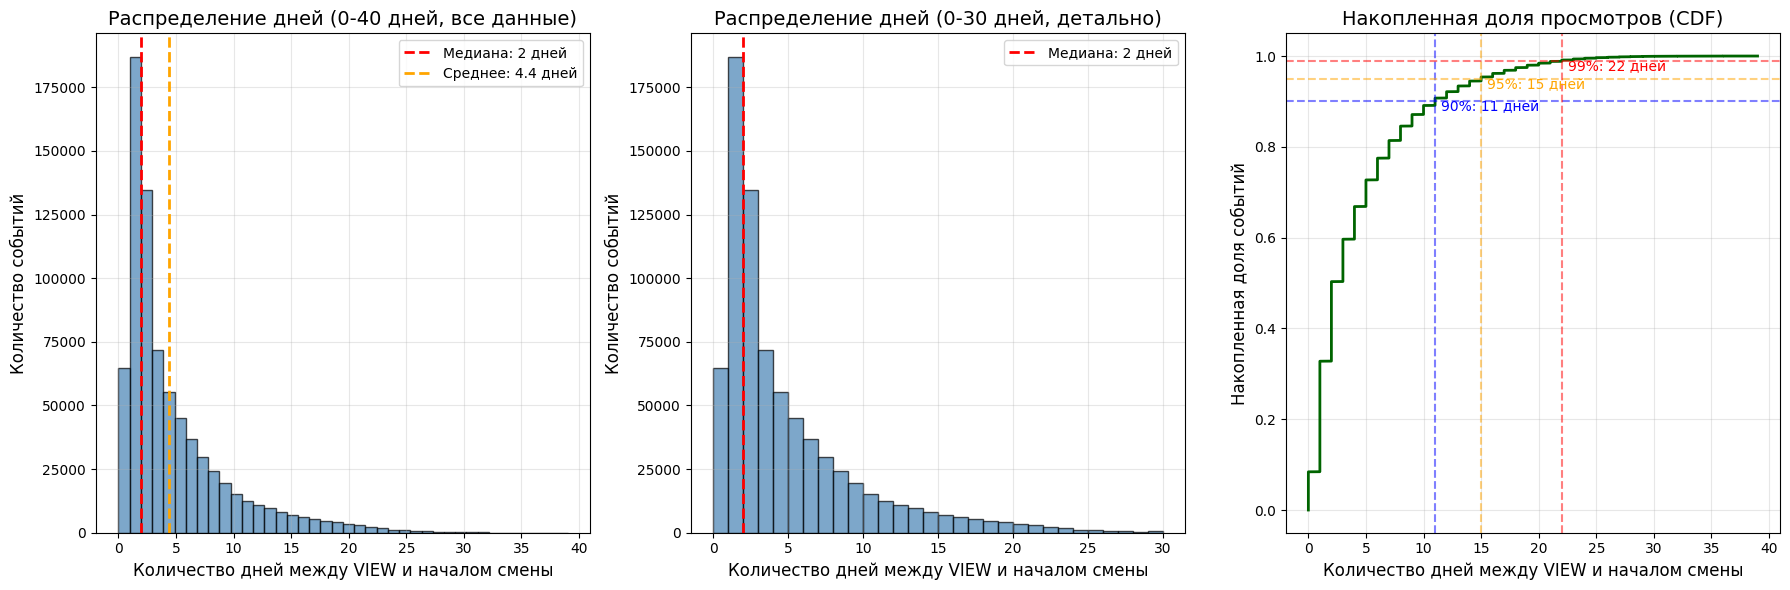

In [ ]:
print("\nГИСТОГРАММА РАСПРЕДЕЛЕНИЯ ДНЕЙ МЕЖДУ VIEW И START_AT\n")

# Берем данные из предыдущего анализа
view_events = merged[merged['interaction'] == 'VIEW'].copy()
view_events['start_at'] = pd.to_datetime(view_events['start_at']).dt.tz_localize(None)
view_events['ts'] = pd.to_datetime(view_events['ts'])
view_events['days_between'] = (view_events['start_at'] - view_events['ts']).dt.days
view_events_valid = view_events[view_events['days_between'] >= 0]

# Создаем фигуру с тремя подграфиками
fig = plt.figure(figsize=(18, 6))

# График 1: Гистограмма для всех данных (0-40 дней)
ax1 = plt.subplot(1, 3, 1)
ax1.hist(view_events_valid['days_between'], bins=40, edgecolor='black', alpha=0.7, color='steelblue')
ax1.set_xlabel('Количество дней между VIEW и началом смены', fontsize=12)
ax1.set_ylabel('Количество событий', fontsize=12)
ax1.set_title('Распределение дней (0-40 дней, все данные)', fontsize=14)
ax1.axvline(view_events_valid['days_between'].median(), color='red', linestyle='--',
            linewidth=2, label=f'Медиана: {view_events_valid["days_between"].median():.0f} дней')
ax1.axvline(view_events_valid['days_between'].mean(), color='orange', linestyle='--',
            linewidth=2, label=f'Среднее: {view_events_valid["days_between"].mean():.1f} дней')
ax1.legend()
ax1.grid(True, alpha=0.3)

# График 2: Гистограмма для первых 30 дней (детально)
ax2 = plt.subplot(1, 3, 2)
view_30 = view_events_valid[view_events_valid['days_between'] <= 30]
ax2.hist(view_30['days_between'], bins=30, edgecolor='black', alpha=0.7, color='steelblue')
ax2.set_xlabel('Количество дней между VIEW и началом смены', fontsize=12)
ax2.set_ylabel('Количество событий', fontsize=12)
ax2.set_title('Распределение дней (0-30 дней, детально)', fontsize=14)
ax2.axvline(view_events_valid['days_between'].median(), color='red', linestyle='--',
            linewidth=2, label=f'Медиана: {view_events_valid["days_between"].median():.0f} дней')
ax2.legend()
ax2.grid(True, alpha=0.3)

# График 3: Накопленная доля (CDF)
ax3 = plt.subplot(1, 3, 3)
sorted_days = np.sort(view_events_valid['days_between'])
cdf = np.arange(1, len(sorted_days) + 1) / len(sorted_days)
ax3.plot(sorted_days, cdf, linewidth=2, color='darkgreen')
ax3.set_xlabel('Количество дней между VIEW и началом смены', fontsize=12)
ax3.set_ylabel('Накопленная доля событий', fontsize=12)
ax3.set_title('Накопленная доля просмотров (CDF)', fontsize=14)
ax3.grid(True, alpha=0.3)

# Добавляем линии для 90%, 95%, 99%
for p, color, label in zip([0.9, 0.95, 0.99], ['blue', 'orange', 'red'], ['90%', '95%', '99%']):
    days_at_p = sorted_days[int(p * len(sorted_days))]
    ax3.axhline(y=p, color=color, linestyle='--', alpha=0.5)
    ax3.axvline(x=days_at_p, color=color, linestyle='--', alpha=0.5)
    ax3.text(days_at_p + 0.5, p - 0.02, f'{label}: {days_at_p} дней', fontsize=10, color=color)

plt.tight_layout()
plt.show()

Предлагаем делать прогноз за 2 дня до старта смены (медиана кол-ва дней между просмотрами и стартом смены). Так из экстренного режима поиска исполнителей можно перейти в режим оптимизированного поиска заранее, до смены.

Посмотрим на медиану кол-ва дней между просмотрами и стартом смены в разрезе типов задач


АНАЛИЗ ДОЛГОСРОЧНЫХ ПРОСМОТРОВ ПО ТИПАМ ЗАДАЧ

Колонки: ['id', 'shift_id', 'user_id', 'interaction', 'ts', 'location_id_user', 'is_strict_location', 'has_mk', 'start_at', 'location_id_shift', 'task_type', 'employer_id', 'workplace_id', 'need_mk', 'id_differential', 'hours', 'reward', 'capacity', 'days_between']
Есть task_type: True

ТОП-10 ТИПОВ ЗАДАЧ С НАИБОЛЬШЕЙ ДОЛЕЙ ДОЛГОСРОЧНЫХ ПРОСМОТРОВ (>=15 дней):


Сопровождение товара и разгрузка:
  Всего просмотров: 2,816
  Долгосрочных (≥15 дней): 751 (26.67%)
  Среднее дней: 9.2
  Медиана дней: 7

Выдача заказов (OZON):
  Всего просмотров: 139
  Долгосрочных (≥15 дней): 21 (15.11%)
  Среднее дней: 4.6
  Медиана дней: 2

Помощь в прикассовой зоне:
  Всего просмотров: 59,497
  Долгосрочных (≥15 дней): 8,697 (14.62%)
  Среднее дней: 7.0
  Медиана дней: 5

Выдача заказов:
  Всего просмотров: 4,501
  Долгосрочных (≥15 дней): 500 (11.11%)
  Среднее дней: 5.3
  Медиана дней: 2

Погрузка и разгрузка товара:
  Всего просмотров: 50,335
  Долгосроч

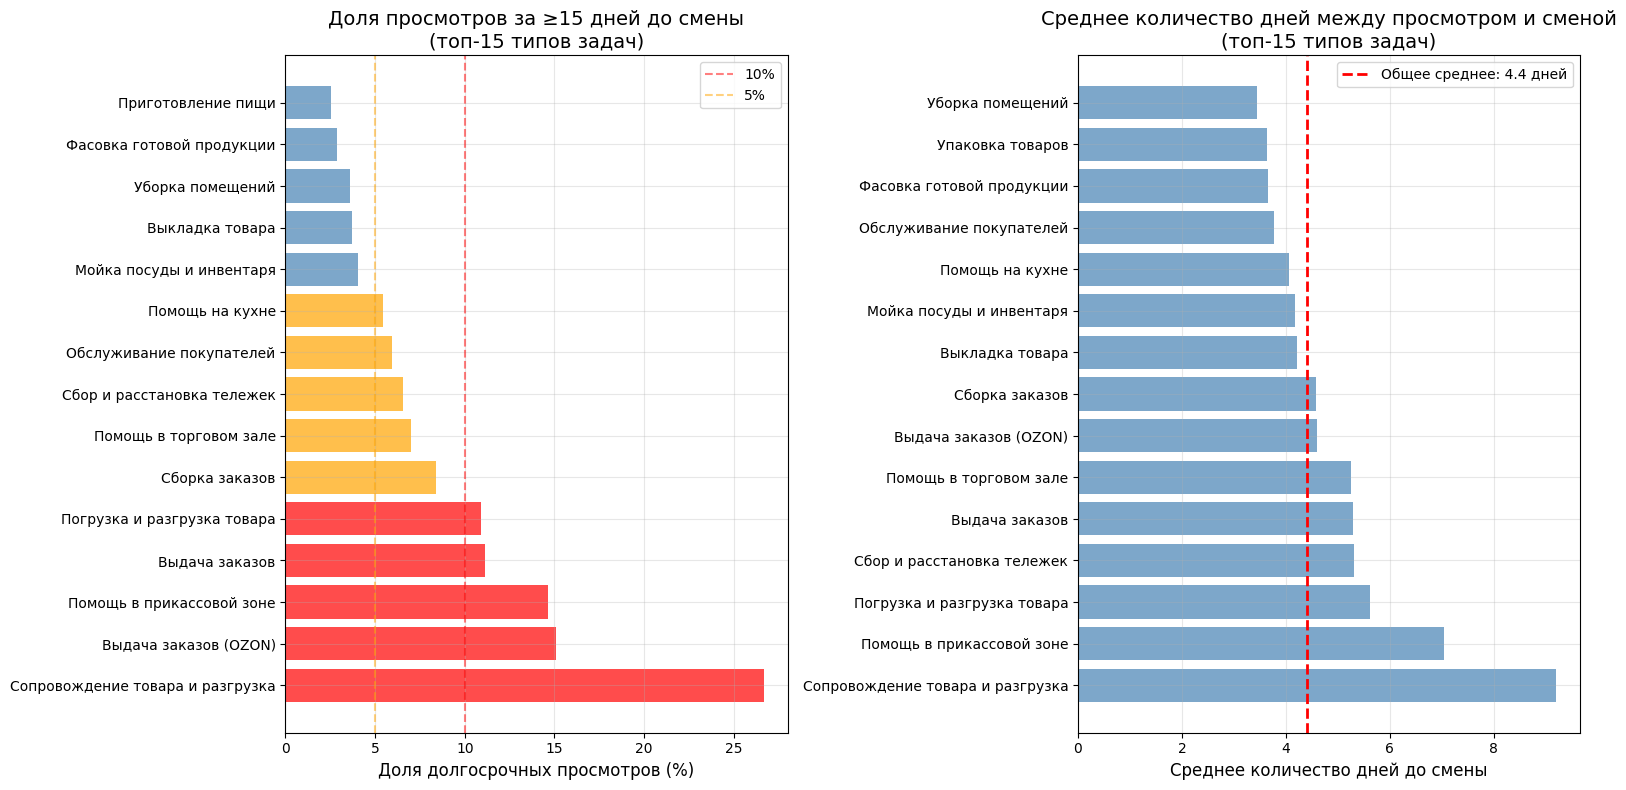

In [ ]:

print("\nАНАЛИЗ ДОЛГОСРОЧНЫХ ПРОСМОТРОВ ПО ТИПАМ ЗАДАЧ\n")

# Определяем долгосрочные просмотры (95+ перцентиль)
LONG_TERM_DAYS = 15  # просмотры за 15+ дней до смены

# Берем события VIEW и объединяем с shifts для получения task_type
view_events = merged[merged['interaction'] == 'VIEW'].copy()
view_events['start_at'] = pd.to_datetime(view_events['start_at']).dt.tz_localize(None)
view_events['ts'] = pd.to_datetime(view_events['ts'])
view_events['days_between'] = (view_events['start_at'] - view_events['ts']).dt.days
view_events_valid = view_events[view_events['days_between'] >= 0]

# Проверяем, есть ли колонка task_type
if 'task_type' not in view_events_valid.columns:
    # Добавляем информацию о типе задачи из таблицы shifts
    shifts_info = shifts[['id', 'task_type']].copy()
    view_events_valid = view_events_valid.merge(
        shifts_info,
        left_on='shift_id',
        right_on='id',
        how='left'
    )
    print(f"Добавлена информация о task_type")

# Проверяем, что task_type есть
print(f"Колонки: {view_events_valid.columns.tolist()}")
print(f"Есть task_type: {'task_type' in view_events_valid.columns}")

# Категоризируем просмотры
view_events_valid['view_type'] = view_events_valid['days_between'].apply(
    lambda x: 'long_term' if x >= LONG_TERM_DAYS else 'short_term'
)

# Статистика по типам задач
task_stats = view_events_valid.groupby('task_type').agg(
    total_views=('interaction', 'count'),
    long_term_views=('view_type', lambda x: (x == 'long_term').sum()),
    short_term_views=('view_type', lambda x: (x == 'short_term').sum()),
    avg_days=('days_between', 'mean'),
    median_days=('days_between', 'median')
).reset_index()

# Добавляем процент долгосрочных просмотров
task_stats['long_term_pct'] = task_stats['long_term_views'] / task_stats['total_views'] * 100

# Сортируем по проценту долгосрочных просмотров
task_stats_sorted = task_stats.sort_values('long_term_pct', ascending=False)

print(f"\nТОП-10 ТИПОВ ЗАДАЧ С НАИБОЛЬШЕЙ ДОЛЕЙ ДОЛГОСРОЧНЫХ ПРОСМОТРОВ (>={LONG_TERM_DAYS} дней):\n")

for _, row in task_stats_sorted.head(10).iterrows():
    print(f"\n{row['task_type']}:")
    print(f"  Всего просмотров: {row['total_views']:,}")
    print(f"  Долгосрочных (≥{LONG_TERM_DAYS} дней): {row['long_term_views']:,} ({row['long_term_pct']:.2f}%)")
    print(f"  Среднее дней: {row['avg_days']:.1f}")
    print(f"  Медиана дней: {row['median_days']:.0f}")

# ТИПЫ ЗАДАЧ С НАИМЕНЬШЕЙ ДОЛЕЙ ДОЛГОСРОЧНЫХ ПРОСМОТРОВ

print("\nТОП-10 ТИПОВ ЗАДАЧ С НАИМЕНЬШЕЙ ДОЛЕЙ ДОЛГОСРОЧНЫХ ПРОСМОТРОВ:\n")

for _, row in task_stats_sorted.tail(10).iterrows():
    print(f"\n{row['task_type']}:")
    print(f"  Всего просмотров: {row['total_views']:,}")
    print(f"  Долгосрочных (≥{LONG_TERM_DAYS} дней): {row['long_term_views']:,} ({row['long_term_pct']:.2f}%)")
    print(f"  Среднее дней: {row['avg_days']:.1f}")
    print(f"  Медиана дней: {row['median_days']:.0f}")

# Визуализация
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# График 1: Доля долгосрочных просмотров по типам задач (топ-15)
ax1 = axes[0]
top_tasks = task_stats_sorted.head(15)
colors = ['red' if x > 10 else 'orange' if x > 5 else 'steelblue' for x in top_tasks['long_term_pct']]
ax1.barh(range(len(top_tasks)), top_tasks['long_term_pct'], color=colors, alpha=0.7)
ax1.set_yticks(range(len(top_tasks)))
ax1.set_yticklabels(top_tasks['task_type'], fontsize=10)
ax1.set_xlabel('Доля долгосрочных просмотров (%)', fontsize=12)
ax1.set_title(f'Доля просмотров за ≥{LONG_TERM_DAYS} дней до смены\n(топ-15 типов задач)', fontsize=14)
ax1.axvline(x=10, color='red', linestyle='--', alpha=0.5, label='10%')
ax1.axvline(x=5, color='orange', linestyle='--', alpha=0.5, label='5%')
ax1.legend()
ax1.grid(True, alpha=0.3)

# График 2: Среднее количество дней до смены по типам задач
ax2 = axes[1]
avg_days_sorted = task_stats.sort_values('avg_days', ascending=False).head(15)
ax2.barh(range(len(avg_days_sorted)), avg_days_sorted['avg_days'], color='steelblue', alpha=0.7)
ax2.set_yticks(range(len(avg_days_sorted)))
ax2.set_yticklabels(avg_days_sorted['task_type'], fontsize=10)
ax2.set_xlabel('Среднее количество дней до смены', fontsize=12)
ax2.set_title('Среднее количество дней между просмотром и сменой\n(топ-15 типов задач)', fontsize=14)
ax2.axvline(x=view_events_valid['days_between'].mean(), color='red', linestyle='--',
            linewidth=2, label=f'Общее среднее: {view_events_valid["days_between"].mean():.1f} дней')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Видим, что разные типы задач имеют разные значения медианы и среднего значения кол-ва дней между просмотрами и стартом смены.

Для учебной задачи в рамках хакатона  будем делать прогноз за 2 дня до смены (медиана). Но как потенциал для развития модели в рабочем процессе предлагам время показа смены пользователю (насколько заранее до смены) также адаптировать под тип задачи на основании статистического анализа

In [ ]:
print("\nШАГ 1: БАЗОВЫЕ, ВРЕМЕННЫЕ И ОКОННЫЕ ПРИЗНАКИ СМЕНЫ\n")

# 1. ПОДГОТОВКА ДАННЫХ

print("\n1. ПОДГОТОВКА ДАННЫХ\n")

# Параметры окна
WINDOW_END_OFFSET = 2
WINDOW_START_OFFSET = 28 + WINDOW_END_OFFSET  # = 30 дней

# Приводим даты к единому формату
merged['ts'] = pd.to_datetime(merged['ts']).dt.tz_localize(None)
merged['start_at'] = pd.to_datetime(merged['start_at']).dt.tz_localize(None)
merged['shift_id'] = merged['shift_id'].astype('int64')

# Подготовка shifts
shifts_clean = shifts.copy()
shifts_clean['id'] = shifts_clean['id'].astype('int64')
shifts_clean['start_at'] = pd.to_datetime(shifts_clean['start_at']).dt.tz_localize(None)
shifts_clean['reward_per_hour'] = shifts_clean['reward'] / shifts_clean['hours']

# Создаем features_df с парами (user, shift)
features_df = target_correct[['user_id', 'shift_id', 'target']].copy()
features_df['shift_id'] = features_df['shift_id'].astype('int64')

# Добавляем информацию о смене (включая reward_per_hour)
shift_cols = ['id', 'start_at', 'location_id', 'task_type', 'employer_id',
              'workplace_id', 'need_mk', 'id_differential', 'hours', 'reward', 'capacity', 'reward_per_hour']
features_df = features_df.merge(shifts_clean[shift_cols], left_on='shift_id', right_on='id', how='left')
features_df['start_at'] = pd.to_datetime(features_df['start_at'])

# Добавляем информацию о пользователе
users_clean = users.rename(columns={'id': 'user_id', 'location_id': 'location_id_user'})
features_df = features_df.merge(users_clean[['user_id', 'location_id_user', 'is_strict_location', 'has_mk']], on='user_id', how='left')
features_df = features_df.rename(columns={'location_id': 'location_id_shift'})

print(f"Всего пар (user, shift): {len(features_df):,}")

# Фильтруем train (февраль) и test (март)
train_df = features_df[(features_df['start_at'] >= '2026-02-01') &
                        (features_df['start_at'] <= '2026-02-28')].copy()
test_df = features_df[(features_df['start_at'] >= '2026-03-01') &
                       (features_df['start_at'] <= '2026-03-22')].copy()

print(f"Train: {len(train_df):,} пар, Test: {len(test_df):,} пар")

# 2. ФУНКЦИЯ ДЛЯ ДОБАВЛЕНИЯ ОКОННЫХ СТАТИСТИК (ПАМЯТЬ ЭФФЕКТИВНАЯ)

print("\n2. ДОБАВЛЕНИЕ ОКОННЫХ СТАТИСТИК\n")

def add_window_features_vectorized(df, shifts_history, window_start_offset, window_end_offset):
    """
    Векторизованное добавление оконных статистик (без кросс-джойна)
    Использует группировку по датам и скользящее окно
    """
    df = df.copy()

    # Агрегируем смены по дням (медианная оплата за день)
    daily_median = shifts_history.groupby(shifts_history['start_at'].dt.normalize())['reward_per_hour'].median().reset_index()
    daily_median.columns = ['date', 'daily_median_pay']
    daily_median = daily_median.sort_values('date')

    # Создаем полный календарь дат от минимальной до максимальной
    date_range = pd.date_range(
        start=daily_median['date'].min() - timedelta(days=window_start_offset),
        end=daily_median['date'].max(),
        freq='D'
    )

    # Заполняем пропуски (дни без смен) - используем последнее известное значение
    daily_median_full = daily_median.set_index('date').reindex(date_range, method='ffill').reset_index()
    daily_median_full.columns = ['date', 'daily_median_pay']

    # Рассчитываем скользящую медиану за окно [T-30, T-2]
    daily_median_full['rolling_median'] = daily_median_full['daily_median_pay'].rolling(
        window=window_start_offset - window_end_offset,  # 28 дней
        min_periods=1
    ).median()

    # Сдвигаем на WINDOW_END_OFFSET (чтобы не использовать T и T-1)
    daily_median_full['median_pay_window'] = daily_median_full['rolling_median'].shift(window_end_offset)

    # Добавляем дату смены (нормализованную) для джойна
    df['shift_date'] = df['start_at'].dt.normalize()

    # Мерджим с рассчитанной медианой
    df = df.merge(daily_median_full[['date', 'median_pay_window']], left_on='shift_date', right_on='date', how='left')

    # Fallback: для дат без данных (самые ранние) используем общую медиану
    global_median = shifts_history['reward_per_hour'].median()
    df['median_pay_window'] = df['median_pay_window'].fillna(global_median)

    # Создаем признак на основе окна
    df['is_high_paid_window'] = (df['reward_per_hour'] > df['median_pay_window']).astype(int)


    # Удаляем вспомогательные колонки
    df = df.drop(columns=['shift_date'])

    return df

# Добавляем оконные признаки для train
print("Добавление оконных признаков для train...")
train_df = add_window_features_vectorized(train_df, shifts_clean, WINDOW_START_OFFSET, WINDOW_END_OFFSET)

# Добавляем оконные признаки для test
print("Добавление оконных признаков для test...")
test_df = add_window_features_vectorized(test_df, shifts_clean, WINDOW_START_OFFSET, WINDOW_END_OFFSET)

print("Оконные признаки добавлены (векторизовано, без кросс-джойна):")
print("  - median_pay_window (числовой) - медианная оплата в окне [T-30, T-2]")
print("  - is_high_paid_window (бинарный) - выше ли оплата медианы окна")


# 3. БАЗОВЫЕ ПРИЗНАКИ СМЕНЫ

print("\n3. БАЗОВЫЕ ПРИЗНАКИ СМЕНЫ\n")

def add_basic_features(df):
    df = df.copy()

    # is_long_shift - длинная смена (>8 часов)
    df['is_long_shift'] = (df['hours'] > 8).astype(int)

    # is_short_shift - короткая смена (<4 часов)
    df['is_short_shift'] = (df['hours'] < 4).astype(int)

    # mk_match - совпадение медкнижки
    df['mk_match'] = (df['has_mk'] == df['need_mk']).astype(int)

    # Новый признак: 3 состояния для медкнижки
    # 0 - книжка нужна, но у пользователя её нет
    # 1 - книжка нужна, и она есть у пользователя
    # 2 - книжка не нужна
    df['mk_match_2'] = np.where(
        df['need_mk'] == 1,  # если книжка нужна
        np.where(df['has_mk'] == 1, 1, 0),  # то 1 если есть, 0 если нет
        2  # если книжка не нужна
    ).astype(int)

    # location_match - совпадение локации
    df['location_match'] = (df['location_id_user'] == df['location_id_shift']).astype(int)

    return df

train_df = add_basic_features(train_df)
test_df = add_basic_features(test_df)

print("Добавлены базовые признаки:")
print("  - is_long_shift (бинарный)")
print("  - is_short_shift (бинарный)")
print("  - mk_match (бинарный)")
print("  - location_match (бинарный)")

# 4. ВРЕМЕННЫЕ ПРИЗНАКИ СМЕНЫ (Группа 2)

print("\n4. ВРЕМЕННЫЕ ПРИЗНАКИ СМЕНЫ\n")

# Праздничные дни
holidays = pd.to_datetime(['2026-01-01', '2026-01-02', '2026-01-03', '2026-01-04', '2026-01-05',
                           '2026-01-06', '2026-01-07', '2026-01-08', '2026-01-09', '2026-01-10',
                           '2026-01-11', '2026-02-23', '2026-03-09'])

def is_weekday_vectorized(date_series):
    """Векторизованная проверка буднего дня"""
    is_weekend = date_series.dt.dayofweek >= 5
    is_holiday = date_series.isin(holidays)
    return (~is_weekend & ~is_holiday).astype(int)

def get_time_of_day_vectorized(hour_series):
    """Векторизованное определение времени суток"""
    conditions = [
        (hour_series >= 6) & (hour_series < 12),
        (hour_series >= 12) & (hour_series < 18),
        (hour_series >= 18) & (hour_series < 24),
        (hour_series < 6) | (hour_series >= 24)
    ]
    choices = ['morning', 'day', 'evening', 'night']
    return np.select(conditions, choices, default='night')

def add_temporal_features_vectorized(df):
    """Векторизованное добавление временных признаков"""
    df = df.copy()

    # shift_day_of_week - день недели (0=пн...6=вс)
    df['shift_day_of_week'] = df['start_at'].dt.dayofweek

    # shift_hour - час начала (0-23)
    df['shift_hour'] = df['start_at'].dt.hour

    # shift_time_of_day - время суток (векторизовано)
    df['shift_time_of_day'] = get_time_of_day_vectorized(df['shift_hour'])

    # is_weekday - будний день (векторизовано)
    df['shift_date'] = df['start_at'].dt.normalize()
    df['is_weekday'] = is_weekday_vectorized(df['shift_date'])

    # Удаляем вспомогательную колонку
    df = df.drop(columns=['shift_date'])

    return df

train_df = add_temporal_features_vectorized(train_df)
test_df = add_temporal_features_vectorized(test_df)

print("Добавлены временные признаки (векторизовано):")
print("  - shift_day_of_week (категориальный: 0-6)")
print("  - shift_hour (категориальный: 0-23)")
print("  - shift_time_of_day (категориальный: morning/day/evening/night)")
print("  - is_weekday (бинарный)")

# 5. ПРОВЕРКА РЕЗУЛЬТАТОВ

print("\nПРОВЕРКА РЕЗУЛЬТАТОВ\n")

print(f"\nTrain размер: {train_df.shape}")
print(f"Test размер: {test_df.shape}")

print("\nTrain примеры признаков (с оконными статистиками):")
print(train_df[['shift_id', 'start_at', 'reward_per_hour', 'median_pay_window',
                'is_high_paid_window',
                'is_long_shift', 'is_short_shift', 'mk_match', 'location_match',
                'shift_day_of_week', 'shift_hour', 'shift_time_of_day', 'is_weekday']].head(10))

print("\nРаспределение is_weekday в Train:")
print(train_df['is_weekday'].value_counts())


ШАГ 1: БАЗОВЫЕ, ВРЕМЕННЫЕ И ОКОННЫЕ ПРИЗНАКИ СМЕНЫ


1. ПОДГОТОВКА ДАННЫХ

Всего пар (user, shift): 757,976
Train: 225,971 пар, Test: 221,116 пар

2. ДОБАВЛЕНИЕ ОКОННЫХ СТАТИСТИК

Добавление оконных признаков для train...
Добавление оконных признаков для test...
Оконные признаки добавлены (векторизовано, без кросс-джойна):
  - median_pay_window (числовой) - медианная оплата в окне [T-30, T-2]
  - is_high_paid_window (бинарный) - выше ли оплата медианы окна

3. БАЗОВЫЕ ПРИЗНАКИ СМЕНЫ

Добавлены базовые признаки:
  - is_long_shift (бинарный)
  - is_short_shift (бинарный)
  - mk_match (бинарный)
  - location_match (бинарный)

4. ВРЕМЕННЫЕ ПРИЗНАКИ СМЕНЫ

Добавлены временные признаки (векторизовано):
  - shift_day_of_week (категориальный: 0-6)
  - shift_hour (категориальный: 0-23)
  - shift_time_of_day (категориальный: morning/day/evening/night)
  - is_weekday (бинарный)

ПРОВЕРКА РЕЗУЛЬТАТОВ


Train размер: (225971, 30)
Test размер: (221116, 30)

Train примеры признаков (с оконными стати

In [ ]:
# start = time.time()
# print("ГРУППА 3: ТИП ЗАДАЧИ\n")

# # Группировка типов задач
# task_category_mapping = {
#     'Выкладка товара': 'store_warehouse', 'Сборка заказов': 'store_warehouse',
#     'Упаковка товаров': 'store_warehouse', 'Фасовка готовой продукции': 'store_warehouse',
#     'Инвентаризация склада': 'store_warehouse',
#     'Помощь в торговом зале': 'customer_service', 'Обслуживание покупателей': 'customer_service',
#     'Помощь в прикассовой зоне': 'customer_service', 'Выдача заказов': 'customer_service',
#     'Выдача заказов (Wildberries)': 'customer_service', 'Выдача заказов (OZON)': 'customer_service',
#     'Контроль порядка в торговом зале': 'customer_service', 'Обслуживание посетителей кафе': 'customer_service',
#     'Обслуживание в гардеробе': 'customer_service',
#     'Приготовление пищи': 'food_kitchen', 'Помощь на кухне': 'food_kitchen',
#     'Мойка посуды и инвентаря': 'food_kitchen', 'Выпечка хлеба': 'food_kitchen',
#     'Уборка помещений': 'cleaning', 'Уборка на улице': 'cleaning',
#     'Погрузка и разгрузка товара': 'loading', 'Сопровождение товара и разгрузка': 'loading',
#     'Подсобные работы': 'loading', 'Сбор и расстановка тележек': 'loading',
#     'Доставка заказов на авто': 'delivery_car', 'Доставка заказов на велосипеде': 'delivery_bike',
#     'Доставка заказов пешком': 'delivery_walk', 'Сборка букетов': 'other',
#     'Помощь в парке развлечений': 'other',
# }

# for df in [train_df, test_df]:
#     df['task_category'] = df['task_type'].map(task_category_mapping)

# print("Добавлен признак: task_category (9 категорий)")


# print("\nГРУППА 4: ИСТОРИЧЕСКИЕ ПРИЗНАКИ\n")


# # Параметры окна
# WINDOW_END_OFFSET = 2
# WINDOW_START_OFFSET = 28 + WINDOW_END_OFFSET

# # Словарь для быстрого доступа к start_at смен
# shift_start_map = dict(zip(train_df['shift_id'], train_df['start_at']))

# # Создаем df_all с историческими данными
# df_all = merged[['shift_id', 'user_id', 'interaction', 'ts', 'start_at', 'location_id_shift']].copy()
# df_all['ts'] = pd.to_datetime(df_all['ts']).dt.tz_localize(None)
# df_all['start_at'] = pd.to_datetime(df_all['start_at']).dt.tz_localize(None)

# # Добавляем информацию о смене
# shifts_clean = shifts.copy()
# shifts_clean['id'] = shifts_clean['id'].astype('int64')
# shifts_clean['start_at'] = pd.to_datetime(shifts_clean['start_at']).dt.tz_localize(None)
# shifts_clean['reward_per_hour'] = shifts_clean['reward'] / shifts_clean['hours']
# median_pay_global = shifts_clean['reward_per_hour'].median()

# shifts_info = shifts_clean[['id', 'employer_id', 'location_id', 'hours', 'reward', 'reward_per_hour', 'task_type']].copy()
# shifts_info = shifts_info.rename(columns={
#     'id': 'shift_id',
#     'location_id': 'shift_location_id',
#     'task_type': 'shift_task_type'
# })
# df_all = df_all.merge(shifts_info, on='shift_id', how='left')

# # Добавляем локацию пользователя
# df_all = df_all.merge(users[['id', 'location_id']].rename(columns={'id': 'user_id', 'location_id': 'location_id_user'}), on='user_id', how='left')

# # Добавляем task_category в df_all
# df_all['task_category'] = df_all['shift_task_type'].map(task_category_mapping)

# # Определяем успешные действия (is_successful = 1 для APPLY без отмен)
# pairs_with_cancel = df_all[df_all['interaction'].isin(['USER_CANCEL', 'SYSTEM_CANCEL'])][['user_id', 'shift_id']].drop_duplicates()
# pairs_with_cancel['has_cancel'] = 1
# df_all = df_all.merge(pairs_with_cancel, on=['user_id', 'shift_id'], how='left')
# df_all['has_cancel'] = df_all['has_cancel'].fillna(0)
# df_all['is_successful'] = ((df_all['interaction'] == 'APPLY') & (df_all['has_cancel'] == 0)).astype(int)
# df_all = df_all.drop(columns=['has_cancel'])

# print(f"df_all создан, форма: {df_all.shape}")
# print(f"Успешных действий: {df_all['is_successful'].sum():,}")


# # Группируем df_all по user_id
# df_all_by_user = dict(tuple(df_all.groupby('user_id')))

# # Функция для расчета исторических признаков для одной смены
# def get_history_features_for_shift(row, df_all_by_user):
#     user_id = row['user_id']
#     shift_date = row['start_at']

#     user_events = df_all_by_user.get(user_id, pd.DataFrame())
#     if len(user_events) == 0:
#         return pd.Series({
#             'user_total_views': 0,
#             'user_total_successful_actions': 0,
#             'user_success_rate': -1,
#             'user_active_days': 0,
#             'user_unique_employers': -1,
#             'user_unique_task_types': -1,
#             'user_location_experience': -1,
#             'user_high_paid_ratio': -1,
#             'user_long_shift_ratio': -1,
#             'user_short_shift_ratio': -1,
#             'user_avg_reward_per_hour': -1,
#         })

#     win_start = shift_date - timedelta(days=WINDOW_START_OFFSET)
#     win_end = shift_date - timedelta(days=WINDOW_END_OFFSET)

#     events_in_window = user_events[(user_events['ts'] >= win_start) & (user_events['ts'] < win_end)]

#     if len(events_in_window) == 0:
#         return pd.Series({
#             'user_total_views': 0,
#             'user_total_successful_actions': 0,
#             'user_success_rate': -1,
#             'user_active_days': 0,
#             'user_unique_employers': -1,
#             'user_unique_task_types': -1,
#             'user_location_experience': -1,
#             'user_high_paid_ratio': -1,
#             'user_long_shift_ratio': -1,
#             'user_short_shift_ratio': -1,
#             'user_avg_reward_per_hour': -1,
#         })

#     # Считаем статистику
#     view_shifts = events_in_window[events_in_window['interaction'] == 'VIEW']['shift_id'].unique()
#     successful_shifts = events_in_window[events_in_window['is_successful'] == 1]['shift_id'].unique()

#     total_views = len(view_shifts)
#     total_successful = len(successful_shifts)
#     success_rate = total_successful / total_views if total_views > 0 else 0
#     active_days = events_in_window['ts'].dt.date.nunique()

#     successful_data = events_in_window[events_in_window['is_successful'] == 1].drop_duplicates('shift_id')

#     if len(successful_data) > 0:
#         unique_employers = successful_data['employer_id'].nunique()
#         unique_task_types = successful_data['shift_task_type'].nunique()
#         loc_match = (successful_data['shift_location_id'] == row['location_id_shift']).sum()
#         total_cnt = len(successful_data)
#         high_paid_cnt = (successful_data['reward_per_hour'] > median_pay_global).sum()
#         long_shift_cnt = (successful_data['hours'] > 8).sum()
#         short_shift_cnt = (successful_data['hours'] < 4).sum()
#         avg_reward = successful_data['reward_per_hour'].mean()

#         high_paid_ratio = high_paid_cnt / total_cnt if total_cnt > 0 else 0
#         long_shift_ratio = long_shift_cnt / total_cnt if total_cnt > 0 else 0
#         short_shift_ratio = short_shift_cnt / total_cnt if total_cnt > 0 else 0
#     else:
#         unique_employers = -1
#         unique_task_types = -1
#         loc_match = -1
#         high_paid_ratio = -1
#         long_shift_ratio = -1
#         short_shift_ratio = -1
#         avg_reward = -1

#     return pd.Series({
#         'user_total_views': total_views,
#         'user_total_successful_actions': total_successful,
#         'user_success_rate': success_rate,
#         'user_active_days': active_days,
#         'user_unique_employers': unique_employers,
#         'user_unique_task_types': unique_task_types,
#         'user_location_experience': loc_match,
#         'user_high_paid_ratio': high_paid_ratio,
#         'user_long_shift_ratio': long_shift_ratio,
#         'user_short_shift_ratio': short_shift_ratio,
#         'user_avg_reward_per_hour': avg_reward,
#     })

# # Функция для применения исторических признаков к любому датасету
# def add_historical_features(df, df_all_by_user, dataset_name=""):
#     """
#     Добавляет исторические признаки к датасету

#     Параметры:
#     - df: DataFrame с колонками user_id, start_at, location_id_shift
#     - df_all_by_user: словарь с историей по пользователям
#     - dataset_name: название датасета (для вывода в прогресс-бар)
#     """
#     df = df.copy()

#     from tqdm import tqdm
#     tqdm.pandas(desc=f"Расчет исторических признаков для {dataset_name}")
#     history_features = df.progress_apply(lambda row: get_history_features_for_shift(row, df_all_by_user), axis=1)
#     df = pd.concat([df, history_features], axis=1)

#     return df

# # Применяем к train_df
# print("\nРасчет исторических признаков...")
# train_df = add_historical_features(train_df, df_all_by_user, "train")

# # Применяем к test_df
# test_df = add_historical_features(test_df, df_all_by_user, "test")

# print("\nДобавлены 12 исторических признаков\n")
# print(f'Время выполнения: {time.time() - start:.2f} сек')

In [ ]:
# Оптимизация расчета группы 3 и 4

# Оптимизация расчета группы 3 и 4 с батчевой обработкой
start = time.time()  # запускаем таймер

print("ГРУППА 3: ТИП ЗАДАЧИ\n")  # заголовок блока

task_category_mapping = {
    'Выкладка товара': 'store_warehouse', 'Сборка заказов': 'store_warehouse',
    'Упаковка товаров': 'store_warehouse', 'Фасовка готовой продукции': 'store_warehouse',
    'Инвентаризация склада': 'store_warehouse',
    'Помощь в торговом зале': 'customer_service', 'Обслуживание покупателей': 'customer_service',
    'Помощь в прикассовой зоне': 'customer_service', 'Выдача заказов': 'customer_service',
    'Выдача заказов (Wildberries)': 'customer_service', 'Выдача заказов (OZON)': 'customer_service',
    'Контроль порядка в торговом зале': 'customer_service', 'Обслуживание посетителей кафе': 'customer_service',
    'Обслуживание в гардеробе': 'customer_service',
    'Приготовление пищи': 'food_kitchen', 'Помощь на кухне': 'food_kitchen',
    'Мойка посуды и инвентаря': 'food_kitchen', 'Выпечка хлеба': 'food_kitchen',
    'Уборка помещений': 'cleaning', 'Уборка на улице': 'cleaning',
    'Погрузка и разгрузка товара': 'loading', 'Сопровождение товара и разгрузка': 'loading',
    'Подсобные работы': 'loading', 'Сбор и расстановка тележек': 'loading',
    'Доставка заказов на авто': 'delivery_car', 'Доставка заказов на велосипеде': 'delivery_bike',
    'Доставка заказов пешком': 'delivery_walk', 'Сборка букетов': 'other',
    'Помощь в парке развлечений': 'other',
}  # словарь маппинга типов задач

for df in [train_df, test_df]:  # применяем к train и test
    df['task_category'] = df['task_type'].map(task_category_mapping)  # добавляем категорию задачи

print("Добавлен признак: task_category (9 категорий)")  # сообщение


print("\nГРУППА 4: ИСТОРИЧЕСКИЕ ПРИЗНАКИ\n")  # заголовок блока

WINDOW_END_OFFSET = 2  # конец окна за 2 дня до смены
WINDOW_START_OFFSET = 28 + WINDOW_END_OFFSET  # начало окна за 30 дней до смены

df_all = merged[['shift_id', 'user_id', 'interaction', 'ts', 'start_at', 'location_id_shift']].copy()  # берем нужные колонки истории
df_all['ts'] = pd.to_datetime(df_all['ts']).dt.tz_localize(None)  # приводим время события
df_all['start_at'] = pd.to_datetime(df_all['start_at']).dt.tz_localize(None)  # приводим старт смены

shifts_clean = shifts.copy()  # копируем справочник смен
shifts_clean['id'] = shifts_clean['id'].astype('int64')  # приводим id к int
shifts_clean['start_at'] = pd.to_datetime(shifts_clean['start_at']).dt.tz_localize(None)  # приводим дату старта
shifts_clean['reward_per_hour'] = shifts_clean['reward'] / shifts_clean['hours']  # считаем оплату в час
median_pay_global = shifts_clean['reward_per_hour'].median()  # глобальная медиана оплаты

shifts_info = shifts_clean[['id', 'employer_id', 'location_id', 'hours', 'reward', 'reward_per_hour', 'task_type']].copy()  # берем нужные поля смен
shifts_info = shifts_info.rename(columns={
    'id': 'shift_id',
    'location_id': 'shift_location_id',
    'task_type': 'shift_task_type'
})  # переименовываем поля

df_all = df_all.merge(shifts_info, on='shift_id', how='left')  # добавляем информацию о смене
df_all = df_all.merge(
    users[['id', 'location_id']].rename(columns={'id': 'user_id', 'location_id': 'location_id_user'}),
    on='user_id',
    how='left'
)  # добавляем локацию пользователя

df_all['task_category'] = df_all['shift_task_type'].map(task_category_mapping)  # добавляем категорию задачи

pairs_with_cancel = df_all[df_all['interaction'].isin(['USER_CANCEL', 'SYSTEM_CANCEL'])][['user_id', 'shift_id']].drop_duplicates()  # пары с отменами
pairs_with_cancel['has_cancel'] = 1  # флаг отмены
df_all = df_all.merge(pairs_with_cancel, on=['user_id', 'shift_id'], how='left')  # добавляем флаг отмены
df_all['has_cancel'] = df_all['has_cancel'].fillna(0)  # заполняем отсутствие отмены нулем
df_all['is_successful'] = ((df_all['interaction'] == 'APPLY') & (df_all['has_cancel'] == 0)).astype(int)  # успешный apply без отмены
df_all = df_all.drop(columns=['has_cancel'])  # удаляем временный столбец

df_all_for_hist = df_all[['user_id', 'shift_id', 'interaction', 'ts', 'is_successful',
                          'employer_id', 'shift_task_type', 'shift_location_id',
                          'reward_per_hour', 'hours']].copy()  # оставляем только нужные колонки для merge

df_all_for_hist = df_all_for_hist.rename(columns={'shift_id': 'hist_shift_id'})  # переименовываем исторический shift_id

print(f"df_all создан, форма: {df_all.shape}")  # вывод формы
print(f"Успешных действий: {df_all['is_successful'].sum():,}")  # вывод количества успехов


def add_historical_features_fast(df, df_all_for_hist, dataset_name=""):  # функция расчета признаков для одного батча
    df = df.copy()  # работаем с копией
    df['_row_id'] = np.arange(len(df))  # сохраняем порядок строк внутри батча
    df['win_start'] = df['start_at'] - timedelta(days=WINDOW_START_OFFSET)  # начало окна
    df['win_end'] = df['start_at'] - timedelta(days=WINDOW_END_OFFSET)  # конец окна

    pairs = df[['_row_id', 'user_id', 'shift_id', 'win_start', 'win_end', 'location_id_shift']].copy()  # строки батча

    hist = pairs.merge(df_all_for_hist, on='user_id', how='left')  # подтягиваем историю пользователя
    hist = hist[(hist['ts'] >= hist['win_start']) & (hist['ts'] < hist['win_end'])]  # оставляем события в окне

    result = df[['_row_id']].copy()  # основа результата

    if len(hist) > 0:  # если есть история в окне
        hist['event_date'] = hist['ts'].dt.date  # дата события для подсчета активных дней

        active_stats = hist.groupby('_row_id').agg(
            user_active_days=('event_date', 'nunique')
        ).reset_index()  # активные дни по всем событиям

        view_stats = hist[hist['interaction'] == 'VIEW'].groupby('_row_id').agg(
            user_total_views=('hist_shift_id', 'nunique')
        ).reset_index()  # уникальные просмотренные смены

        succ_hist = hist[hist['is_successful'] == 1].drop_duplicates(['_row_id', 'hist_shift_id']).copy()  # уникальные успешные смены

        succ_stats = succ_hist.groupby('_row_id').agg(
            user_total_successful_actions=('hist_shift_id', 'nunique'),
            user_unique_employers=('employer_id', 'nunique'),
            user_unique_task_types=('shift_task_type', 'nunique'),
            user_avg_reward_per_hour=('reward_per_hour', 'mean')
        ).reset_index()  # агрегаты успешной истории

        if len(succ_hist) > 0:  # если есть успешные действия
            succ_hist['loc_match'] = (succ_hist['shift_location_id'] == succ_hist['location_id_shift']).astype(int)  # совпадение локации
            succ_hist['high_paid'] = (succ_hist['reward_per_hour'] > median_pay_global).astype(int)  # выше медианной оплаты
            succ_hist['long_shift'] = (succ_hist['hours'] > 8).astype(int)  # длинная смена
            succ_hist['short_shift'] = (succ_hist['hours'] < 4).astype(int)  # короткая смена

            ratio_stats = succ_hist.groupby('_row_id').agg(
                user_location_experience=('loc_match', 'sum'),
                user_high_paid_ratio=('high_paid', 'mean'),
                user_long_shift_ratio=('long_shift', 'mean'),
                user_short_shift_ratio=('short_shift', 'mean')
            ).reset_index()  # доли и опыт по успешным сменам
        else:
            ratio_stats = pd.DataFrame(columns=[
                '_row_id', 'user_location_experience', 'user_high_paid_ratio',
                'user_long_shift_ratio', 'user_short_shift_ratio'
            ])  # пустая таблица долей

        result = result.merge(active_stats, on='_row_id', how='left')  # добавляем активные дни
        result = result.merge(view_stats, on='_row_id', how='left')  # добавляем просмотры
        result = result.merge(succ_stats, on='_row_id', how='left')  # добавляем успешные агрегаты
        result = result.merge(ratio_stats, on='_row_id', how='left')  # добавляем доли
    else:
        result['user_active_days'] = np.nan  # нет истории
        result['user_total_views'] = np.nan  # нет просмотров
        result['user_total_successful_actions'] = np.nan  # нет успешных действий

    result['user_total_views'] = result['user_total_views'].fillna(0).astype(int)  # нет просмотров -> 0
    result['user_total_successful_actions'] = result['user_total_successful_actions'].fillna(0).astype(int)  # нет успехов -> 0
    result['user_active_days'] = result['user_active_days'].fillna(0).astype(int)  # нет активных дней -> 0

    has_history = result['user_active_days'] > 0  # была ли история в окне
    result['user_success_rate'] = np.where(
        has_history,
        np.where(result['user_total_views'] > 0, result['user_total_successful_actions'] / result['user_total_views'], 0),
        -1
    )  # нет истории -> -1, история без просмотров -> 0

    for col in ['user_unique_employers', 'user_unique_task_types', 'user_location_experience',
                'user_high_paid_ratio', 'user_long_shift_ratio', 'user_short_shift_ratio',
                'user_avg_reward_per_hour']:  # признаки успешной истории
        if col not in result.columns:  # если колонка не создалась
            result[col] = -1  # ставим -1
        else:
            result[col] = result[col].fillna(-1)  # нет успешной истории -> -1

    result = result.drop(columns=['_row_id'])  # убираем технический id из результата
    df = df.drop(columns=['win_start', 'win_end'])  # убираем временные окна из батча
    df = pd.concat([df.reset_index(drop=True), result.reset_index(drop=True)], axis=1)  # добавляем признаки
    df = df.drop(columns=['_row_id'])  # убираем технический id

    return df  # возвращаем обработанный батч


def add_historical_features_batched(df, df_all_for_hist, dataset_name="", batch_size=5000):  # функция батчевой обработки
    parts = []  # список обработанных батчей

    for start_idx in tqdm(range(0, len(df), batch_size), desc=f"{dataset_name} batches"):  # цикл по батчам
        end_idx = start_idx + batch_size  # конец батча
        batch = df.iloc[start_idx:end_idx].copy()  # берем батч

        batch = add_historical_features_fast(
            batch,
            df_all_for_hist,
            dataset_name=f"{dataset_name} batch {start_idx // batch_size + 1}"
        )  # считаем признаки батча

        parts.append(batch)  # сохраняем батч

    result = pd.concat(parts, axis=0, ignore_index=True)  # объединяем батчи
    print(f"{dataset_name}: добавлены исторические признаки, форма {result.shape}")  # вывод результата
    return result  # возвращаем полный датасет


print("\nРасчет исторических признаков батчами...")  # сообщение
train_df = add_historical_features_batched(train_df, df_all_for_hist, "train", batch_size=5000)  # считаем train батчами
test_df = add_historical_features_batched(test_df, df_all_for_hist, "test", batch_size=5000)  # считаем test батчами

print("\nДобавлены 12 исторических признаков\n")  # сообщение
print(f"Время выполнения: {time.time() - start:.2f} сек")  # вывод времени

ГРУППА 3: ТИП ЗАДАЧИ

Добавлен признак: task_category (9 категорий)

ГРУППА 4: ИСТОРИЧЕСКИЕ ПРИЗНАКИ

df_all создан, форма: (840850, 15)
Успешных действий: 15,919

Расчет исторических признаков батчами...


train batches: 100%|██████████| 46/46 [01:25<00:00,  1.85s/it]


train: добавлены исторические признаки, форма (225971, 42)


test batches: 100%|██████████| 45/45 [01:16<00:00,  1.70s/it]

test: добавлены исторические признаки, форма (221116, 42)

Добавлены 12 исторических признаков

Время выполнения: 163.75 сек


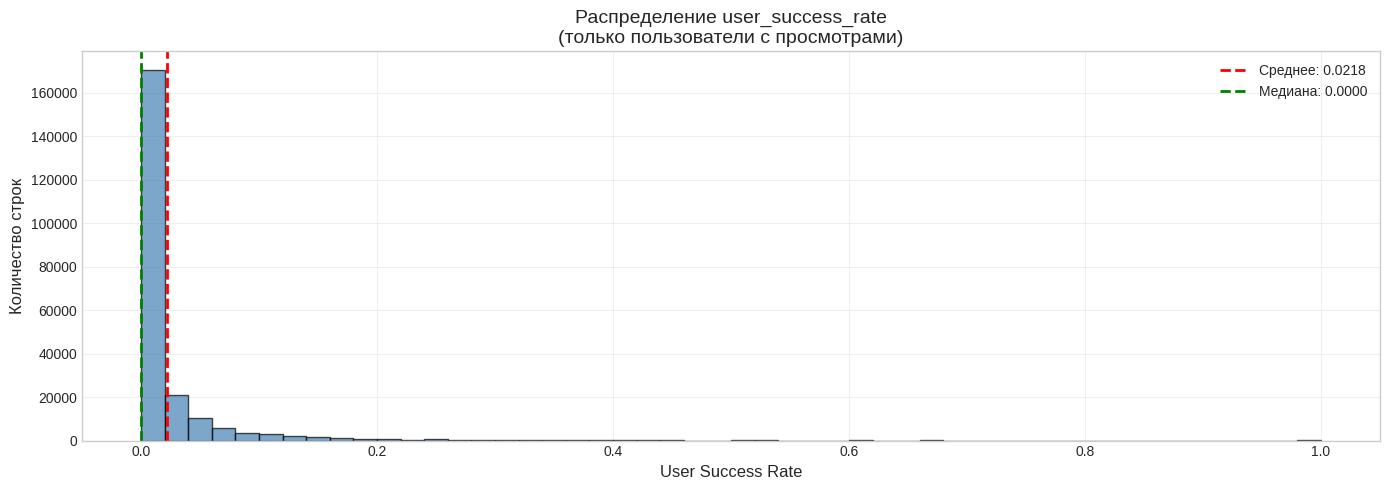


СТАТИСТИКА РАСПРЕДЕЛЕНИЯ USER_SUCCESS_RATE


Всего строк с просмотрами: 223,542
Среднее: 0.021791
Медиана: 0.000000
Стандартное отклонение: 0.061525
Минимум: 0.000000
Максимум: 1.000000

Квантили:
   25.0%: 0.000000
   50.0%: 0.000000
   75.0%: 0.018116
   90.0%: 0.058394
   95.0%: 0.105263
   99.0%: 0.285714

Распределение по диапазонам:
  0           : 150,462 (67.31%) █████████████████████████████████
  0-0.01      : 47,356 (21.18%) ██████████
  0.01-0.05   : 14,055 ( 6.29%) ███
  0.05-0.1    :  7,905 ( 3.54%) █
  0.1-0.2     :  1,789 ( 0.80%) 
  0.2-0.3     :    912 ( 0.41%) 
  0.3-0.4     :    490 ( 0.22%) 
  0.4-0.5     :    159 ( 0.07%) 
  0.5-0.6     :    119 ( 0.05%) 
  0.6-0.7     :     94 ( 0.04%) 
  0.7-0.8     :     20 ( 0.01%) 
  0.8-0.9     :    181 ( 0.08%) 
  0.9-1.0     :      0 ( 0.00%) 


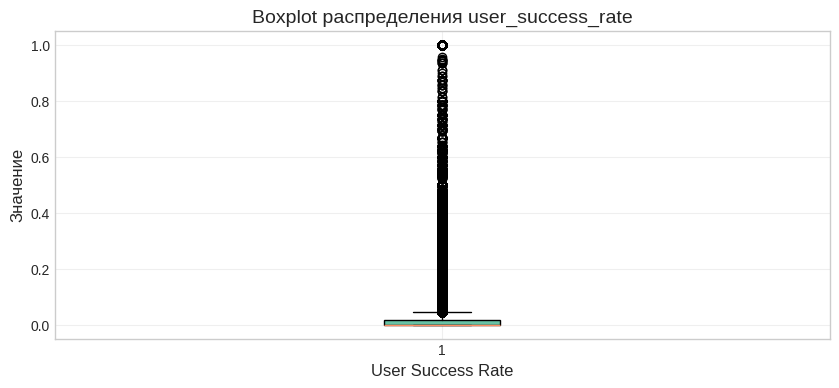

In [ ]:
# Посмотрим на успешные действия пользователей

# Настройка стиля
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")

# Создаем фигуру с одним графиком (не массивом)
fig, ax = plt.subplots(1, 1, figsize=(14, 5))

# Берем только пользователей с просмотрами
success_rates = train_df[train_df['user_total_views'] > 0]['user_success_rate']

ax.hist(success_rates, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
ax.set_xlabel('User Success Rate', fontsize=12)
ax.set_ylabel('Количество строк', fontsize=12)
ax.set_title('Распределение user_success_rate\n(только пользователи с просмотрами)', fontsize=14)
ax.axvline(success_rates.mean(), color='red', linestyle='--', linewidth=2, label=f'Среднее: {success_rates.mean():.4f}')
ax.axvline(success_rates.median(), color='green', linestyle='--', linewidth=2, label=f'Медиана: {success_rates.median():.4f}')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Дополнительная статистика

print("\nСТАТИСТИКА РАСПРЕДЕЛЕНИЯ USER_SUCCESS_RATE\n")

print(f"\nВсего строк с просмотрами: {len(success_rates):,}")
print(f"Среднее: {success_rates.mean():.6f}")
print(f"Медиана: {success_rates.median():.6f}")
print(f"Стандартное отклонение: {success_rates.std():.6f}")
print(f"Минимум: {success_rates.min():.6f}")
print(f"Максимум: {success_rates.max():.6f}")

print(f"\nКвантили:")
for q in [0.25, 0.5, 0.75, 0.9, 0.95, 0.99]:
    print(f"  {q*100:5.1f}%: {success_rates.quantile(q):.6f}")


# Распределение по диапазонам


print(f"\nРаспределение по диапазонам:")
# Количество границ = количество меток + 1
bins = [0, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.01]
# Добавили 1.01, чтобы включить значения = 1.0

labels = ['0', '0-0.01', '0.01-0.05', '0.05-0.1', '0.1-0.2', '0.2-0.3', '0.3-0.4',
          '0.4-0.5', '0.5-0.6', '0.6-0.7', '0.7-0.8', '0.8-0.9', '0.9-1.0']

# Используем pd.cut с правильным количеством границ
train_df['rate_bin'] = pd.cut(train_df['user_success_rate'], bins=bins, labels=labels, include_lowest=True)
bin_counts = train_df[train_df['user_total_views'] > 0]['rate_bin'].value_counts().sort_index()

for label in labels:
    count = bin_counts.get(label, 0)
    pct = count / len(success_rates) * 100
    bar = '█' * int(pct / 2)
    print(f"  {label:12}: {count:6,} ({pct:5.2f}%) {bar}")

# Boxplot

plt.figure(figsize=(10, 4))
plt.boxplot(success_rates, vert=True, patch_artist=True)
plt.xlabel('User Success Rate', fontsize=12)
plt.ylabel('Значение', fontsize=12)
plt.title('Boxplot распределения user_success_rate', fontsize=14)
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# # Старый вариант

# start = time.time()

# warnings.filterwarnings('ignore')

# # Словарь для быстрого доступа к start_at смен
# shift_start_map = dict(zip(shifts_clean['id'], shifts_clean['start_at']))

# # ГРУППА 5: СКОЛЬЗЯЩИЕ ОКНА


# print("\nГРУППА 5: СКОЛЬЗЯЩИЕ ОКНА\n")

# # Создаем словарь user_id -> список дат успехов ТОЛЬКО ДО момента предсказания
# success_by_user = defaultdict(list)

# print("    Сбор данных об успешных действиях...")
# for _, row in tqdm(df_all[df_all['is_successful'] == 1].iterrows(), total=len(df_all[df_all['is_successful'] == 1]), desc="        Обработка успешных действий"):
#     shift_id = row['shift_id']
#     if shift_id in shift_start_map:
#         pred_moment = shift_start_map[shift_id] - timedelta(days=2)
#         if row['ts'] < pred_moment:
#             success_by_user[row['user_id']].append(row['ts'])

# for user_id in success_by_user:
#     success_by_user[user_id] = sorted(success_by_user[user_id])

# def count_success_batch(ts_lists, win_starts, win_ends):
#     results = []
#     for ts_list, w_start, w_end in zip(ts_lists, win_starts, win_ends):
#         if not ts_list:
#             results.append(0)
#         else:
#             start_np = np.datetime64(w_start)
#             end_np = np.datetime64(w_end)
#             left = bisect.bisect_left(ts_list, start_np)
#             right = bisect.bisect_left(ts_list, end_np)
#             results.append(right - left)
#     return results

# for window_days in [7, 14]:
#     print(f"    Окно {window_days} дней...")
#     win_start = train_df['start_at'] - timedelta(days=window_days)
#     win_end = train_df['start_at'] - timedelta(days=WINDOW_END_OFFSET)

#     ts_lists = [success_by_user.get(uid, []) for uid in train_df['user_id']]
#     train_df[f'user_successful_actions_last_{window_days}d'] = count_success_batch(
#         ts_lists, win_start.values, win_end.values
#     )

#     # Для test_df
#     ts_lists_test = [success_by_user.get(uid, []) for uid in test_df['user_id']]
#     test_df[f'user_successful_actions_last_{window_days}d'] = count_success_batch(
#         ts_lists_test, win_start.values, win_end.values
#     )

# print("Добавлены 2 признака")


# # ГРУППА 6: ОПЫТ ПО ТИПУ ЗАДАЧ

# print("\nГРУППА 6: ОПЫТ ПО ТИПУ ЗАДАЧ\n")

# successful_raw = defaultdict(set)
# successful_cat = defaultdict(set)

# print("    Сбор данных об опыте пользователей...")
# for _, row in tqdm(df_all[df_all['is_successful'] == 1].iterrows(), total=len(df_all[df_all['is_successful'] == 1]), desc="        Обработка успешных действий"):
#     shift_id = row['shift_id']
#     if shift_id in shift_start_map:
#         pred_moment = shift_start_map[shift_id] - timedelta(days=2)
#         if row['ts'] < pred_moment:
#             user_id = row['user_id']
#             successful_raw[user_id].add(row['shift_task_type'])
#             successful_cat[user_id].add(row['task_category'])

# def get_experience(row):
#     user_id = row['user_id']
#     task_type = row['task_type']
#     task_cat = row['task_category']
#     raw_exp = 1 if task_type in successful_raw.get(user_id, set()) else 0
#     cat_exp = 1 if task_cat in successful_cat.get(user_id, set()) else 0
#     return raw_exp, cat_exp

# # Для train_df
# print("    Добавление признаков для train...")
# exp_df_train = train_df.progress_apply(get_experience, axis=1, result_type='expand')
# train_df['user_task_type_experience'] = exp_df_train[0]

# # Для test_df
# print("    Добавление признаков для test...")
# exp_df_test = test_df.progress_apply(get_experience, axis=1, result_type='expand')
# test_df['user_task_type_experience'] = exp_df_test[0]

# print(" Добавлен 1 признак (user_task_type_experience)")

# # Признак: были ли успешный опыт у данного работодателя в окне
# user_employers_successful = defaultdict(set)

# print("    Сбор данных об опыте по работодателям...")
# for _, row in tqdm(df_all[df_all['is_successful'] == 1].iterrows(), total=len(df_all[df_all['is_successful'] == 1]), desc="        Обработка успешных действий"):
#     shift_id = row['shift_id']
#     if shift_id in shift_start_map:
#         pred_moment = shift_start_map[shift_id] - timedelta(days=2)
#         if row['ts'] < pred_moment:
#             user_id = row['user_id']
#             employer_id = row['employer_id']
#             user_employers_successful[user_id].add(employer_id)

# def get_employer_experience(row):
#     """Возвращает 1 если у пользователя был успешный выход у данного работодателя в окне [T-30, T-2]"""
#     user_id = row['user_id']
#     employer_id = row['employer_id']
#     return 1 if employer_id in user_employers_successful.get(user_id, set()) else 0

# # Для train_df
# print("    Добавление признаков для train...")
# train_df['user_employer_experience'] = train_df.progress_apply(get_employer_experience, axis=1)

# # Для test_df
# print("    Добавление признаков для test...")
# test_df['user_employer_experience'] = test_df.progress_apply(get_employer_experience, axis=1)

# print("Добавлен 1 признак: user_employer_experience (бинарный)")

# # ГРУППА 7: ПРИЗНАКИ ЗАКАЗЧИКА


# print("\nГРУППА 7: ПРИЗНАКИ ЗАКАЗЧИКА\n")
# print("-" * 40)

# employer_data = defaultdict(lambda: {'shifts': set(), 'rewards': [], 'users': set(), 'system_cancels': set()})

# print("    Сбор статистики по заказчикам...")
# for _, row in tqdm(df_all.iterrows(), total=len(df_all), desc="        Обработка событий"):
#     shift_id = row['shift_id']
#     if shift_id in shift_start_map:
#         pred_moment = shift_start_map[shift_id] - timedelta(days=2)
#         if row['ts'] < pred_moment:
#             emp_id = row['employer_id']
#             employer_data[emp_id]['shifts'].add(shift_id)
#             if pd.notna(row['reward']):
#                 employer_data[emp_id]['rewards'].append(row['reward'])
#             employer_data[emp_id]['users'].add(row['user_id'])
#             if row['interaction'] == 'SYSTEM_CANCEL':
#                 employer_data[emp_id]['system_cancels'].add(shift_id)

# def get_employer_stats(emp_id):
#     data = employer_data.get(emp_id, {})
#     total_shifts = len(data.get('shifts', set()))
#     rewards = data.get('rewards', [])
#     avg_reward = np.mean(rewards) if rewards else 0
#     popularity = len(data.get('users', set()))
#     system_cancels = len(data.get('system_cancels', set()))
#     reliability = 1 - (system_cancels / total_shifts) if total_shifts > 0 else 1
#     reliability = max(0, min(1, reliability))
#     return total_shifts, avg_reward, popularity, reliability

# # Для train_df
# print("    Добавление признаков для train...")
# emp_ids_train = train_df['employer_id'].values
# stats_train = [get_employer_stats(eid) for eid in tqdm(emp_ids_train, desc="        Расчет статистики")]
# train_df['employer_avg_reward'] = [s[1] for s in stats_train]
# train_df['employer_popularity'] = [s[2] for s in stats_train]
# train_df['employer_reliability'] = [s[3] for s in stats_train]

# # Для test_df
# print("    Добавление признаков для test...")
# emp_ids_test = test_df['employer_id'].values
# stats_test = [get_employer_stats(eid) for eid in tqdm(emp_ids_test, desc="        Расчет статистики")]
# test_df['employer_avg_reward'] = [s[1] for s in stats_test]
# test_df['employer_popularity'] = [s[2] for s in stats_test]
# test_df['employer_reliability'] = [s[3] for s in stats_test]

# print("Добавлены 3 признака (employer_avg_reward, employer_popularity, employer_reliability)")


# # ГРУППА 8: ПОПУЛЯРНОСТЬ СМЕНЫ


# print("\n5. ГРУППА 8: ПОПУЛЯРНОСТЬ СМЕНЫ\n")


# shift_applies_views = defaultdict(lambda: [0, 0])

# print("    Сбор статистики по сменам...")
# for _, row in tqdm(df_all.iterrows(), total=len(df_all), desc="        Обработка событий"):
#     shift_id = row['shift_id']
#     if shift_id in shift_start_map:
#         pred_moment = shift_start_map[shift_id] - timedelta(days=2)
#         if row['ts'] < pred_moment:
#             if row['interaction'] == 'APPLY':
#                 shift_applies_views[shift_id][0] += 1
#             elif row['interaction'] == 'VIEW':
#                 shift_applies_views[shift_id][1] += 1

# def add_shift_popularity(df):
#     shift_ids = df['shift_id'].values
#     capacities = df['capacity'].values
#     views_list = [shift_applies_views[sid][1] for sid in shift_ids]

#     df['shift_total_views'] = views_list
#     return df

# train_df = add_shift_popularity(train_df)
# test_df = add_shift_popularity(test_df)

# # APPLY до момента предсказания (используется только для расчета free_spots_at_prediction и is_full_at_prediction)
# print("    Сбор APPLY до момента предсказания...")
# applies_dict = {}
# for shift_id, group in tqdm(df_all[df_all['interaction'] == 'APPLY'].groupby('shift_id'), desc="        Группировка по сменам"):
#     times = []
#     for _, row in group.iterrows():
#         if shift_id in shift_start_map:
#             pred_moment = shift_start_map[shift_id] - timedelta(days=2)
#             if row['ts'] < pred_moment:
#                 times.append(row['ts'])
#     applies_dict[shift_id] = sorted(times)

# def count_applies_before_batch(shift_ids, pred_moments):
#     results = []
#     for sid, pm in zip(shift_ids, pred_moments):
#         ts_list = applies_dict.get(sid, [])
#         if not ts_list:
#             results.append(0)
#         else:
#             results.append(bisect.bisect_left(ts_list, np.datetime64(pm)))
#     return results

# pred_moments = train_df['start_at'] - timedelta(days=2)
# applies_before_for_train = count_applies_before_batch(train_df['shift_id'].values, pred_moments.values)
# train_df['free_spots_at_prediction'] = (train_df['capacity'] - applies_before_for_train).clip(lower=0)
# train_df['is_full_at_prediction'] = (train_df['free_spots_at_prediction'] == 0).astype(int)

# pred_moments_test = test_df['start_at'] - timedelta(days=2)
# applies_before_for_test = count_applies_before_batch(test_df['shift_id'].values, pred_moments_test.values)
# test_df['free_spots_at_prediction'] = (test_df['capacity'] - applies_before_for_test).clip(lower=0)
# test_df['is_full_at_prediction'] = (test_df['free_spots_at_prediction'] == 0).astype(int)

# print("Добавлены 3 признака (shift_total_views, free_spots_at_prediction, is_full_at_prediction)")


# # ГРУППА 9: ВЗАИМОДЕЙСТВИЕ СО СМЕНОЙ


# print("\nГРУППА 9: ВЗАИМОДЕЙСТВИЕ СО СМЕНОЙ\n")

# user_shift_data = defaultdict(lambda: [0, 0])

# print("    Сбор данных о взаимодействии...")
# for _, row in tqdm(df_all.iterrows(), total=len(df_all), desc="        Обработка событий"):
#     shift_id = row['shift_id']
#     if shift_id in shift_start_map:
#         pred_moment = shift_start_map[shift_id] - timedelta(days=2)
#         if row['ts'] < pred_moment:
#             key = (row['user_id'], shift_id)
#             if row['interaction'] == 'VIEW':
#                 user_shift_data[key][0] += 1
#             elif row['is_successful'] == 1:
#                 user_shift_data[key][1] = 1

# def add_shift_interaction(df):
#     keys = list(zip(df['user_id'].values, df['shift_id'].values))
#     views_counts = [user_shift_data.get(k, [0, 0])[0] for k in keys]
#     has_apply = [user_shift_data.get(k, [0, 0])[1] for k in keys]

#     df['view_count_for_shift'] = views_counts
#     df['has_apply_before'] = has_apply
#     return df

# train_df = add_shift_interaction(train_df)
# test_df = add_shift_interaction(test_df)

# print(" Добавлены 2 признака (view_count_for_shift, has_apply_before)")


# # ГРУППА 10-11: ПРЕДПОЧТЕНИЯ ПОЛЬЗОВАТЕЛЯ

# print("\nГРУППА 10-11: ПРЕДПОЧТЕНИЯ ПОЛЬЗОВАТЕЛЯ\n")


# holidays = pd.to_datetime(['2026-01-01', '2026-01-02', '2026-01-03', '2026-01-04', '2026-01-05',
#                            '2026-01-06', '2026-01-07', '2026-01-08', '2026-01-09', '2026-01-10',
#                            '2026-01-11', '2026-02-23', '2026-03-09'])

# user_successful = defaultdict(list)

# print("    Сбор предпочтений пользователей...")
# for _, row in tqdm(df_all[df_all['is_successful'] == 1].iterrows(), total=len(df_all[df_all['is_successful'] == 1]), desc="        Обработка успешных действий"):
#     shift_id = row['shift_id']
#     if shift_id in shift_start_map:
#         pred_moment = shift_start_map[shift_id] - timedelta(days=2)
#         if row['ts'] < pred_moment:
#             shift_start = row['start_at']
#             hour = shift_start.hour
#             is_wd = 0 if shift_start.normalize() in holidays or shift_start.dayofweek >= 5 else 1
#             time_of_day = 'morning' if 6 <= hour < 12 else 'day' if 12 <= hour < 18 else 'evening' if 18 <= hour < 24 else 'night'
#             user_successful[row['user_id']].append({'is_weekday': is_wd, 'time_of_day': time_of_day})

# def get_user_preferences(user_id):
#     data = user_successful.get(user_id, [])
#     if not data:
#         return -1, -1, -1, -1, -1, -1
#     total = len(data)
#     weekday_cnt = sum(1 for d in data if d['is_weekday'] == 1)
#     morning_cnt = sum(1 for d in data if d['time_of_day'] == 'morning')
#     day_cnt = sum(1 for d in data if d['time_of_day'] == 'day')
#     evening_cnt = sum(1 for d in data if d['time_of_day'] == 'evening')
#     night_cnt = sum(1 for d in data if d['time_of_day'] == 'night')
#     return (weekday_cnt / total, 1 - weekday_cnt / total,
#             morning_cnt / total, day_cnt / total,
#             evening_cnt / total, night_cnt / total)

# def add_user_preferences(df):
#     user_ids = df['user_id'].values
#     print(f"        Расчет предпочтений для {len(user_ids)} пользователей...")
#     prefs = [get_user_preferences(uid) for uid in tqdm(user_ids, desc="            Прогресс")]
#     df['user_weekend_ratio'] = [p[1] for p in prefs]
#     df['user_day_ratio'] = [p[3] for p in prefs]
#     df['user_evening_ratio'] = [p[4] for p in prefs]
#     df['user_night_ratio'] = [p[5] for p in prefs]
#     return df

# train_df = add_user_preferences(train_df)
# test_df = add_user_preferences(test_df)

# print("Добавлены 4 признака (user_weekend_ratio, user_day_ratio, user_evening_ratio, user_night_ratio)")

# # ГРУППА 12: СОВПАДЕНИЕ ПРЕДПОЧТЕНИЙ


# print("\nГРУППА 12: СОВПАДЕНИЕ ПРЕДПОЧТЕНИЙ\n")

# def get_match_vectorized(value, ratio, threshold=0.5):
#     result = np.where(ratio == -1, -1, 0)
#     result = np.where((value == 1) & (ratio > threshold), 1, result)
#     return result

# for df in [train_df, test_df]:
#     df['matches_high_paid'] = get_match_vectorized(df['is_high_paid_window'].values, df['user_high_paid_ratio'].values)
#     df['matches_long_shift'] = get_match_vectorized(df['is_long_shift'].values, df['user_long_shift_ratio'].values)
#     df['matches_short_shift'] = get_match_vectorized(df['is_short_shift'].values, df['user_short_shift_ratio'].values)

# print("    Расчет совпадения времени суток...")
# def get_time_match(row):
#     if row['user_day_ratio'] == -1 and row['user_evening_ratio'] == -1 and row['user_night_ratio'] == -1:
#         return -1
#     ratios = [row['user_day_ratio'], row['user_evening_ratio'], row['user_night_ratio']]
#     times = ['day', 'evening', 'night']
#     if max(ratios) == 0:
#         return -1
#     preferred = times[np.argmax(ratios)]
#     return 1 if row['shift_time_of_day'] == preferred else 0

# train_df['matches_time_of_day'] = train_df.progress_apply(get_time_match, axis=1)
# test_df['matches_time_of_day'] = test_df.progress_apply(get_time_match, axis=1)

# for df in [train_df, test_df]:
#     df['matches_location'] = (df['user_location_experience'] > 0).astype(int)

# print("Добавлены 4 признака (matches_high_paid, matches_long_shift, matches_short_shift, matches_time_of_day, matches_location)")

# # ГРУППА 13: ЗАНЯТОСТЬ В ДЕНЬ СМЕНЫ


# print("\nГРУППА 13: ЗАНЯТОСТЬ В ДЕНЬ СМЕНЫ")


# user_day_shifts = defaultdict(list)

# print("    Сбор данных о занятости...")
# for _, row in tqdm(df_all[df_all['is_successful'] == 1].iterrows(), total=len(df_all[df_all['is_successful'] == 1]), desc="        Обработка успешных действий"):
#     shift_id = row['shift_id']
#     if shift_id in shift_start_map:
#         pred_moment = shift_start_map[shift_id] - timedelta(days=2)
#         if row['ts'] < pred_moment:
#             key = (row['user_id'], row['start_at'].date())
#             start_hour = row['start_at'].hour
#             end_hour = start_hour + row['hours']
#             user_day_shifts[key].append((start_hour, end_hour, shift_id))

# def add_occupancy(df):
#     dates = df['start_at'].dt.date
#     start_hours = df['start_at'].dt.hour
#     end_hours = start_hours + df['hours']

#     results = []
#     print(f"        Расчет занятости для {len(df)} строк...")
#     for idx in tqdm(range(len(df)), desc="            Прогресс"):
#         uid = df.iloc[idx]['user_id']
#         sid = df.iloc[idx]['shift_id']
#         date = dates.iloc[idx]
#         sh = start_hours.iloc[idx]
#         eh = end_hours.iloc[idx]

#         key = (uid, date)
#         shifts = user_day_shifts.get(key, [])
#         valid = [(s, e) for s, e, sid2 in shifts if sid2 != sid]

#         if not valid:
#             results.append((0, 0))
#             continue

#         shifts_count = len(valid)
#         total_overlap = 0
#         for s, e in valid:
#             overlap_start = max(sh, s)
#             overlap_end = min(eh, e)
#             if overlap_start < overlap_end:
#                 total_overlap += overlap_end - overlap_start
#         results.append((shifts_count, total_overlap))

#     df['user_shifts_on_same_day'] = [r[0] for r in results]
#     df.loc[df['has_apply_before'] == 1, 'user_shifts_on_same_day'] = -1
#     return df

# train_df = add_occupancy(train_df)
# test_df = add_occupancy(test_df)

# print("Добавлен 1 признак (user_shifts_on_same_day)")


# # ГРУППА 14: ПРИЗНАКИ ВЗАИМОДЕЙСТВИЯ


# print("\nГРУППА 14: ПРИЗНАКИ ВЗАИМОДЕЙСТВИЯ")


# for df in [train_df, test_df]:
#     df['is_full_and_has_apply'] = ((df['is_full_at_prediction'] == 1) & (df['has_apply_before'] == 1)).astype(int)

# print("Добавлен 1 признак (is_full_and_has_apply)")


# # ФИНАЛЬНАЯ ОЧИСТКА И СОХРАНЕНИЕ


# print("\nФИНАЛЬНАЯ ОЧИСТКА И СОХРАНЕНИЕ\n")

# tech_cols = ['id', 'shift_date', 'workplace_id', 'id_differential', 'rate_bin']
# for df in [train_df, test_df]:
#     for col in tech_cols:
#         if col in df.columns:
#             df.drop(columns=[col], inplace=True)

# print("    Сохранение файлов...")
# train_df.to_csv('train_features_final.csv', index=False)
# test_df.to_csv('test_features_final.csv', index=False)

# print(f"\nСохранено: train_features_final.csv, {train_df.shape}")
# print(f"\nСохранено: test_features_final.csv, {test_df.shape}")
# print(f"Всего признаков в train: {len(train_df.columns) - 3}")

# print(f'Время выполнения: {time.time() - start:.2f} сек')

In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225971 entries, 0 to 225970
Data columns (total 43 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   user_id                        225971 non-null  object        
 1   shift_id                       225971 non-null  int64         
 2   target                         225971 non-null  int64         
 3   id                             225971 non-null  int64         
 4   start_at                       225971 non-null  datetime64[ns]
 5   location_id_shift              225971 non-null  int64         
 6   task_type                      225971 non-null  object        
 7   employer_id                    225971 non-null  object        
 8   workplace_id                   225971 non-null  object        
 9   need_mk                        225971 non-null  bool          
 10  id_differential                225971 non-null  bool          
 11  

In [ ]:
# # Оптимизированный вариант

# start = time.time()

# warnings.filterwarnings('ignore')

# # ОДИН ПРОХОД ПО df_all ДЛЯ СБОРА ВСЕХ СЛОВАРЕЙ
# print("ЕДИНЫЙ ПРОХОД ПО df_all...")

# shift_start_map = dict(zip(shifts_clean['id'], shifts_clean['start_at']))

# # Словари для всех групп
# success_by_user        = defaultdict(list)       # группа 5
# successful_raw         = defaultdict(set)         # группа 6
# successful_cat         = defaultdict(set)         # группа 6
# user_employers_successful = defaultdict(set)      # группа 6
# employer_data          = defaultdict(lambda: {'shifts': set(), 'rewards': [], 'users': set(), 'system_cancels': set()})  # группа 7
# shift_applies_views    = defaultdict(lambda: [0, 0])   # группа 8
# applies_dict           = defaultdict(list)        # группа 8
# user_shift_data        = defaultdict(lambda: [0, 0])   # группа 9
# user_day_shifts        = defaultdict(list)        # группа 13
# user_successful        = defaultdict(list)        # группа 10

# holidays_set = set(pd.to_datetime([
#     '2026-01-01', '2026-01-02', '2026-01-03', '2026-01-04', '2026-01-05',
#     '2026-01-06', '2026-01-07', '2026-01-08', '2026-01-09', '2026-01-10',
#     '2026-01-11', '2026-02-23', '2026-03-09'
# ]).normalize())

# for row in tqdm(df_all.itertuples(index=False), total=len(df_all), desc="Единый проход"):
#     shift_id = row.shift_id
#     if shift_id not in shift_start_map:
#         continue

#     pred_moment = shift_start_map[shift_id] - timedelta(days=2)
#     ts          = row.ts
#     user_id     = row.user_id
#     interaction = row.interaction
#     emp_id      = row.employer_id

#     # --- группа 8: статистика смены (все события до предсказания) ---
#     if ts < pred_moment:
#         if interaction == 'APPLY':
#             shift_applies_views[shift_id][0] += 1
#             applies_dict[shift_id].append(ts)
#         elif interaction == 'VIEW':
#             shift_applies_views[shift_id][1] += 1

#         # --- группа 7: статистика работодателя ---
#         employer_data[emp_id]['shifts'].add(shift_id)
#         employer_data[emp_id]['users'].add(user_id)
#         if pd.notna(row.reward):
#             employer_data[emp_id]['rewards'].append(row.reward)
#         if interaction == 'SYSTEM_CANCEL':
#             employer_data[emp_id]['system_cancels'].add(shift_id)

#         # --- группа 9: взаимодействие пользователя со сменой ---
#         key = (user_id, shift_id)
#         if interaction == 'VIEW':
#             user_shift_data[key][0] += 1

#     # --- группы 5, 6, 10, 13: только успешные действия ---
#     if getattr(row, 'is_successful', 0) == 1 and ts < pred_moment:
#         # группа 5 - скользящие окна
#         success_by_user[user_id].append(ts)

#         # группа 6 - опыт по типу задач
#         successful_raw[user_id].add(row.shift_task_type)
#         successful_cat[user_id].add(row.task_category)
#         user_employers_successful[user_id].add(emp_id)

#         # группа 9 - взаимодействие (успешный apply)
#         user_shift_data[(user_id, shift_id)][1] = 1

#         # группа 10 - предпочтения пользователя
#         shift_start = row.start_at
#         hour        = shift_start.hour
#         is_wd       = 0 if shift_start.normalize() in holidays_set or shift_start.dayofweek >= 5 else 1
#         tod         = ('morning' if 6 <= hour < 12 else
#                        'day'     if 12 <= hour < 18 else
#                        'evening' if 18 <= hour < 24 else 'night')
#         user_successful[user_id].append({'is_weekday': is_wd, 'time_of_day': tod})

#         # группа 13 - занятость в день смены
#         key_day    = (user_id, shift_start.date())
#         start_hour = shift_start.hour
#         end_hour   = start_hour + row.hours
#         user_day_shifts[key_day].append((start_hour, end_hour, shift_id))

# # сортируем списки дат
# for uid in success_by_user:
#     success_by_user[uid] = sorted(success_by_user[uid])
# for sid in applies_dict:
#     applies_dict[sid] = sorted(applies_dict[sid])

# print(f"Единый проход завершён за {time.time() - start:.2f} сек")


# # ГРУППА 5: СКОЛЬЗЯЩИЕ ОКНА (векторизованно через bisect)
# print("\nГРУППА 5: СКОЛЬЗЯЩИЕ ОКНА")

# def count_success_batch(ts_lists, win_starts, win_ends):
#     results = []
#     for ts_list, w_start, w_end in zip(ts_lists, win_starts, win_ends):
#         if not ts_list:
#             results.append(0)
#         else:
#             left  = bisect.bisect_left(ts_list, np.datetime64(w_start))
#             right = bisect.bisect_left(ts_list, np.datetime64(w_end))
#             results.append(right - left)
#     return results

# for df_name, df in [('train', train_df), ('test', test_df)]:
#     for window_days in [7, 14]:
#         win_start = df['start_at'] - timedelta(days=window_days)
#         win_end   = df['start_at'] - timedelta(days=WINDOW_END_OFFSET)
#         ts_lists  = [success_by_user.get(uid, []) for uid in df['user_id']]
#         df[f'user_successful_actions_last_{window_days}d'] = count_success_batch(
#             ts_lists, win_start.values, win_end.values
#         )

# print("Добавлены 2 признака")


# # ГРУППА 6: ОПЫТ ПО ТИПУ ЗАДАЧ (через map вместо apply)
# print("\nГРУППА 6: ОПЫТ ПО ТИПУ ЗАДАЧ")

# for df in [train_df, test_df]:
#     df['user_task_type_experience'] = [
#         1 if tt in successful_raw.get(uid, set()) else 0
#         for uid, tt in zip(df['user_id'], df['task_type'])
#     ]
#     df['user_employer_experience'] = [
#         1 if eid in user_employers_successful.get(uid, set()) else 0
#         for uid, eid in zip(df['user_id'], df['employer_id'])
#     ]

# print("Добавлены 2 признака (user_task_type_experience, user_employer_experience)")


# # ГРУППА 7: ПРИЗНАКИ ЗАКАЗЧИКА (из готового словаря)
# print("\nГРУППА 7: ПРИЗНАКИ ЗАКАЗЧИКА")

# def get_employer_stats(emp_id):
#     data          = employer_data.get(emp_id, {})
#     total_shifts  = len(data.get('shifts', set()))
#     rewards       = data.get('rewards', [])
#     avg_reward    = np.mean(rewards) if rewards else 0
#     popularity    = len(data.get('users', set()))
#     sys_cancels   = len(data.get('system_cancels', set()))
#     reliability   = max(0, min(1, 1 - (sys_cancels / total_shifts))) if total_shifts > 0 else 1
#     return avg_reward, popularity, reliability

# for df in [train_df, test_df]:
#     stats = [get_employer_stats(eid) for eid in df['employer_id']]
#     df['employer_avg_reward']   = [s[0] for s in stats]
#     df['employer_popularity']   = [s[1] for s in stats]
#     df['employer_reliability']  = [s[2] for s in stats]

# print("Добавлены 3 признака (employer_avg_reward, employer_popularity, employer_reliability)")


# # ГРУППА 8: ПОПУЛЯРНОСТЬ СМЕНЫ
# print("\nГРУППА 8: ПОПУЛЯРНОСТЬ СМЕНЫ")

# def count_applies_before_batch(shift_ids, pred_moments):
#     results = []
#     for sid, pm in zip(shift_ids, pred_moments):
#         ts_list = applies_dict.get(sid, [])
#         results.append(bisect.bisect_left(ts_list, np.datetime64(pm)) if ts_list else 0)
#     return results

# for df in [train_df, test_df]:
#     df['shift_total_views'] = [shift_applies_views[sid][1] for sid in df['shift_id']]
#     pred_moments            = (df['start_at'] - timedelta(days=2)).values
#     applies_before          = count_applies_before_batch(df['shift_id'].values, pred_moments)
#     df['free_spots_at_prediction'] = (df['capacity'] - np.array(applies_before)).clip(lower=0)
#     df['is_full_at_prediction']    = (df['free_spots_at_prediction'] == 0).astype(int)

# print("Добавлены 3 признака (shift_total_views, free_spots_at_prediction, is_full_at_prediction)")


# # ГРУППА 9: ВЗАИМОДЕЙСТВИЕ СО СМЕНОЙ
# print("\nГРУППА 9: ВЗАИМОДЕЙСТВИЕ СО СМЕНОЙ")

# for df in [train_df, test_df]:
#     keys              = list(zip(df['user_id'].values, df['shift_id'].values))
#     df['view_count_for_shift'] = [user_shift_data.get(k, [0, 0])[0] for k in keys]
#     df['has_apply_before']     = [user_shift_data.get(k, [0, 0])[1] for k in keys]

# print("Добавлены 2 признака (view_count_for_shift, has_apply_before)")


# # ГРУППА 10-11: ПРЕДПОЧТЕНИЯ ПОЛЬЗОВАТЕЛЯ
# print("\nГРУППА 10-11: ПРЕДПОЧТЕНИЯ ПОЛЬЗОВАТЕЛЯ")

# def get_user_preferences(user_id):
#     data = user_successful.get(user_id, [])
#     if not data:
#         return -1, -1, -1, -1
#     total       = len(data)
#     weekend_cnt = sum(1 for d in data if d['is_weekday'] == 0)
#     day_cnt     = sum(1 for d in data if d['time_of_day'] == 'day')
#     evening_cnt = sum(1 for d in data if d['time_of_day'] == 'evening')
#     night_cnt   = sum(1 for d in data if d['time_of_day'] == 'night')
#     return weekend_cnt/total, day_cnt/total, evening_cnt/total, night_cnt/total

# for df in [train_df, test_df]:
#     prefs = [get_user_preferences(uid) for uid in df['user_id']]
#     df['user_weekend_ratio']  = [p[0] for p in prefs]
#     df['user_day_ratio']      = [p[1] for p in prefs]
#     df['user_evening_ratio']  = [p[2] for p in prefs]
#     df['user_night_ratio']    = [p[3] for p in prefs]

# print("Добавлены 4 признака")


# # ГРУППА 12: СОВПАДЕНИЕ ПРЕДПОЧТЕНИЙ
# print("\nГРУППА 12: СОВПАДЕНИЕ ПРЕДПОЧТЕНИЙ")

# def get_match_vectorized(value, ratio, threshold=0.5):
#     result = np.where(ratio == -1, -1, 0)
#     result = np.where((value == 1) & (ratio > threshold), 1, result)
#     return result

# for df in [train_df, test_df]:
#     df['matches_high_paid']   = get_match_vectorized(df['is_high_paid_window'].values, df['user_high_paid_ratio'].values)
#     df['matches_long_shift']  = get_match_vectorized(df['is_long_shift'].values, df['user_long_shift_ratio'].values)
#     df['matches_short_shift'] = get_match_vectorized(df['is_short_shift'].values, df['user_short_shift_ratio'].values)

#     # matches_time_of_day векторизованно
#     no_data  = (df['user_day_ratio'] == -1) & (df['user_evening_ratio'] == -1) & (df['user_night_ratio'] == -1)
#     ratios   = df[['user_day_ratio', 'user_evening_ratio', 'user_night_ratio']].values
#     times    = np.array(['day', 'evening', 'night'])
#     preferred = times[np.argmax(ratios, axis=1)]
#     match    = (df['shift_time_of_day'].values == preferred).astype(int)
#     max_ratio = np.max(ratios, axis=1)
#     df['matches_time_of_day'] = np.where(no_data | (max_ratio == 0), -1, match)

#     df['matches_location'] = (df['user_location_experience'] > 0).astype(int)

# print("Добавлены 5 признаков")


# # ГРУППА 13: ЗАНЯТОСТЬ В ДЕНЬ СМЕНЫ (оптимизированная)
# print("\nГРУППА 13: ЗАНЯТОСТЬ В ДЕНЬ СМЕНЫ")

# def add_occupancy_fast(df):
#     results = []
#     for row in df[['user_id', 'shift_id', 'start_at', 'hours', 'has_apply_before']].itertuples(index=False):
#         uid  = row.user_id
#         sid  = row.shift_id
#         date = row.start_at.date()
#         sh   = row.start_at.hour
#         eh   = sh + row.hours

#         key    = (uid, date)
#         shifts = user_day_shifts.get(key, [])
#         valid  = [(s, e) for s, e, sid2 in shifts if sid2 != sid]   # исключаем саму смену

#         if not valid:
#             results.append(0)
#             continue

#         results.append(len(valid))

#     arr = np.array(results)
#     arr[df['has_apply_before'].values == 1] = -1                     # уже записан - заглушка -1
#     df['user_shifts_on_same_day'] = arr
#     return df

# train_df = add_occupancy_fast(train_df)
# test_df  = add_occupancy_fast(test_df)

# print("Добавлен 1 признак (user_shifts_on_same_day)")


# # ГРУППА 14: ПРИЗНАКИ ВЗАИМОДЕЙСТВИЯ
# print("\nГРУППА 14: ПРИЗНАКИ ВЗАИМОДЕЙСТВИЯ")

# for df in [train_df, test_df]:
#     df['is_full_and_has_apply'] = (
#         (df['is_full_at_prediction'] == 1) & (df['has_apply_before'] == 1)
#     ).astype(int)

# print("Добавлен 1 признак (is_full_and_has_apply)")


# # ФИНАЛЬНАЯ ОЧИСТКА И СОХРАНЕНИЕ
# print("\nФИНАЛЬНАЯ ОЧИСТКА И СОХРАНЕНИЕ")

# tech_cols = ['id', 'shift_date', 'workplace_id', 'id_differential', 'rate_bin']
# for df in [train_df, test_df]:
#     for col in tech_cols:
#         if col in df.columns:
#             df.drop(columns=[col], inplace=True)

# train_df.to_csv('train_features_final_y1.csv', index=False)
# test_df.to_csv('test_features_final_y1.csv', index=False)

# print(f"Сохранено: train_features_final.csv {train_df.shape}")
# print(f"Сохранено: test_features_final.csv  {test_df.shape}")
# print(f"Всего признаков в train: {len(train_df.columns) - 3}")
# print(f"Время выполнения: {time.time() - start:.2f} сек")

In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225971 entries, 0 to 225970
Data columns (total 43 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   user_id                        225971 non-null  object        
 1   shift_id                       225971 non-null  int64         
 2   target                         225971 non-null  int64         
 3   id                             225971 non-null  int64         
 4   start_at                       225971 non-null  datetime64[ns]
 5   location_id_shift              225971 non-null  int64         
 6   task_type                      225971 non-null  object        
 7   employer_id                    225971 non-null  object        
 8   workplace_id                   225971 non-null  object        
 9   need_mk                        225971 non-null  bool          
 10  id_differential                225971 non-null  bool          
 11  

In [ ]:
# Оптимизированный вариант 2

start = time.time()

warnings.filterwarnings('ignore')

# ОДИН ПРОХОД ПО df_all ДЛЯ СБОРА ВСЕХ СЛОВАРЕЙ
print("ЕДИНЫЙ ПРОХОД ПО df_all...")

shift_start_map = dict(zip(shifts_clean['id'], shifts_clean['start_at']))

# Словари для всех групп
success_by_user        = defaultdict(list)       # группа 5
successful_raw         = defaultdict(set)         # группа 6
successful_cat         = defaultdict(set)         # группа 6
user_employers_successful = defaultdict(set)      # группа 6
employer_data          = defaultdict(lambda: {'shifts': set(), 'rewards': [], 'users': set(), 'system_cancels': set()})  # группа 7
shift_applies_views    = defaultdict(lambda: [0, 0])   # группа 8
applies_dict           = defaultdict(list)        # группа 8
user_shift_data        = defaultdict(lambda: [0, 0])   # группа 9
user_day_shifts        = defaultdict(list)        # группа 13
user_successful        = defaultdict(list)        # группа 10

holidays_set = set(pd.to_datetime([
    '2026-01-01', '2026-01-02', '2026-01-03', '2026-01-04', '2026-01-05',
    '2026-01-06', '2026-01-07', '2026-01-08', '2026-01-09', '2026-01-10',
    '2026-01-11', '2026-02-23', '2026-03-09'
]).normalize())

for row in tqdm(df_all.itertuples(index=False), total=len(df_all), desc="Единый проход"):
    shift_id = row.shift_id  # id смены

    # if shift_id not in shift_start_map:
    #     continue

    # pred_moment = shift_start_map[shift_id] - timedelta(days=2)

    shift_id = row.shift_id  # id смены
    shift_start = shift_start_map.get(shift_id)  # получаем старт смены одним обращением

    if shift_start is None:  # если смена отсутствует
        continue  # пропускаем строку

    pred_moment = shift_start - timedelta(days=2)  # момент предсказания

    ts          = row.ts
    user_id     = row.user_id
    interaction = row.interaction
    emp_id      = row.employer_id

    # --- группа 8: статистика смены (все события до предсказания) ---
    if ts < pred_moment:
        if interaction == 'APPLY':
            shift_applies_views[shift_id][0] += 1
            applies_dict[shift_id].append(ts)
        elif interaction == 'VIEW':
            shift_applies_views[shift_id][1] += 1

        # --- группа 7: статистика работодателя ---
        employer_data[emp_id]['shifts'].add(shift_id)
        employer_data[emp_id]['users'].add(user_id)
        if pd.notna(row.reward):
            employer_data[emp_id]['rewards'].append(row.reward)
        if interaction == 'SYSTEM_CANCEL':
            employer_data[emp_id]['system_cancels'].add(shift_id)

        # --- группа 9: взаимодействие пользователя со сменой ---
        key = (user_id, shift_id)
        if interaction == 'VIEW':
            user_shift_data[key][0] += 1

    # --- группы 5, 6, 10, 13: только успешные действия ---
    if getattr(row, 'is_successful', 0) == 1 and ts < pred_moment:
        # группа 5 - скользящие окна
        success_by_user[user_id].append(ts)

        # группа 6 - опыт по типу задач
        successful_raw[user_id].add(row.shift_task_type)
        successful_cat[user_id].add(row.task_category)
        user_employers_successful[user_id].add(emp_id)

        # группа 9 - взаимодействие (успешный apply)
        user_shift_data[(user_id, shift_id)][1] = 1

        # группа 10 - предпочтения пользователя
        shift_start = row.start_at
        hour        = shift_start.hour
        is_wd       = 0 if shift_start.normalize() in holidays_set or shift_start.dayofweek >= 5 else 1
        tod         = ('morning' if 6 <= hour < 12 else
                       'day'     if 12 <= hour < 18 else
                       'evening' if 18 <= hour < 24 else 'night')
        user_successful[user_id].append({'is_weekday': is_wd, 'time_of_day': tod})

        # группа 13 - занятость в день смены
        key_day    = (user_id, shift_start.date())
        start_hour = shift_start.hour
        end_hour   = start_hour + row.hours
        user_day_shifts[key_day].append((start_hour, end_hour, shift_id))

# сортируем списки дат
for uid in success_by_user:
    success_by_user[uid] = sorted(success_by_user[uid])
for sid in applies_dict:
    applies_dict[sid] = sorted(applies_dict[sid])

print(f"Единый проход завершён за {time.time() - start:.2f} сек")

# Предрасчеты
employer_stats_map = {}  # заранее считаем статистики работодателей один раз
for emp_id, data in employer_data.items():  # проходим по каждому работодателю
    total_shifts = len(data.get('shifts', set()))  # считаем число смен
    rewards = data.get('rewards', [])  # берем список оплат
    avg_reward = np.mean(rewards) if rewards else 0  # средняя оплата
    popularity = len(data.get('users', set()))  # число уникальных пользователей
    sys_cancels = len(data.get('system_cancels', set()))  # число системных отмен
    reliability = max(0, min(1, 1 - (sys_cancels / total_shifts))) if total_shifts > 0 else 1  # надежность работодателя
    employer_stats_map[emp_id] = (avg_reward, popularity, reliability)  # сохраняем результат

user_prefs_map = {}  # заранее считаем предпочтения пользователей один раз
for user_id, data in user_successful.items():  # проходим по пользователям
    total = len(data)  # число успешных действий
    weekend_cnt = sum(1 for d in data if d['is_weekday'] == 0)  # число выходных
    day_cnt = sum(1 for d in data if d['time_of_day'] == 'day')  # число дневных смен
    evening_cnt = sum(1 for d in data if d['time_of_day'] == 'evening')  # число вечерних смен
    night_cnt = sum(1 for d in data if d['time_of_day'] == 'night')  # число ночных смен
    user_prefs_map[user_id] = (weekend_cnt / total, day_cnt / total, evening_cnt / total, night_cnt / total)  # сохраняем доли


# ГРУППА 5: СКОЛЬЗЯЩИЕ ОКНА (векторизованно через bisect)
print("\nГРУППА 5: СКОЛЬЗЯЩИЕ ОКНА")

def count_success_batch(ts_lists, win_starts, win_ends):
    results = []
    for ts_list, w_start, w_end in zip(ts_lists, win_starts, win_ends):
        if not ts_list:
            results.append(0)
        else:
            left  = bisect.bisect_left(ts_list, np.datetime64(w_start))
            right = bisect.bisect_left(ts_list, np.datetime64(w_end))
            results.append(right - left)
    return results

for df_name, df in [('train', train_df), ('test', test_df)]:
    for window_days in [7, 14]:
        win_start = df['start_at'] - timedelta(days=window_days)
        win_end   = df['start_at'] - timedelta(days=WINDOW_END_OFFSET)
        ts_lists  = [success_by_user.get(uid, []) for uid in df['user_id']]
        df[f'user_successful_actions_last_{window_days}d'] = count_success_batch(
            ts_lists, win_start.values, win_end.values
        )

print("Добавлены 2 признака")


# ГРУППА 6: ОПЫТ ПО ТИПУ ЗАДАЧ (через map вместо apply)
print("\nГРУППА 6: ОПЫТ ПО ТИПУ ЗАДАЧ")

for df in [train_df, test_df]:
    df['user_task_type_experience'] = [
        1 if tt in successful_raw.get(uid, set()) else 0
        for uid, tt in zip(df['user_id'], df['task_type'])
    ]
    df['user_employer_experience'] = [
        1 if eid in user_employers_successful.get(uid, set()) else 0
        for uid, eid in zip(df['user_id'], df['employer_id'])
    ]

print("Добавлены 2 признака (user_task_type_experience, user_employer_experience)")


# ГРУППА 7: ПРИЗНАКИ ЗАКАЗЧИКА (из готового словаря)
print("\nГРУППА 7: ПРИЗНАКИ ЗАКАЗЧИКА")

for df in [train_df, test_df]:  # добавляем признаки работодателя
    stats = [employer_stats_map.get(eid, (0, 0, 1)) for eid in df['employer_id']]  # берем готовые значения
    df['employer_avg_reward'] = [s[0] for s in stats]  # средняя оплата работодателя
    df['employer_popularity'] = [s[1] for s in stats]  # популярность работодателя
    df['employer_reliability'] = [s[2] for s in stats]  # надежность работодателя

print("Добавлены 3 признака (employer_avg_reward, employer_popularity, employer_reliability)")


# ГРУППА 8: ПОПУЛЯРНОСТЬ СМЕНЫ
print("\nГРУППА 8: ПОПУЛЯРНОСТЬ СМЕНЫ")

def count_applies_before_batch(shift_ids, pred_moments):
    results = []
    for sid, pm in zip(shift_ids, pred_moments):
        ts_list = applies_dict.get(sid, [])
        results.append(bisect.bisect_left(ts_list, np.datetime64(pm)) if ts_list else 0)
    return results

for df in [train_df, test_df]:
    df['shift_total_views'] = [shift_applies_views[sid][1] for sid in df['shift_id']]
    pred_moments            = (df['start_at'] - timedelta(days=2)).values
    applies_before          = count_applies_before_batch(df['shift_id'].values, pred_moments)
    df['free_spots_at_prediction'] = (df['capacity'] - np.array(applies_before)).clip(lower=0)
    df['is_full_at_prediction']    = (df['free_spots_at_prediction'] == 0).astype(int)

print("Добавлены 3 признака (shift_total_views, free_spots_at_prediction, is_full_at_prediction)")


# ГРУППА 9: ВЗАИМОДЕЙСТВИЕ СО СМЕНОЙ
print("\nГРУППА 9: ВЗАИМОДЕЙСТВИЕ СО СМЕНОЙ")

for df in [train_df, test_df]:
    keys              = list(zip(df['user_id'].values, df['shift_id'].values))
    df['view_count_for_shift'] = [user_shift_data.get(k, [0, 0])[0] for k in keys]
    df['has_apply_before']     = [user_shift_data.get(k, [0, 0])[1] for k in keys]

print("Добавлены 2 признака (view_count_for_shift, has_apply_before)")


# ГРУППА 10-11: ПРЕДПОЧТЕНИЯ ПОЛЬЗОВАТЕЛЯ
print("\nГРУППА 10-11: ПРЕДПОЧТЕНИЯ ПОЛЬЗОВАТЕЛЯ")

for df in [train_df, test_df]:  # добавляем предпочтения пользователей
    prefs = [user_prefs_map.get(uid, (-1, -1, -1, -1)) for uid in df['user_id']]  # берем готовые значения
    df['user_weekend_ratio'] = [p[0] for p in prefs]  # доля выходных смен
    df['user_day_ratio'] = [p[1] for p in prefs]  # доля дневных смен
    df['user_evening_ratio'] = [p[2] for p in prefs]  # доля вечерних смен
    df['user_night_ratio'] = [p[3] for p in prefs]  # доля ночных смен

print("Добавлены 4 признака")


# ГРУППА 12: СОВПАДЕНИЕ ПРЕДПОЧТЕНИЙ
print("\nГРУППА 12: СОВПАДЕНИЕ ПРЕДПОЧТЕНИЙ")

def get_match_vectorized(value, ratio, threshold=0.5):
    result = np.where(ratio == -1, -1, 0)
    result = np.where((value == 1) & (ratio > threshold), 1, result)
    return result

for df in [train_df, test_df]:
    df['matches_high_paid']   = get_match_vectorized(df['is_high_paid_window'].values, df['user_high_paid_ratio'].values)
    df['matches_long_shift']  = get_match_vectorized(df['is_long_shift'].values, df['user_long_shift_ratio'].values)
    df['matches_short_shift'] = get_match_vectorized(df['is_short_shift'].values, df['user_short_shift_ratio'].values)

    # matches_time_of_day векторизованно
    no_data  = (df['user_day_ratio'] == -1) & (df['user_evening_ratio'] == -1) & (df['user_night_ratio'] == -1)
    ratios   = df[['user_day_ratio', 'user_evening_ratio', 'user_night_ratio']].values
    times    = np.array(['day', 'evening', 'night'])
    preferred = times[np.argmax(ratios, axis=1)]
    match    = (df['shift_time_of_day'].values == preferred).astype(int)
    max_ratio = np.max(ratios, axis=1)
    df['matches_time_of_day'] = np.where(no_data | (max_ratio == 0), -1, match)

    df['matches_location'] = (df['user_location_experience'] > 0).astype(int)

print("Добавлены 5 признаков")


# ГРУППА 13: ЗАНЯТОСТЬ В ДЕНЬ СМЕНЫ (оптимизированная)
print("\nГРУППА 13: ЗАНЯТОСТЬ В ДЕНЬ СМЕНЫ")

def add_occupancy_fast(df):
    results = []
    for row in df[['user_id', 'shift_id', 'start_at', 'hours', 'has_apply_before']].itertuples(index=False):
        uid  = row.user_id
        sid  = row.shift_id
        date = row.start_at.date()
        sh   = row.start_at.hour
        eh   = sh + row.hours

        key    = (uid, date)
        shifts = user_day_shifts.get(key, [])
        valid  = [(s, e) for s, e, sid2 in shifts if sid2 != sid]   # исключаем саму смену

        if not valid:
            results.append(0)
            continue

        results.append(len(valid))

    arr = np.array(results)
    arr[df['has_apply_before'].values == 1] = -1                     # уже записан - заглушка -1
    df['user_shifts_on_same_day'] = arr
    return df

train_df = add_occupancy_fast(train_df)
test_df  = add_occupancy_fast(test_df)

print("Добавлен 1 признак (user_shifts_on_same_day)")


# ГРУППА 14: ПРИЗНАКИ ВЗАИМОДЕЙСТВИЯ
print("\nГРУППА 14: ПРИЗНАКИ ВЗАИМОДЕЙСТВИЯ")

for df in [train_df, test_df]:
    df['is_full_and_has_apply'] = (
        (df['is_full_at_prediction'] == 1) & (df['has_apply_before'] == 1)
    ).astype(int)

print("Добавлен 1 признак (is_full_and_has_apply)")


# ФИНАЛЬНАЯ ОЧИСТКА И СОХРАНЕНИЕ
print("\nФИНАЛЬНАЯ ОЧИСТКА И СОХРАНЕНИЕ")

tech_cols = ['id', 'shift_date', 'workplace_id', 'id_differential', 'rate_bin']
for df in [train_df, test_df]:
    for col in tech_cols:
        if col in df.columns:
            df.drop(columns=[col], inplace=True)

train_df.to_csv('train_features_final.csv', index=False)
test_df.to_csv('test_features_final.csv', index=False)

print(f"Сохранено: train_features_final.csv {train_df.shape}")
print(f"Сохранено: test_features_final.csv  {test_df.shape}")
print(f"Всего признаков в train: {len(train_df.columns) - 3}")
print(f"Время выполнения: {time.time() - start:.2f} сек")

ЕДИНЫЙ ПРОХОД ПО df_all...


Единый проход: 100%|██████████| 840850/840850 [00:20<00:00, 41254.75it/s]


Единый проход завершён за 20.66 сек

ГРУППА 5: СКОЛЬЗЯЩИЕ ОКНА
Добавлены 2 признака

ГРУППА 6: ОПЫТ ПО ТИПУ ЗАДАЧ
Добавлены 2 признака (user_task_type_experience, user_employer_experience)

ГРУППА 7: ПРИЗНАКИ ЗАКАЗЧИКА
Добавлены 3 признака (employer_avg_reward, employer_popularity, employer_reliability)

ГРУППА 8: ПОПУЛЯРНОСТЬ СМЕНЫ
Добавлены 3 признака (shift_total_views, free_spots_at_prediction, is_full_at_prediction)

ГРУППА 9: ВЗАИМОДЕЙСТВИЕ СО СМЕНОЙ
Добавлены 2 признака (view_count_for_shift, has_apply_before)

ГРУППА 10-11: ПРЕДПОЧТЕНИЯ ПОЛЬЗОВАТЕЛЯ
Добавлены 4 признака

ГРУППА 12: СОВПАДЕНИЕ ПРЕДПОЧТЕНИЙ
Добавлены 5 признаков

ГРУППА 13: ЗАНЯТОСТЬ В ДЕНЬ СМЕНЫ
Добавлен 1 признак (user_shifts_on_same_day)

ГРУППА 14: ПРИЗНАКИ ВЗАИМОДЕЙСТВИЯ
Добавлен 1 признак (is_full_and_has_apply)

ФИНАЛЬНАЯ ОЧИСТКА И СОХРАНЕНИЕ
Сохранено: train_features_final_y2.csv (225971, 62)
Сохранено: test_features_final_y2.csv  (221116, 62)
Всего признаков в train: 59
Время выполнения: 49.06 сек


In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225971 entries, 0 to 225970
Data columns (total 62 columns):
 #   Column                            Non-Null Count   Dtype         
---  ------                            --------------   -----         
 0   user_id                           225971 non-null  object        
 1   shift_id                          225971 non-null  int64         
 2   target                            225971 non-null  int64         
 3   start_at                          225971 non-null  datetime64[ns]
 4   location_id_shift                 225971 non-null  int64         
 5   task_type                         225971 non-null  object        
 6   employer_id                       225971 non-null  object        
 7   need_mk                           225971 non-null  bool          
 8   hours                             225971 non-null  int64         
 9   reward                            225971 non-null  float64       
 10  capacity                        

### Анализ признаков

#### Посмотрим на дисбаланс в распределении признаков

In [ ]:
print("ПОИСК ПРИЗНАКОВ С ДОМИНИРУЮЩИМ ЗНАЧЕНИЕМ (>99%)")


# Загружаем данные
train_df = pd.read_csv('train_features_final.csv')
train_df['start_at'] = pd.to_datetime(train_df['start_at'])

# Исключаем идентификаторы и целевые колонки
exclude_cols = ['user_id', 'shift_id', 'target', 'start_at', 'location_id_shift',
                'task_type', 'employer_id', 'location_id_user', 'system_cancel_shifts']

# Все остальные колонки
all_feature_cols = [col for col in train_df.columns if col not in exclude_cols]

print(f"Всего анализируемых признаков: {len(all_feature_cols)}")
print(f"Всего строк: {len(train_df):,}")


dominant_features = []

for col in all_feature_cols:
    # Получаем уникальные значения и их частоты
    value_counts = train_df[col].value_counts()
    total_count = len(train_df)

    # Проверяем для каждого значения
    for value, count in value_counts.items():
        percentage = count / total_count * 100
        if percentage > 99:  # >99% значений одинаковые
            dominant_features.append({
                'Признак': col,
                'Тип': train_df[col].dtype,
                'Доминирующее значение': value,
                'Количество': count,
                'Процент': percentage,
                'Уникальных значений': len(value_counts),
                'Второе значение (если есть)': value_counts.index[1] if len(value_counts) > 1 else None,
                'Процент второго': value_counts.iloc[1] / total_count * 100 if len(value_counts) > 1 else None
            })
            break  # берем только самое частое значение


if len(dominant_features) == 0:
    print("\nНе найдено признаков с доминирующим значением (>99%)")
else:
    print(f"\nНайдено признаков с доминирующим значением (>99%): {len(dominant_features)}\n")

    for feat in dominant_features:
        print(f"\n {feat['Признак']}")
        print(f"   Тип: {feat['Тип']}")
        print(f"   Доминирующее значение: {feat['Доминирующее значение']}")
        print(f"   Встречается: {feat['Количество']:,} раз ({feat['Процент']:.2f}%)")
        print(f"   Уникальных значений: {feat['Уникальных значений']}")
        if feat['Второе значение (если есть)'] is not None:
            print(f"   Второе значение: {feat['Второе значение (если есть)']} ({feat['Процент второго']:.2f}%)")


print("\nПРИЗНАКИ С СИЛЬНЫМ ДИСБАЛАНСОМ (90-99%)\n")

imbalanced_features = []

for col in all_feature_cols:
    value_counts = train_df[col].value_counts()
    total_count = len(train_df)

    max_count = value_counts.iloc[0]
    max_pct = max_count / total_count * 100

    if 90 <= max_pct < 99:
        imbalanced_features.append({
            'Признак': col,
            'Доминирующее значение': value_counts.index[0],
            'Процент': max_pct,
            'Уникальных значений': len(value_counts)
        })

if len(imbalanced_features) > 0:
    print(f"\nНайдено признаков с дисбалансом (90-99%): {len(imbalanced_features)}")
    for feat in imbalanced_features[:20]:  # покажем первые 20
        print(f"   {feat['Признак']:40s} : {feat['Процент']:.2f}% -> {feat['Доминирующее значение']}")
else:
    print("\nНет признаков с дисбалансом в диапазоне 90-99%")

ПОИСК ПРИЗНАКОВ С ДОМИНИРУЮЩИМ ЗНАЧЕНИЕМ (>99%)
Всего анализируемых признаков: 54
Всего строк: 225,971

Найдено признаков с доминирующим значением (>99%): 3


 is_short_shift
   Тип: int64
   Доминирующее значение: 0
   Встречается: 225,324 раз (99.71%)
   Уникальных значений: 2
   Второе значение: 1 (0.29%)

 has_apply_before
   Тип: int64
   Доминирующее значение: 0
   Встречается: 223,913 раз (99.09%)
   Уникальных значений: 2
   Второе значение: 1 (0.91%)

 is_full_and_has_apply
   Тип: int64
   Доминирующее значение: 0
   Встречается: 224,254 раз (99.24%)
   Уникальных значений: 2
   Второе значение: 1 (0.76%)

ПРИЗНАКИ С СИЛЬНЫМ ДИСБАЛАНСОМ (90-99%)


Найдено признаков с дисбалансом (90-99%): 3
   has_mk                                   : 92.05% -> True
   user_successful_actions_last_7d          : 90.56% -> 0
   user_shifts_on_same_day                  : 97.56% -> 0


## Выводы по анализу дисбаланса признаков

---

### 1. Общая статистика

| Показатель | Значение |
|------------|----------|
| Признаков с доминирующим значением (>99%) | 3 |
| Признаков с сильным дисбалансом (90-99%) | 3 |

---

### 2. Признаки с доминирующим значением (>99%)

| Признак | Доминирующее значение | Доля | Второе значение | Доля второго |
|---------|----------------------|------|-----------------|--------------|
| `is_short_shift` | 0 | 99.71% | 1 | 0.29% |
| `has_apply_before` | 0 | 99.09% | 1 | 0.91% |
| `is_full_and_has_apply` | 0 | 99.24% | 1 | 0.76% |

#### Рекомендации:

| Признак | Рекомендация | Обоснование |
|---------|--------------|-------------|
| `is_short_shift` | ❌ **Удалить** | Только 0.29% смен являются короткими. Признак не даст обобщающей способности и может привести к переобучению |
| `has_apply_before` | ⚠️ **Оставить с осторожностью** | Высокая предсказательная сила (corr=0.64), но есть частичный target-leakage|
| `is_full_and_has_apply` | ⚠️ **Оставить с осторожностью** | Производный от `has_apply_before` и `is_full_at_prediction`, аналогичные риски |

---

### 3. Признаки с сильным дисбалансом (90-99%)

| Признак | Доминирующее значение | Доля | Комментарий |
|---------|----------------------|------|-------------|
| `has_mk` | True | 92.05% | У большинства пользователей есть медкнижка |
| `user_successful_actions_last_7d` | 0 | 90.56% | Большинство пользователей не имеют успешных действий за последние 7 дней |
| `user_shifts_on_same_day` | 0 | 97.56% | В большинстве случаев нет пересекающихся смен |

#### Рекомендации:

| Признак | Рекомендация | Обоснование |
|---------|--------------|-------------|
| `has_mk` | ✅ **Оставить** | Дисбаланс не критичен (92%). Признак коррелирует с target |
| `user_successful_actions_last_7d` | ✅ **Оставить** | Дисбаланс обусловлен реальностью (мало успешных действий). Признак коррелирует с target |
| `user_shifts_on_same_day` | ✅ **Оставить** | Значение 0 — это норма (нет пересечений). Признак имеет высокую предсказательную силу через заглушку -1 |

---

### 4. Сводная таблица решений

| Признак | Дисбаланс | Рекомендация |
|---------|-----------|--------------|
| `is_short_shift` | 99.71% | ❌ Удалить |
| `has_apply_before` | 99.09% | ⚠️ Оставить (осторожно) |
| `is_full_and_has_apply` | 99.24% | ⚠️ Оставить (осторожно)
| `has_mk` | 92.05% | ✅ Оставить |
| `user_successful_actions_last_7d` | 90.56% | ✅ Оставить |
| `user_shifts_on_same_day` | 97.56% | ✅ Оставить |

---

### 5. Итоговые рекомендации

1. **Удалить `is_short_shift`** — признак неинформативен из-за крайнего дисбаланса

2. **Для моделей, чувствительных к дисбалансу** (логистическая регрессия):
   - Рассмотреть взвешивание классов
   - Или использовать SMOTE для балансировки

3. **Для градиентного бустинга** (LightGBM/CatBoost):
   - Можно оставить все признаки, кроме `is_short_shift`
   - Дисбаланс не критичен — деревья устойчивы

4. **Особое внимание `has_apply_before`:**
   - Признак имеет корреляцию 0.64 с target
   - Но этот признак практически является значением targeta (условный target-leakage.)
   - обсудитьт с куратором
  
---

### 6. Заключение

**Дисбаланс в признаках является отражением реального поведения пользователей:**
- Большинство пользователей не имеют успешных действий
- Большинство смен не являются короткими
- Большинство пользователей имеют медкнижку

**Это не ошибка, а особенность данных.** За исключением `is_short_shift`, остальные признаки можно оставить в модели.

Анализ тесноты связи с таргетом и наличия коррелирующих между собой признаков

In [ ]:
print("\nПОЛНЫЙ СТАТИСТИЧЕСКИЙ АНАЛИЗ ВСЕХ ПРИЗНАКОВ\n")

# Загружаем данные
train_df = pd.read_csv('train_features_final.csv')
train_df['start_at'] = pd.to_datetime(train_df['start_at'])


# 1. КЛАССИФИКАЦИЯ ПРИЗНАКОВ

print("\n1. КЛАССИФИКАЦИЯ ПРИЗНАКОВ\n")


# Исключаем идентификаторы
exclude_cols = ['user_id', 'shift_id', 'target', 'start_at', 'location_id_shift',
                'employer_id', 'location_id_user', 'task_type']

# Непрерывные числовые признаки (исключены: employer_total_shifts, shift_total_applies,
# shift_competition, applies_before_prediction, user_overlap_hours, pay_ratio_to_window_median)
continuous_cols = [
    'hours', 'reward', 'reward_per_hour', 'capacity',
    'user_total_views', 'user_total_successful_actions', 'user_success_rate',
    'user_active_days', 'user_unique_employers', 'user_unique_task_types',
    'user_location_experience', 'user_high_paid_ratio', 'user_long_shift_ratio',
    'user_short_shift_ratio', 'user_avg_reward_per_hour',
    'user_successful_actions_last_7d', 'user_successful_actions_last_14d',
    'employer_avg_reward', 'employer_popularity', 'employer_reliability',
    'shift_total_views', 'free_spots_at_prediction',
    'view_count_for_shift', 'user_shifts_on_same_day',
    'median_pay_window'
]

# Бинарные признаки (только 0/1) (исключены: has_viewed_before, is_full_and_no_apply, user_task_category_experience)
binary_cols = [
    'need_mk', 'is_long_shift', 'is_short_shift', 'is_weekday',
    'mk_match', 'location_match', 'has_apply_before',
    'is_full_at_prediction', 'is_high_paid_window', 'is_full_and_has_apply',
    'user_task_type_experience', 'user_employer_experience'
]

# Бинарные признаки с заглушкой -1 (три состояния: -1, 0, 1)
# (исключены: matches_weekday, matches_weekend, matches_task_category)
binary_with_minus_one_cols = [
    'matches_high_paid', 'matches_long_shift', 'matches_short_shift',
    'matches_time_of_day', 'matches_location'
]

# Предпочтения с заглушкой -1 (непрерывные с -1)
# (исключены: user_weekday_ratio, user_morning_ratio)
preference_cols = [
    'user_weekend_ratio', 'user_day_ratio', 'user_evening_ratio', 'user_night_ratio'
]

# Категориальные признаки
categorical_cols = [
    'shift_time_of_day', 'task_category', 'shift_day_of_week', 'shift_hour'
]

# Признаки сдвига занятости (специальная обработка) (исключен user_overlap_hours)
occupancy_cols = ['user_shifts_on_same_day']

# Добавленный признак
additional_cols = ['mk_match_2']

print(f"Непрерывных: {len(continuous_cols)}")
print(f"Бинарных (0/1): {len(binary_cols)}")
print(f"Бинарных с -1: {len(binary_with_minus_one_cols)}")
print(f"Предпочтений с -1: {len(preference_cols)}")
print(f"Категориальных: {len(categorical_cols)}")
print(f"Дополнительных: {len(additional_cols)}")


# 2. ФУНКЦИИ ДЛЯ СТАТИСТИЧЕСКИХ ТЕСТОВ

def cramers_v(confusion_matrix):
    """Рассчитывает Cramer's V для меры силы связи"""
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    return np.sqrt(chi2 / (n * min(r-1, k-1)))

def chi_square_test(df, feature, target='target'):
    """Chi-square тест для категориального признака vs target"""
    contingency = pd.crosstab(df[feature], df[target])
    chi2, p, dof, expected = chi2_contingency(contingency)
    v = cramers_v(contingency.values)
    return chi2, p, v


# 3. НЕПРЕРЫВНЫЕ ПРИЗНАКИ (Point-biserial correlation)

print("\n2. НЕПРЕРЫВНЫЕ ПРИЗНАКИ (Point-biserial correlation)\n")

from scipy.stats import pointbiserialr

continuous_results = []
for col in continuous_cols:
    if col in train_df.columns:
        # Заменяем -1 на NaN для корреляции
        clean_series = train_df[col].replace(-1, np.nan)
        mask = ~clean_series.isna()
        if mask.sum() > 1:
            corr = pointbiserialr(clean_series[mask], train_df.loc[mask, 'target'])[0]
            continuous_results.append((col, corr))

continuous_results.sort(key=lambda x: -abs(x[1]))

print("\nТОП-15 ПО КОРРЕЛЯЦИИ (по модулю):")
for i, (col, corr) in enumerate(continuous_results[:15], 1):
    print(f"  {i:2}. {col:40s} : {corr:8.4f}")

# 4. БИНАРНЫЕ ПРИЗНАКИ (0/1) - ТОЛЬКО CHI-SQUARE И CRAMER'S V

print("\n3. БИНАРНЫЕ ПРИЗНАКИ (0/1)\n")

binary_results = []
for col in binary_cols:
    if col in train_df.columns:
        # Chi-square test
        chi2, p, v = chi_square_test(train_df, col)

        # Доля target по значениям
        target_when_1 = train_df[train_df[col] == 1]['target'].mean()
        target_when_0 = train_df[train_df[col] == 0]['target'].mean()
        count_1 = (train_df[col] == 1).sum()
        count_0 = (train_df[col] == 0).sum()

        binary_results.append((col, p, v))

        print(f"\n  {col}:")
        print(f"    Chi-square p-value: {p:.6f} {'Есть статистически значимая связь' if p < 0.05 else 'Не значимо (рассмотреть исключение из модели)'}")
        print(f"    Cramer's V: {v:.4f}")
        print(f"    При 1 ({count_1:,}): target=1 в {target_when_1:.2%}")
        print(f"    При 0 ({count_0:,}): target=1 в {target_when_0:.2%}")

# 5. ДОПОЛНИТЕЛЬНЫЙ ПРИЗНАК mk_match_2 (3 состояния)

print("\n4. ДОПОЛНИТЕЛЬНЫЙ ПРИЗНАК: mk_match_2\n")

if 'mk_match_2' in train_df.columns:
    contingency = pd.crosstab(train_df['mk_match_2'], train_df['target'])
    chi2, p, dof, expected = chi2_contingency(contingency)
    v = cramers_v(contingency.values)

    print(f"\n  mk_match_2:")
    print(f"    Chi-square p-value: {p:.6f} {'Есть статистически значимая связь' if p < 0.05 else 'Не значимо'}")
    print(f"    Cramer's V: {v:.4f}")

    for val in [0, 1, 2]:
        count = (train_df['mk_match_2'] == val).sum()
        if count > 0:
            target_mean = train_df[train_df['mk_match_2'] == val]['target'].mean()
            if val == 0:
                print(f"    0 (нужна, но нет):   {count:6,} шт → target=1 в {target_mean:.2%}")
            elif val == 1:
                print(f"    1 (нужна и есть):   {count:6,} шт → target=1 в {target_mean:.2%}")
            else:
                print(f"    2 (не нужна):       {count:6,} шт → target=1 в {target_mean:.2%}")

# 6. БИНАРНЫЕ ПРИЗНАКИ С ЗАГЛУШКОЙ -1

print("\n5. БИНАРНЫЕ ПРИЗНАКИ С ЗАГЛУШКОЙ -1\n")

for col in binary_with_minus_one_cols:
    if col in train_df.columns:
        # Chi-square test для всех трех категорий
        contingency = pd.crosstab(train_df[col], train_df['target'])
        chi2, p, dof, expected = chi2_contingency(contingency)
        v = cramers_v(contingency.values)

        print(f"\n  {col}:")
        print(f"    Chi-square p-value: {p:.6f} {'Есть статистически значимая связь' if p < 0.05 else 'Не значимо (рассмотреть исключение из модели)'}")
        print(f"    Cramer's V: {v:.4f}")

        for val in [-1, 0, 1]:
            count = (train_df[col] == val).sum()
            if count > 0:
                target_mean = train_df[train_df[col] == val]['target'].mean()
                if val == -1:
                    print(f"    -1 (нет данных):    {count:6,} шт → target=1 в {target_mean:.2%}")
                elif val == 0:
                    print(f"     0 (не совпадает):  {count:6,} шт → target=1 в {target_mean:.2%}")
                else:
                    print(f"     1 (совпадает):    {count:6,} шт → target=1 в {target_mean:.2%}")


# 7. ПРЕДПОЧТЕНИЯ С ЗАГЛУШКОЙ -1

print("\n6. ПРЕДПОЧТЕНИЯ С ЗАГЛУШКОЙ -1\n")


for col in preference_cols:
    if col in train_df.columns:
        print(f"\n  {col}:")

        # Статистика для -1
        minus_one_mask = train_df[col] == -1
        count_minus_one = minus_one_mask.sum()
        target_minus_one = train_df[minus_one_mask]['target'].mean() if count_minus_one > 0 else 0
        print(f"    -1 (нет данных): {count_minus_one:6,} шт → target=1 в {target_minus_one:.2%}")

        # Анализ для значений без -1
        clean_mask = train_df[col] != -1
        clean_data = train_df[clean_mask][col]

        if len(clean_data) > 1:
            # Point-biserial correlation без -1 (для непрерывной части)
            corr = pointbiserialr(clean_data, train_df.loc[clean_mask, 'target'])[0]
            print(f"    Point-biserial corr (без -1): {corr:.4f}")

            # Квантили
            q25 = clean_data.quantile(0.25)
            q50 = clean_data.quantile(0.50)
            q75 = clean_data.quantile(0.75)
            print(f"    Квантили (без -1): 25%={q25:.2f}, 50%={q50:.2f}, 75%={q75:.2f}")


# 8. КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ


print("\n7. КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ\n")

for col in categorical_cols:
    if col in train_df.columns:
        # Chi-square test
        chi2, p, v = chi_square_test(train_df, col)

        print(f"\n  {col}:")
        print(f"    Chi-square p-value: {p:.6f} {'Есть статистически значимая связь' if p < 0.05 else 'Не значимо (рассмотреть исключение из модели)'}")
        print(f"    Cramer's V: {v:.4f}")

        # Статистика по категориям
        category_stats = train_df.groupby(col)['target'].agg(['mean', 'count']).sort_values('mean', ascending=False)
        for cat, row in category_stats.iterrows():
            cat_str = str(cat)[:20]
            print(f"    {cat_str:20s}: target=1 в {row['mean']:.2%}, кол-во={int(row['count']):,}")


# 9. ПРИЗНАКИ ЗАНЯТОСТИ

print("\n8. ПРИЗНАКИ ЗАНЯТОСТИ\n")


for col in occupancy_cols:
    if col in train_df.columns:
        print(f"\n  {col}:")

        # Chi-square test для всех значений
        contingency = pd.crosstab(train_df[col], train_df['target'])
        chi2, p, dof, expected = chi2_contingency(contingency)
        v = cramers_v(contingency.values)

        print(f"    Chi-square p-value: {p:.6f} {'Есть статистически значимая связь' if p < 0.05 else 'Не значимо (рассмотреть исключение из модели)'}")
        print(f"    Cramer's V: {v:.4f}")

        for val in sorted(train_df[col].unique()):
            count = (train_df[col] == val).sum()
            if count > 0:
                target_mean = train_df[train_df[col] == val]['target'].mean()
                if val == -1:
                    print(f"    -1 (уже записан): {count:6,} шт → target=1 в {target_mean:.2%}")
                else:
                    print(f"    {val:2} (пересечений): {count:6,} шт → target=1 в {target_mean:.2%}")

# 10. ИТОГОВАЯ СВОДКА


print("\n9. ИТОГОВАЯ СВОДКА\n")

summary_data = []

# Собираем лучшие признаки по Cramer's V
for col in binary_cols + binary_with_minus_one_cols + categorical_cols + occupancy_cols + ['mk_match_2']:
    if col in train_df.columns:
        try:
            contingency = pd.crosstab(train_df[col], train_df['target'])
            v = cramers_v(contingency.values)
            chi2, p, dof, expected = chi2_contingency(contingency)
            summary_data.append({
                'Признак': col,
                'Тип': 'categorical/multiclass',
                'Cramers_V': v,
                'p_value': p,
                'Значимо': 'Есть статистически значимая связь' if p < 0.05 else 'Не значимо (рассмотреть исключение из модели)'
            })
        except:
            pass

# Добавляем лучшие непрерывные
for col, corr in continuous_results[:10]:
    summary_data.append({
        'Признак': col,
        'Тип': 'continuous',
        'Correlation': corr,
        'p_value': '-',
        'Значимо': '-'
    })

summary_df = pd.DataFrame(summary_data)

# Сортируем по силе связи
if 'Cramers_V' in summary_df.columns:
    summary_df = summary_df.sort_values('Cramers_V', ascending=False)
else:
    summary_df = summary_df.sort_values('Correlation', ascending=False)

print("\nТОП-20 ПРИЗНАКОВ ПО СИЛЕ СВЯЗИ:")
for i in range(min(20, len(summary_df))):
    row = summary_df.iloc[i]
    if 'Cramers_V' in row and pd.notna(row['Cramers_V']):
        print(f"  {i+1:2}. {row['Признак']:40s} : Cramer's V={row['Cramers_V']:.4f} {row['Значимо']}")
    elif 'Correlation' in row and pd.notna(row['Correlation']):
        print(f"  {i+1:2}. {row['Признак']:40s} : Correlation={row['Correlation']:.4f}")


ПОЛНЫЙ СТАТИСТИЧЕСКИЙ АНАЛИЗ ВСЕХ ПРИЗНАКОВ


1. КЛАССИФИКАЦИЯ ПРИЗНАКОВ

Непрерывных: 25
Бинарных (0/1): 12
Бинарных с -1: 5
Предпочтений с -1: 4
Категориальных: 4
Дополнительных: 1

2. НЕПРЕРЫВНЫЕ ПРИЗНАКИ (Point-biserial correlation)


ТОП-15 ПО КОРРЕЛЯЦИИ (по модулю):
   1. user_success_rate                        :   0.2838
   2. user_successful_actions_last_7d          :   0.2047
   3. user_successful_actions_last_14d         :   0.1679
   4. user_total_successful_actions            :   0.1458
   5. user_location_experience                 :   0.1336
   6. shift_total_views                        :  -0.0768
   7. user_total_views                         :  -0.0759
   8. view_count_for_shift                     :  -0.0738
   9. employer_reliability                     :   0.0359
  10. user_avg_reward_per_hour                 :   0.0358
  11. hours                                    :  -0.0315
  12. capacity                                 :   0.0315
  13. user_unique_task_types  

## Выводы по результатам статистического анализа

---

### 1. КЛЮЧЕВЫЕ НАХОДКИ

#### 🔴 Практически детерминированные предикторы (Cramer's V ≈ 0.64)

| Признак | Значение | Интерпретация |
|---------|----------|----------------|
| `has_apply_before = 1` | target = 100% | Если пользователь уже записался на эту смену, он гарантированно выйдет |
| `user_shifts_on_same_day = -1` | target = 100% | Пользователь уже записан на эту смену |

**Высокая корреляция** этих признаков обусловлена тем, что у части пользователей на дату предсказания (за 2 дня до смены) уже есть запись на данную смену. **Это нужно будет учесть при выводе топа пользователей для рекомендации смены** — уже записавшихся пользователей следует исключать из рекомендаций.
**Также обсудить с куратором в целом использование этих признаков для задачи**

---

#### 🟢 Сильные предикторы (Cramer's V: 0.10-0.16)

| Признак | Cramer's V | Эффект |
|---------|------------|--------|
| `user_employer_experience` | 0.1606 | Опыт у работодателя даёт target 6.21% vs 0.82% |
| `matches_location` | 0.1531 | Совпадение локации повышает target с 0.57% до 5.28% |
| `user_task_type_experience` | 0.1512 | Опыт с типом задачи даёт target 5.93% vs 0.88% |
| `matches_high_paid` | 0.1228 | Совпадение по высокой оплате даёт target 5.80% vs 0.58% |
| `matches_long_shift` | 0.1174 | Совпадение по длинным сменам даёт target 4.40% vs 0.58% |
| `matches_short_shift` | 0.1167 | Совпадение по коротким сменам даёт target 25.53% (47 смен) |
| `matches_time_of_day` | 0.0946 | Совпадение по времени суток даёт target 6.97% vs 1.65% |

**Вывод:** Опыт пользователя (работодатель, тип задачи, локация) и совпадение предпочтений — **второй по значимости класс признаков**.

---

#### 🟡 Средние предикторы

| Признак | Значение | Комментарий |
|---------|----------|-------------|
| `user_success_rate` | 0.2838 | Самый сильный непрерывный признак |
| `user_successful_actions_last_7d` | 0.2047 | Свежая активность важнее общей истории |
| `user_total_successful_actions` | 0.1458 | Общая история тоже важна |
| `user_location_experience` | 0.1336 | Опыт в конкретной локации |
| `shift_total_views` | -0.0768 | Чем больше просмотров смены, тем меньше записей |
| `view_count_for_shift` | -0.0738 | Многократный просмотр смены → снижение вероятности |
| `user_total_views` | -0.0759 | Много просмотров → ниже вероятность записи |

---

#### 🔵 Слабые, но значимые признаки

| Признак | Значение | Комментарий |
|---------|----------|-------------|
| `is_full_at_prediction` | 0.0610 | Если смена уже заполнена → target 3.84% vs 1.71% |
| `task_category` | Cramer's V=0.0550 | `delivery_walk` (4.65%) и `delivery_car` (4.12%) — самые востребованные |
| `shift_hour` | Cramer's V=0.0366 | Часы смен различаются по популярности и таргету |
| `mk_match_2` | Cramer's V=0.0336 | Трёхстадийный признак медкнижки |
| `location_match` | 0.0282 | Совпадение локации увеличивает вероятность |
| `shift_time_of_day` | Cramer's V=0.0271 | Ночные смены дают target 3.68% vs 1.64% (вечер) |
| `is_long_shift` | 0.0217 | Короткие смены (до 8ч) дают выше вероятность |
| `mk_match` | 0.0195 | Совпадение медкнижки даёт небольшой эффект |
| `need_mk` | 0.0179 | Наличие требования медкнижки снижает вероятность |
| `is_high_paid_window` | 0.0068 | Слабая связь, но значимая |

---

#### ⚪ Незначимые признаки (рекомендуется исключить)

| Признак | p-value | Cramer's V | Причина |
|---------|---------|------------|---------|
| `is_short_shift` | 0.243 | 0.0025 | Очень мало смен (647), эффект нестабилен |
| `is_weekday` | 0.382 | 0.0018 | Почти нет разницы (2.17% vs 2.23%) |
| `shift_day_of_week` | 0.248 | 0.0059 | Вариация между днями минимальна (2.10%-2.31%) |

---

### 2. НЕТРИВИАЛЬНЫЕ НАХОДКИ

#### 🧩 Парадокс популярных смен
- `shift_total_views` имеет **отрицательную корреляцию** (-0.0768)
- Чем больше просмотров, тем **ниже** вероятность записи
- **Вероятная причина:** популярные смены быстро заполняются, и пользователь не успевает записаться

#### 🧩 Многократный просмотр — негативный сигнал
- `view_count_for_shift` имеет отрицательную корреляцию (-0.0738)
- Пользователь, который многократно просматривает смену, но не записывается, вероятно, **колеблется или отказался осознанно**

#### 🧩 Очень короткие смены (matches_short_shift = 1)
- Даёт аномально высокий target (25.53%)
- Но таких смен всего 47 — **статистический артефакт**, не полагаться на этот признак

#### 🧩 Опыт важнее общей активности
- `user_employer_experience` (6.21%) и `user_task_type_experience` (5.93%) дают более высокий target, чем пользователи с высоким `user_success_rate`
- **Вывод:** точечный опыт важнее общей статистики успехов


#### 🧩 Признак mk_match_2
- `0` (книжка нужна, но нет): target = 0.00% (8,532 смены)
- `1` (книжка нужна и есть): target = 2.19%
- `2` (книжка не нужна): target = 2.91%
- **Вывод:** отсутствие необходимой медкнижки полностью исключает возможность записи

---

### 3. РЕКОМЕНДАЦИИ ПО ОТБОРУ ПРИЗНАКОВ

#### ✅ Оставить обязательно (топ-12)

| № | Признак | Обоснование |
|---|---------|-------------|
| 1 | `user_success_rate` | Самый сильный непрерывный признак (0.2838) |
| 2 | `user_successful_actions_last_7d` | Свежая активность (0.2047) |
| 3 | `user_employer_experience` | Cramer's V = 0.1606 |
| 4 | `matches_location` | Cramer's V = 0.1531 |
| 5 | `user_task_type_experience` | Cramer's V = 0.1512 |
| 6 | `user_location_experience` | Корреляция 0.1336 |
| 7 | `matches_high_paid` | Cramer's V = 0.1228 |
| 8 | `matches_time_of_day` | Cramer's V = 0.0946 |
| 9 | `shift_total_views` | Отрицательная корреляция (-0.0768) |
| 10 | `task_category` | Cramer's V = 0.0550 |
| 11 | `mk_match_2` | Трёхстадийный признак, Cramer's V = 0.0336 |
| 12 | `free_spots_at_prediction` | Производный признак, участвует в `is_full_at_prediction` |

#### ⚠️ Обратить внимание при инференсе

- `has_apply_before`, `user_shifts_on_same_day`, `is_full_and_has_apply` — отличные предикторы,частичный target-leakage
- **При формировании топа рекомендаций** необходимо исключать пользователей, у которых уже есть запись на данную смену (`has_apply_before = 1`)

#### ❌ Рекомендуется исключить

| Признак | Причина |
|---------|---------|
| `is_short_shift` | p-value = 0.243, слишком мало смен |
| `is_weekday` | p-value = 0.382, нет различий |
| `shift_day_of_week` | p-value = 0.248, минимальная вариация |


ПРОВЕРКА МУЛЬТИКОЛЛИНЕАРНОСТИ ПРИЗНАКОВ

1. ОТБОР ПРИЗНАКОВ ДЛЯ АНАЛИЗА
----------------------------------------
Всего числовых признаков: 46
Исключено из-за дисбаланса: 1
Признаков для анализа мультиколлинеарности: 45

2. РАСЧЕТ КОРРЕЛЯЦИОННОЙ МАТРИЦЫ
----------------------------------------
Размер матрицы: (45, 45)

3. ПОИСК ВЫСОКОКОРРЕЛИРОВАННЫХ ПАР (|corr| > 0.8)
----------------------------------------
Найдено пар с корреляцией > 0.8: 6

ТОП-20 ВЫСОКОКОРРЕЛИРОВАННЫХ ПАР:
  user_total_successful_actions ↔ user_success_rate: 0.9340
  has_apply_before ↔ is_full_and_has_apply: 0.9127
  user_high_paid_ratio ↔ user_avg_reward_per_hour: 0.8786
  reward_per_hour ↔ is_high_paid_window: 0.8584
  user_total_views ↔ user_active_days: 0.8095
  free_spots_at_prediction ↔ is_full_at_prediction: -0.8505

4. АНАЛИЗ МУЛЬТИКОЛЛИНЕАРНОСТИ (VIF)
----------------------------------------
VIF > 10 указывает на высокую мультиколлинеарность


/usr/local/lib/python3.12/dist-packages/statsmodels/regression/linear_model.py:1784: RuntimeWarning: invalid value encountered in scalar divide
  return 1 - self.ssr/self.uncentered_tss



ТОП-15 ПРИЗНАКОВ С НАИБОЛЬШИМ VIF:
  median_pay_window                       : VIF=6266.75 🔴 КРИТИЧЕСКАЯ
  employer_reliability                    : VIF=6038.40 🔴 КРИТИЧЕСКАЯ
  hours                                   : VIF=150.46 🔴 КРИТИЧЕСКАЯ
  reward_per_hour                         : VIF=95.73 🔴 КРИТИЧЕСКАЯ
  reward                                  : VIF=87.46 🔴 КРИТИЧЕСКАЯ
  mk_match_2                              : VIF=67.20 🔴 КРИТИЧЕСКАЯ
  mk_match                                : VIF=52.07 🔴 КРИТИЧЕСКАЯ
  employer_avg_reward                     : VIF=27.76 ⚠️ ВЫСОКАЯ
  user_active_days                        : VIF=24.38 ⚠️ ВЫСОКАЯ
  capacity                                : VIF=22.83 ⚠️ ВЫСОКАЯ
  user_avg_reward_per_hour                : VIF=22.69 ⚠️ ВЫСОКАЯ
  free_spots_at_prediction                : VIF=21.75 ⚠️ ВЫСОКАЯ
  is_long_shift                           : VIF=17.89 ⚠️ ВЫСОКАЯ
  user_total_successful_actions           : VIF=13.34 ⚠️ ВЫСОКАЯ
  user_unique_employers     

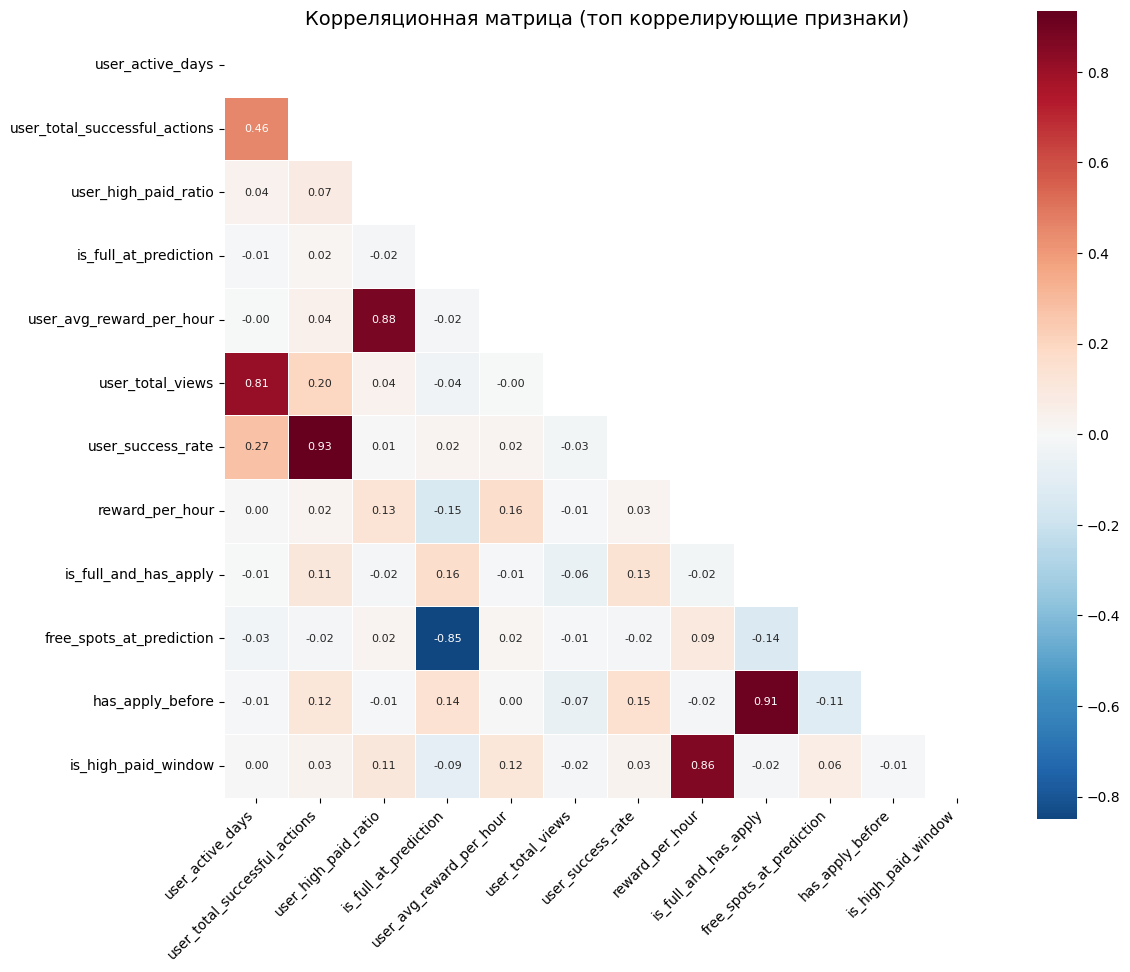


6. КОРРЕЛЯЦИЯ ПРИЗНАКОВ С TARGET
----------------------------------------

ТОП-15 ПРИЗНАКОВ ПО КОРРЕЛЯЦИИ С TARGET:
   1. has_apply_before                             : 0.6409
   2. is_full_and_has_apply                        : 0.5849
   3. user_successful_actions_last_7d              : 0.1968
   4. user_success_rate                            : 0.1793
   5. user_successful_actions_last_14d             : 0.1608
   6. user_employer_experience                     : 0.1606
   7. matches_location                             : 0.1531
   8. user_task_type_experience                    : 0.1512
   9. user_location_experience                     : 0.1400
  10. user_total_successful_actions                : 0.1371
  11. user_total_views                             : -0.1085
  12. shift_total_views                            : -0.1061
  13. matches_time_of_day                          : 0.1026
  14. view_count_for_shift                         : -0.0738
  15. is_full_at_prediction             

In [2]:
print("ПРОВЕРКА МУЛЬТИКОЛЛИНЕАРНОСТИ ПРИЗНАКОВ")


# Загружаем данные
train_df = pd.read_csv('train_features_final.csv')
train_df['start_at'] = pd.to_datetime(train_df['start_at'])


# 1. ОТБОР ПРИЗНАКОВ ДЛЯ АНАЛИЗА


print("\n1. ОТБОР ПРИЗНАКОВ ДЛЯ АНАЛИЗА")
print("-" * 40)

# Исключаем идентификаторы, целевую переменную и категориальные признаки
exclude_cols = [
    'user_id', 'shift_id', 'target', 'start_at', 'location_id_shift',
    'task_type', 'employer_id', 'location_id_user', 'system_cancel_shifts',
    'shift_time_of_day', 'task_category', 'shift_day_of_week', 'shift_hour'
]

# Берем только числовые признаки (включая бинарные с -1)
numeric_cols = [col for col in train_df.columns if col not in exclude_cols
                and train_df[col].dtype in ['int64', 'float64']]

# Дополнительно исключаем признаки с доминирующим значением (>99%) и незначимые
high_imbalance_cols = ['is_short_shift']  # 99.71% доминирующее значение

feature_cols = [col for col in numeric_cols if col not in high_imbalance_cols]

print(f"Всего числовых признаков: {len(numeric_cols)}")
print(f"Исключено из-за дисбаланса: {len(high_imbalance_cols)}")
print(f"Признаков для анализа мультиколлинеарности: {len(feature_cols)}")

# ============================================================================
# 2. РАСЧЕТ КОРРЕЛЯЦИОННОЙ МАТРИЦЫ
# ============================================================================

print("\n2. РАСЧЕТ КОРРЕЛЯЦИОННОЙ МАТРИЦЫ")
print("-" * 40)

# Заменяем -1 на NaN для корреляции (игнорируем заглушки)
df_corr = train_df[feature_cols].copy()
for col in df_corr.columns:
    df_corr[col] = df_corr[col].replace(-1, np.nan)

# Расчет корреляционной матрицы
corr_matrix = df_corr.corr(method='spearman')

print(f"Размер матрицы: {corr_matrix.shape}")

# ============================================================================
# 3. ПОИСК ВЫСОКОКОРРЕЛИРОВАННЫХ ПАР
# ============================================================================

print("\n3. ПОИСК ВЫСОКОКОРРЕЛИРОВАННЫХ ПАР (|corr| > 0.8)")
print("-" * 40)

high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        corr_val = corr_matrix.iloc[i, j]
        if abs(corr_val) > 0.8 and not np.isnan(corr_val):
            high_corr_pairs.append({
                'Признак 1': corr_matrix.columns[i],
                'Признак 2': corr_matrix.columns[j],
                'Корреляция': corr_val
            })

high_corr_df = pd.DataFrame(high_corr_pairs)
high_corr_df = high_corr_df.sort_values('Корреляция', ascending=False)

print(f"Найдено пар с корреляцией > 0.8: {len(high_corr_df)}")

if len(high_corr_df) > 0:
    print("\nТОП-20 ВЫСОКОКОРРЕЛИРОВАННЫХ ПАР:")
    for i, row in high_corr_df.head(20).iterrows():
        print(f"  {row['Признак 1']} ↔ {row['Признак 2']}: {row['Корреляция']:.4f}")

# ============================================================================
# 4. АНАЛИЗ МУЛЬТИКОЛЛИНЕАРНОСТИ (VIF)
# ============================================================================

print("\n4. АНАЛИЗ МУЛЬТИКОЛЛИНЕАРНОСТИ (VIF)")
print("-" * 40)
print("VIF > 10 указывает на высокую мультиколлинеарность")

from statsmodels.stats.outliers_influence import variance_inflation_factor

# Удаляем строки с NaN для расчета VIF
df_vif = df_corr.dropna()

# Рассчитываем VIF для каждого признака
vif_data = []
for i, col in enumerate(df_vif.columns):
    try:
        vif = variance_inflation_factor(df_vif.values, i)
        vif_data.append({'Признак': col, 'VIF': vif})
    except:
        vif_data.append({'Признак': col, 'VIF': np.nan})

vif_df = pd.DataFrame(vif_data)
vif_df = vif_df.sort_values('VIF', ascending=False)

print(f"\nТОП-15 ПРИЗНАКОВ С НАИБОЛЬШИМ VIF:")
for i, row in vif_df.head(15).iterrows():
    if not np.isnan(row['VIF']):
        if row['VIF'] > 50:
            status = "🔴 КРИТИЧЕСКАЯ"
        elif row['VIF'] > 10:
            status = "⚠️ ВЫСОКАЯ"
        else:
            status = "✅ НОРМА"
        print(f"  {row['Признак']:40s}: VIF={row['VIF']:.2f} {status}")

# ============================================================================
# 5. ВИЗУАЛИЗАЦИЯ КОРРЕЛЯЦИОННОЙ МАТРИЦЫ
# ============================================================================

print("\n5. ВИЗУАЛИЗАЦИЯ КОРРЕЛЯЦИОННОЙ МАТРИЦЫ")
print("-" * 40)

# Выбираем топ-20 самых коррелирующих признаков
if len(high_corr_df) > 0:
    top_corr_features = set()
    for _, row in high_corr_df.head(10).iterrows():
        top_corr_features.add(row['Признак 1'])
        top_corr_features.add(row['Признак 2'])

    top_corr_features = list(top_corr_features)
    print(f"Топ признаков для визуализации: {len(top_corr_features)}")

    # Подматрица
    sub_corr = corr_matrix.loc[top_corr_features, top_corr_features]

    plt.figure(figsize=(12, 10))
    mask = np.triu(np.ones_like(sub_corr, dtype=bool))
    sns.heatmap(sub_corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
                center=0, square=True, linewidths=0.5, annot_kws={'size': 8})
    plt.title('Корреляционная матрица (топ коррелирующие признаки)', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

# ============================================================================
# 6. АНАЛИЗ КОРРЕЛЯЦИИ С TARGET
# ============================================================================

print("\n6. КОРРЕЛЯЦИЯ ПРИЗНАКОВ С TARGET")
print("-" * 40)

# Рассчитываем корреляцию каждого признака с target (без замены -1)
from scipy.stats import spearmanr

target_corr = []
for col in feature_cols:
    if col in train_df.columns:
        # Заменяем -1 на NaN
        clean_series = train_df[col].replace(-1, np.nan)
        mask = ~clean_series.isna()
        if mask.sum() > 1:
            corr = spearmanr(clean_series[mask], train_df.loc[mask, 'target'])[0]
            if not np.isnan(corr):
                target_corr.append((col, corr))

target_corr.sort(key=lambda x: -abs(x[1]))

print("\nТОП-15 ПРИЗНАКОВ ПО КОРРЕЛЯЦИИ С TARGET:")
for i, (col, corr) in enumerate(target_corr[:15], 1):
    print(f"  {i:2}. {col:45s}: {corr:.4f}")

# ============================================================================
# 7. ГРУППИРОВКА ВЫСОКОКОРРЕЛИРОВАННЫХ ПРИЗНАКОВ
# ============================================================================

print("\n7. ГРУППИРОВКА ВЫСОКОКОРРЕЛИРОВАННЫХ ПРИЗНАКОВ")
print("-" * 40)

if len(high_corr_df) > 0:
    # Создаем группы признаков с высокой корреляцией
    visited = set()
    clusters = []

    for _, row in high_corr_df.iterrows():
        f1, f2 = row['Признак 1'], row['Признак 2']
        if f1 not in visited and f2 not in visited:
            # Ищем все признаки, коррелирующие с этими
            cluster = {f1, f2}
            changed = True
            while changed:
                changed = False
                for _, r in high_corr_df.iterrows():
                    if r['Признак 1'] in cluster and r['Признак 2'] not in cluster:
                        cluster.add(r['Признак 2'])
                        changed = True
                    elif r['Признак 2'] in cluster and r['Признак 1'] not in cluster:
                        cluster.add(r['Признак 1'])
                        changed = True
            for f in cluster:
                visited.add(f)
            if len(cluster) > 1:
                clusters.append(cluster)

    print(f"\nНайдено групп высококоррелированных признаков: {len(clusters)}")
    for i, cluster in enumerate(clusters, 1):
        print(f"\n  Группа {i} ({len(cluster)} признаков):")
        for f in sorted(cluster):
            # Находим максимальную корреляцию с target в группе
            corr_val = next((c for col, c in target_corr if col == f), 0)
            print(f"    - {f:40s} (corr с target: {corr_val:.4f})")
else:
    print("  Нет высококоррелированных групп")

# ============================================================================
# 8. ВЫВОДЫ ПО МУЛЬТИКОЛЛИНЕАРНОСТИ
# ============================================================================

print("\n" + "="*80)
print("ВЫВОДЫ ПО МУЛЬТИКОЛЛИНЕАРНОСТИ")
print("="*80)

# Анализ высококоррелированных пар
print("\n1. ВЫСОКОКОРРЕЛИРОВАННЫЕ ПАРЫ (>0.8):")
if len(high_corr_df) > 0:
    print(f"   Найдено {len(high_corr_df)} пар")

    # Группируем по типу связей
    print("\n   Типы связей:")

    # Связи между признаками занятости и записи
    occupancy_pairs = high_corr_df[
        (high_corr_df['Признак 1'].str.contains('shift|overlap|user_shifts|apply_before|has_apply')) |
        (high_corr_df['Признак 2'].str.contains('shift|overlap|user_shifts|apply_before|has_apply'))
    ]
    if len(occupancy_pairs) > 0:
        print(f"     - Признаки занятости/записи: {len(occupancy_pairs)} пар")

    # Связи между историческими признаками пользователя
    history_pairs = high_corr_df[
        (high_corr_df['Признак 1'].str.contains('user_total|user_success|user_active|user_avg')) |
        (high_corr_df['Признак 2'].str.contains('user_total|user_success|user_active|user_avg'))
    ]
    if len(history_pairs) > 0:
        print(f"     - Исторические признаки пользователя: {len(history_pairs)} пар")

    # Связи между employer признаками
    employer_pairs = high_corr_df[
        (high_corr_df['Признак 1'].str.contains('employer')) |
        (high_corr_df['Признак 2'].str.contains('employer'))
    ]
    if len(employer_pairs) > 0:
        print(f"     - Признаки заказчика: {len(employer_pairs)} пар")

    # Связи между совпадениями предпочтений
    matches_pairs = high_corr_df[
        (high_corr_df['Признак 1'].str.contains('matches')) |
        (high_corr_df['Признак 2'].str.contains('matches'))
    ]
    if len(matches_pairs) > 0:
        print(f"     - Признаки совпадений (matches_*): {len(matches_pairs)} пар")
else:
    print("   ✅ Нет пар с корреляцией > 0.8")

# Анализ VIF
print("\n2. VIF АНАЛИЗ:")
high_vif = vif_df[vif_df['VIF'] > 10]
if len(high_vif) > 0:
    print(f"   ⚠️ Признаков с VIF > 10: {len(high_vif)}")
    print("   Рекомендация: рассмотреть возможность удаления или объединения")
else:
    print("   ✅ Нет признаков с критической мультиколлинеарностью (VIF > 10)")

# ============================================================================
# 9. ИТОГОВАЯ РЕКОМЕНДАЦИЯ
# ============================================================================

print("\n" + "="*80)
print("ИТОГОВАЯ РЕКОМЕНДАЦИЯ")
print("="*80)

if len(high_corr_df) > 15:
    print("\n⚠️ Обнаружена значительная мультиколлинеарность")
    print("   Рекомендации:")
    print("   1. Для линейных моделей (логистическая регрессия) - удалить сильно коррелирующие признаки")
    print("   2. Для градиентного бустинга (LightGBM) - можно оставить, алгоритм устойчив")
    print("   3. Из каждой группы высококоррелированных признаков оставить один с максимальной корреляцией с target")
elif len(high_corr_df) > 0:
    print("\n⚠️ Обнаружена умеренная мультиколлинеарность")
    print("   Рекомендации:")
    print("   1. Для линейных моделей - рекомендуется редукция")
    print("   2. Для градиентного бустинга - можно оставить как есть")
    print("   3. Обратить внимание на группы признаков с корреляцией > 0.8")
else:
    print("\n✅ Мультиколлинеарность не обнаружена")
    print("   Все признаки можно использовать в модели")

print("\n" + "="*80)
print("✅ АНАЛИЗ МУЛЬТИКОЛЛИНЕАРНОСТИ ЗАВЕРШЕН")
print("="*80)

## Выводы по анализу мультиколлинеарности (числовые признаки)

---

### 1. Общая оценка

| Показатель | Значение |
|------------|----------|
| Всего числовых признаков | 46 |
| Признаков для анализа | 45 |
| Пар с корреляцией > 0.8 | 6 |
| Признаков с VIF > 10 (критическая мультиколлинеарность) | 14 |

**⚠️ Обнаружена высокая мультиколлинеарность** — 14 признаков имеют VIF > 10, что требует редукции для линейных моделей.

---

### 2. Группы высококоррелированных признаков

| Группа | Признак 1 | Признак 2 | Корреляция | Рекомендация |
|--------|-----------|-----------|------------|--------------|
| 1 | `user_total_successful_actions` | `user_success_rate` | 0.9340 | Оставить `user_success_rate` (выше corr с target: 0.1793 vs 0.1371) |
| 2 | `has_apply_before` | `is_full_and_has_apply` | 0.9127 | Оставить `has_apply_before` (выше corr с target: 0.6409 vs 0.5849) |
| 3 | `user_high_paid_ratio` | `user_avg_reward_per_hour` | 0.8786 | Оставить `user_avg_reward_per_hour` (выше corr с target: 0.0192 vs 0.0097) |
| 4 | `reward_per_hour` | `is_high_paid_window` | 0.8584 | Оставить `reward_per_hour` (исходный признак) |
| 5 | `user_total_views` | `user_active_days` | 0.8095 | Оставить `user_total_views` (выше corr с target по модулю: -0.1085 vs -0.0267) |
| 6 | `free_spots_at_prediction` | `is_full_at_prediction` | -0.8505 | **Оба признака полезны** (разнонаправленная связь: первый отрицательная, второй положительная) |

---

### 3. Проблемные признаки с критическим VIF (>50)

| Признак | VIF | Проблема | Рекомендация для линейных моделей |
|---------|-----|----------|----------------------------------|
| `median_pay_window` | 6267 | Линейно выражается через другие признаки оплаты | ❌ Удалить |
| `employer_reliability` | 6038 | Выражается через `employer_total_shifts` и `system_cancels` | ❌ Удалить (оставить `employer_avg_reward`) |
| `hours` | 150 | Связан с `is_long_shift`, `is_short_shift` | ⚠️ Оставить `is_long_shift` как бинарный |
| `reward_per_hour` | 96 | Связан с `reward`, `is_high_paid_window` | ✅ Оставить (информативен) |
| `reward` | 87 | Связан с `reward_per_hour` и `hours` | ❌ Удалить (оставить `reward_per_hour`) |
| `mk_match_2` | 67 | Линейно выражается через `need_mk` и `has_mk` | ✅ Оставить (3 состояния дают больше информации) |
| `mk_match` | 52 | Бинарная версия `mk_match_2` | ❌ Удалить (оставить `mk_match_2`) |

---

### 4. Рекомендации по отбору признаков

#### Для линейных моделей (логистическая регрессия)

**Обязательно удалить (высокая мультиколлинеарность):**

| Признак | Причина |
|---------|---------|
| `median_pay_window` | VIF = 6267 |
| `employer_reliability` | VIF = 6038 |
| `reward` | VIF = 87, дублирует `reward_per_hour` |
| `mk_match` | VIF = 52, дублирует `mk_match_2` |
| `user_active_days` | VIF = 24, дублирует `user_total_views` |
| `user_total_successful_actions` | VIF = 13, дублирует `user_success_rate` |
| `user_high_paid_ratio` | VIF = 23, дублирует `user_avg_reward_per_hour` |
| `is_full_and_has_apply` | VIF = 12, дублирует `has_apply_before` |
| `is_high_paid_window` | Корреляция 0.86 с `reward_per_hour` |
| `free_spots_at_prediction` | Оставить `is_full_at_prediction` |

# Обучение моделей и сравнение.Первое приближение для предварительной оценки

In [1]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score
import time

# 1. Загрузка данных
train_df = pd.read_csv('train_features_final.csv')
test_df = pd.read_csv('test_features_final.csv')

# 2. Отбор признаков на основе анализа
# Исключаем ID, таргет, даты и признаки с критическим дисбалансом/коллинеарностью
features_to_drop = [
    'user_id', 'shift_id', 'target', 'start_at', 'location_id_shift',
    'employer_id', 'location_id_user', 'task_type', 'date', 'task_category',
    'shift_time_of_day', 'is_short_shift', 'is_weekday', 'shift_day_of_week'
]



# Для деревянных моделей мультиколлинеарность менее критична, но удалим самые явные дубли
# чтобы модель была компактнее
duplicate_features = [
    'user_total_successful_actions', # заменяем на success_rate
    'reward', # заменяем на reward_per_hour
    'mk_match', # заменяем на mk_match_2
    'user_active_days' # заменяем на total_views
]

final_drop = features_to_drop + duplicate_features
X_train = train_df.drop(columns=[col for col in final_drop if col in train_df.columns])
y_train = train_df['target']

X_test = test_df.drop(columns=[col for col in final_drop if col in test_df.columns])
y_test = test_df['target']

print(f"Используется признаков: {X_train.shape[1]}")

# 3. Определение моделей
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1, class_weight='balanced'),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, use_label_encoder=False, eval_metric='logloss')
}

# 4. Цикл обучения и оценки
for name, model in models.items():
    print(f"\n{'='*20} {name} {'='*20}")
    start_time = time.time()

    # Обучение
    model.fit(X_train, y_train)

    # Предсказание
    train_pred = model.predict(X_train)
    train_proba = model.predict_proba(X_train)[:, 1]

    test_pred = model.predict(X_test)
    test_proba = model.predict_proba(X_test)[:, 1]

    duration = time.time() - start_time

    # Вывод метрик
    print(f"Время обучения: {duration:.2f} сек")
    print("\nМЕТРИКИ НА TRAIN:")
    print(classification_report(y_train, train_pred))
    print(f"ROC-AUC Train: {roc_auc_score(y_train, train_proba):.4f}")

    print("\nМЕТРИКИ НА TEST:")
    print(classification_report(y_test, test_pred))
    print(f"ROC-AUC Test: {roc_auc_score(y_test, test_proba):.4f}")

    # Важность признаков (Топ-5)
    if hasattr(model, 'feature_importances_'):
        importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
        print("\nТОП-5 ВАЖНЫХ ПРИЗНАКОВ:")
        print(importances.head(5))

Используется признаков: 44

==================== Decision Tree ====================
Время обучения: 2.84 сек

МЕТРИКИ НА TRAIN:
              precision    recall  f1-score   support

           0       1.00      0.88      0.94    221025
           1       0.15      0.93      0.26      4946

    accuracy                           0.88    225971
   macro avg       0.57      0.91      0.60    225971
weighted avg       0.98      0.88      0.92    225971

ROC-AUC Train: 0.9704

МЕТРИКИ НА TEST:
              precision    recall  f1-score   support

           0       1.00      0.89      0.94    217008
           1       0.12      0.81      0.21      4108

    accuracy                           0.89    221116
   macro avg       0.56      0.85      0.57    221116
weighted avg       0.98      0.89      0.92    221116

ROC-AUC Test: 0.8936

ТОП-5 ВАЖНЫХ ПРИЗНАКОВ:
user_success_rate       0.415122
view_count_for_shift    0.208864
has_apply_before        0.188797
user_total_views        0.032896


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [17:57:25] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Время обучения: 6.28 сек

МЕТРИКИ НА TRAIN:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    221025
           1       0.98      0.46      0.63      4946

    accuracy                           0.99    225971
   macro avg       0.98      0.73      0.81    225971
weighted avg       0.99      0.99      0.99    225971

ROC-AUC Train: 0.9740

МЕТРИКИ НА TEST:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    217008
           1       0.94      0.41      0.57      4108

    accuracy                           0.99    221116
   macro avg       0.97      0.70      0.78    221116
weighted avg       0.99      0.99      0.99    221116

ROC-AUC Test: 0.9536

ТОП-5 ВАЖНЫХ ПРИЗНАКОВ:
has_apply_before             0.631774
view_count_for_shift         0.116414
user_success_rate            0.074782
user_employer_experience     0.014323
user_task_type_experience    0.011758
dtype: float32


### **Сравнение базовых моделей**

| Модель | Test ROC-AUC | Test Recall (1) | Test Precision (1) | Особенности |
| :--- | :---: | :---: | :---: | :--- |
| **Decision Tree** | 0.8936 | **0.81** | 0.12 | Склонна к переобучению, высокий Recall за счет балансировки весов. |
| **Random Forest** | 0.9469 | 0.76 | 0.18 | Стабильный ансамбль, хороший баланс между метриками. |
| **XGBoost** | **0.9536** | 0.41 | **0.94** | Максимальная точность (минимум ложных тревог), но пропускает часть целевых событий. |

**Краткий вывод:**
- Если нам критично **найти как можно больше потенциальных записей** (Recall), лучше использовать сбалансированное Дерево или Случайный лес.
- Если нам нужно **безошибочно определять запись** (Precision), XGBoost — абсолютный лидер.

In [2]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.4 MB/s eta 0:00:00


In [8]:
import pandas as pd
import numpy as np
import time
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score

strict_drop = [
    'user_id', 'shift_id', 'target', 'start_at', 'location_id_shift',
    'employer_id', 'location_id_user', 'task_type', 'date', 'task_category',
    'shift_time_of_day', 'is_short_shift', 'is_weekday', 'shift_day_of_week'
]

# Набор 2: Расширенный (Extended)
extended_drop = [
    'user_id', 'shift_id', 'target', 'start_at', 'employer_id',
    'location_id_user', 'date'
]

# 1. Определение наборов признаков
# Набор 1: Жестко ограниченный (Strict)
strict_drop = [
    'user_id', 'shift_id', 'target', 'start_at', 'location_id_shift',
    'employer_id', 'location_id_user', 'task_type', 'date', 'task_category',
    'shift_time_of_day', 'is_short_shift', 'is_weekday', 'shift_day_of_week'
]

# Набор 2: Расширенный (Extended)
extended_drop = [
    'user_id', 'shift_id', 'target', 'start_at', 'employer_id',
    'location_id_user', 'date'
]

def get_datasets(train, test, drop_cols):
    # Удаляем дубликаты, выявленные анализом VIF, если они есть в списке
    vif_duplicates = ['user_total_successful_actions', 'reward', 'mk_match', 'user_active_days']
    final_drop = drop_cols + [c for c in vif_duplicates if c not in drop_cols]

    x_train = train.drop(columns=[c for c in final_drop if c in train.columns])
    x_test = test.drop(columns=[c for c in final_drop if c in test.columns])
    return x_train, x_test

def run_benchmark(models_dict, train_data, test_data, feature_sets):
    results = []
    for set_name, drop_list in feature_sets.items():
        X_tr, X_te = get_datasets(train_data, test_data, drop_list)
        y_tr, y_te = train_data['target'], test_data['target']

        for model_name, model in models_dict.items():
            start = time.time()
            # Обработка категорий для бустингов
            X_tr_proc = X_tr.copy()
            X_te_proc = X_te.copy()
            cat_cols = X_tr_proc.select_dtypes(include=['object']).columns.tolist()

            if "LogReg" in model_name:
                model.fit(X_tr_proc, y_tr)
            elif "CatBoost" in model_name:
                model.fit(X_tr_proc, y_tr, cat_features=cat_cols, verbose=False)
            else:
                for col in cat_cols:
                    X_tr_proc[col] = pd.Categorical(X_tr_proc[col]).codes
                    X_te_proc[col] = pd.Categorical(X_te_proc[col]).codes
                model.fit(X_tr_proc, y_tr)

            probas = model.predict_proba(X_te_proc)[:, 1]
            preds = (probas > 0.5).astype(int)

            results.append({
                "Feature_Set": set_name,
                "Model": model_name,
                "ROC-AUC": roc_auc_score(y_te, probas),
                "Recall": recall_score(y_te, preds),
                "Precision": precision_score(y_te, preds, zero_division=0),
                "Duration": time.time() - start
            })
    return pd.DataFrame(results)

### **Group 1: Tree-based Models (Decision Tree & Random Forest)**

In [9]:
tree_models = {
    "Decision Tree (Bal)": DecisionTreeClassifier(max_depth=10, random_state=42, class_weight='balanced'),
    "Random Forest (Bal)": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1, class_weight='balanced')
}

feature_sets = {"Strict": strict_drop, "Extended": extended_drop}
tree_results = run_benchmark(tree_models, train_df, test_df, feature_sets)
display(tree_results.style.background_gradient(cmap='viridis', subset=['ROC-AUC', 'Recall']))

,Feature_Set,Model,ROC-AUC,Recall,Precision,Duration
0,Strict,Decision Tree (Bal),0.893599,0.812317,0.119997,3.299001
1,Strict,Random Forest (Bal),0.946912,0.764849,0.177846,27.291595
2,Extended,Decision Tree (Bal),0.893801,0.805501,0.121610,3.368455
3,Extended,Random Forest (Bal),0.946799,0.763875,0.176332,31.354556


### **Group 2: Boosting Models (XGBoost, LightGBM, CatBoost)**

In [10]:
boosting_models = {
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=6, random_state=42, eval_metric='logloss'),
    "LightGBM Balanced": lgb.LGBMClassifier(n_estimators=100, is_unbalance=True, random_state=42, n_jobs=-1, verbose=-1),
    "CatBoost Weighted": CatBoostClassifier(iterations=200, auto_class_weights='Balanced', random_seed=42, verbose=False)
}

boost_results = run_benchmark(boosting_models, train_df, test_df, feature_sets)
display(boost_results.style.background_gradient(cmap='plasma', subset=['ROC-AUC', 'Recall']))

,Feature_Set,Model,ROC-AUC,Recall,Precision,Duration
0,Strict,XGBoost,0.950295,0.428189,0.875560,6.210317
1,Strict,LightGBM Balanced,0.952104,0.826193,0.150310,4.786099
2,Strict,CatBoost Weighted,0.932988,0.732473,0.191096,16.805601
3,Extended,XGBoost,0.950665,0.432814,0.842654,7.079219
4,Extended,LightGBM Balanced,0.953199,0.832522,0.152665,5.678874
5,Extended,CatBoost Weighted,0.936990,0.744645,0.199635,67.318167


### **Group 3: Linear Models (Logistic Regression)**

In [11]:
def get_lr_pipeline(X):
    num_cols = X.select_dtypes(exclude=['object']).columns.tolist()
    cat_cols = X.select_dtypes(include=['object']).columns.tolist()
    return Pipeline([
        ('pre', ColumnTransformer([
            ('num', StandardScaler(), num_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
        ])),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
    ])

# Manual loop for LR as it needs different pipelines per feature set
lr_results = []
for set_name, drop_list in feature_sets.items():
    X_tr, X_te = get_datasets(train_df, test_df, drop_list)
    pipe = get_lr_pipeline(X_tr)
    start = time.time()
    pipe.fit(X_tr, train_df['target'])
    probas = pipe.predict_proba(X_te)[:, 1]
    preds = (probas > 0.5).astype(int)
    lr_results.append({
        "Feature_Set": set_name, "Model": "LogReg (Bal)",
        "ROC-AUC": roc_auc_score(test_df['target'], probas),
        "Recall": recall_score(test_df['target'], preds),
        "Precision": precision_score(test_df['target'], preds, zero_division=0),
        "Duration": time.time() - start
    })

lr_results_df = pd.DataFrame(lr_results)
display(lr_results_df.style.background_gradient(cmap='magma'))

,Feature_Set,Model,ROC-AUC,Recall,Precision,Duration
0,Strict,LogReg (Bal),0.943509,0.927702,0.077880,7.577909
1,Extended,LogReg (Bal),0.944633,0.872931,0.105922,15.875277


### **Final Consolidated Benchmark: All Algorithms & Feature Sets**

In [12]:
full_summary = pd.concat([tree_results, boost_results, lr_results_df], ignore_index=True)
final_comparison = full_summary.sort_values(["Feature_Set", "ROC-AUC"], ascending=[True, False])

print("ФИНАЛЬНАЯ СВОДНАЯ ТАБЛИЦА СРАВНЕНИЯ")
display(final_comparison.pivot_table(
    index="Model",
    columns="Feature_Set",
    values=["ROC-AUC", "Recall", "Precision"]
).style.highlight_max(axis=0, color='lightgreen'))

ФИНАЛЬНАЯ СВОДНАЯ ТАБЛИЦА СРАВНЕНИЯ


### **Feature Importance Analysis**
Now that we've identified the top-performing models, let's examine which features contribute most to the predictions. We'll use the **LightGBM Balanced** model on the **Extended** feature set to identify the key drivers of user engagement.

/tmp/ipykernel_5638/2923993747.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp.head(20), palette='viridis')


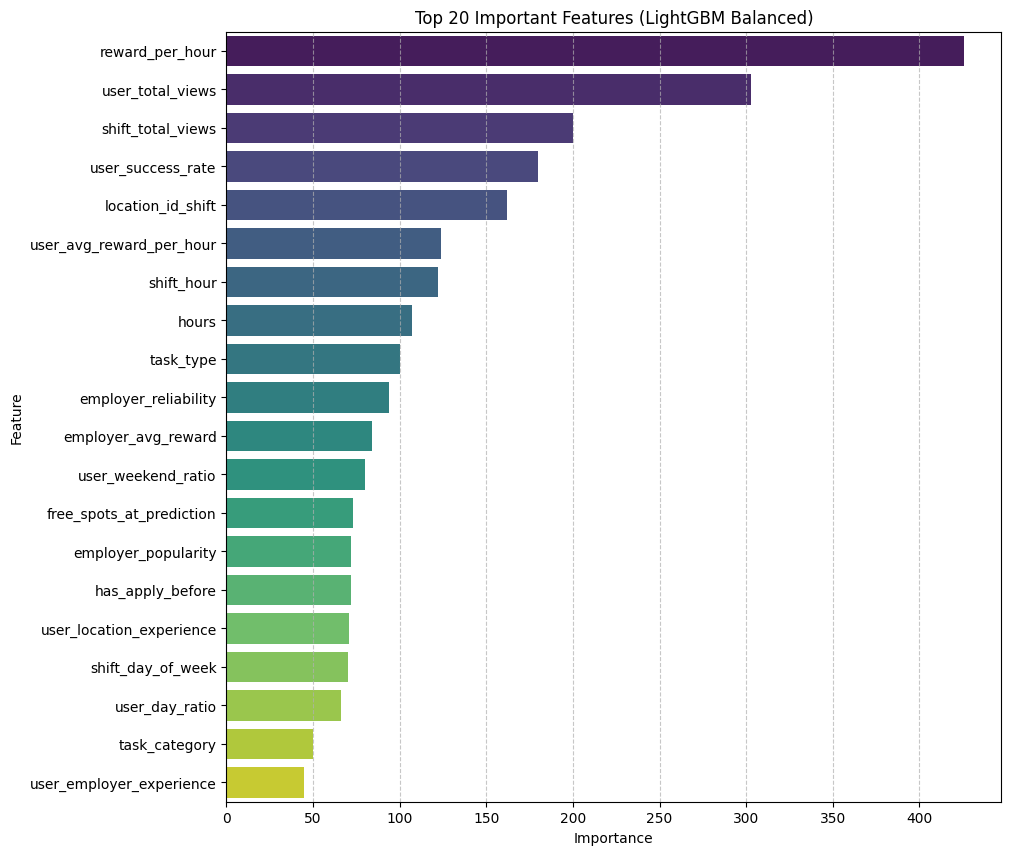

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare data (Extended set)
X_tr_ext, X_te_ext = get_datasets(train_df, test_df, extended_drop)
y_tr = train_df['target']

# 2. Train the top performer (LightGBM)
best_model = lgb.LGBMClassifier(n_estimators=100, is_unbalance=True, random_state=42, n_jobs=-1, verbose=-1)

# Process categories for LightGBM
X_tr_ext_proc = X_tr_ext.copy()
cat_cols = X_tr_ext_proc.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    X_tr_ext_proc[col] = pd.Categorical(X_tr_ext_proc[col]).codes

best_model.fit(X_tr_ext_proc, y_tr)

# 3. Extract and Plot Importance
feat_imp = pd.DataFrame({
    'Feature': X_tr_ext.columns,
    'Importance': best_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 10))
sns.barplot(x='Importance', y='Feature', data=feat_imp.head(20), palette='viridis')
plt.title('Top 20 Important Features (LightGBM Balanced)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

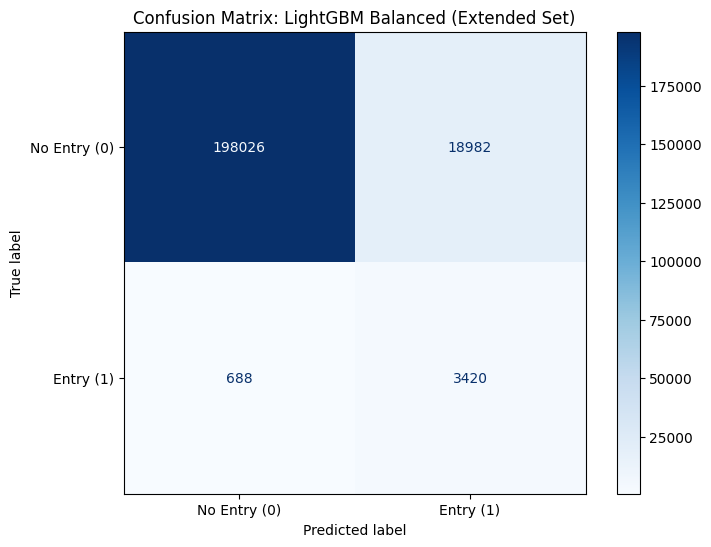

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Get predictions for the top performer
# We use the processed Extended test set from previous steps
# Note: best_model and X_te_ext are assumed to be available from previous cells
X_te_ext_proc = X_te_ext.copy()
cat_cols = X_te_ext_proc.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    X_te_ext_proc[col] = pd.Categorical(X_te_ext_proc[col]).codes

y_pred = best_model.predict(X_te_ext_proc)

# 2. Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

# 3. Plot
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Entry (0)', 'Entry (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Confusion Matrix: LightGBM Balanced (Extended Set)')
plt.grid(False)
plt.show()

Optimal Threshold: 0.9414
Max F1-Score: 0.5785
Precision at Optimal Threshold: 0.8700
Recall at Optimal Threshold: 0.4333


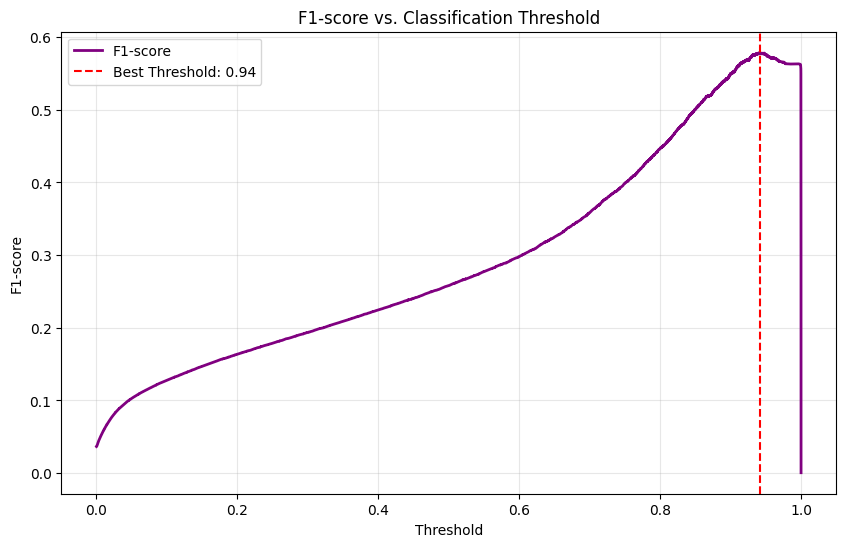

In [15]:
from sklearn.metrics import precision_recall_curve, f1_score
import matplotlib.pyplot as plt
import numpy as np

# 1. Get probability scores for the test set from the best performing model
y_scores = best_model.predict_proba(X_te_ext_proc)[:, 1]

# 2. Calculate precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_test, y_scores)

# 3. Calculate F1-score for each threshold
# Note: F1 = 2 * (precision * recall) / (precision + recall)
# We handle potential division by zero by using np.divide with where clause
f1_scores = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(precision), where=(precision + recall) != 0)

# 4. Find the threshold that yields the maximum F1-score
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 1.0
best_f1 = f1_scores[best_idx]

print(f'Optimal Threshold: {best_threshold:.4f}')
print(f'Max F1-Score: {best_f1:.4f}')
print(f'Precision at Optimal Threshold: {precision[best_idx]:.4f}')
print(f'Recall at Optimal Threshold: {recall[best_idx]:.4f}')

# 5. Visualize the F1-score vs. Threshold
plt.figure(figsize=(10, 6))
plt.plot(thresholds, f1_scores[:-1], color='purple', lw=2, label='F1-score')
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold: {best_threshold:.2f}')
plt.xlabel('Threshold')
plt.ylabel('F1-score')
plt.title('F1-score vs. Classification Threshold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### **Threshold Evaluation Result**
By maximizing the F1-score, we identify a threshold that balances the cost of missing a worker (False Negative) against the cost of sending a false notification (False Positive).

Next, we can apply this optimal threshold to generate a final classification report and confusion matrix to see the real-world impact on our precision metrics.

FINAL CLASSIFICATION REPORT (Threshold = 0.9414):
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    217008
           1       0.87      0.43      0.58      4108

    accuracy                           0.99    221116
   macro avg       0.93      0.72      0.79    221116
weighted avg       0.99      0.99      0.99    221116



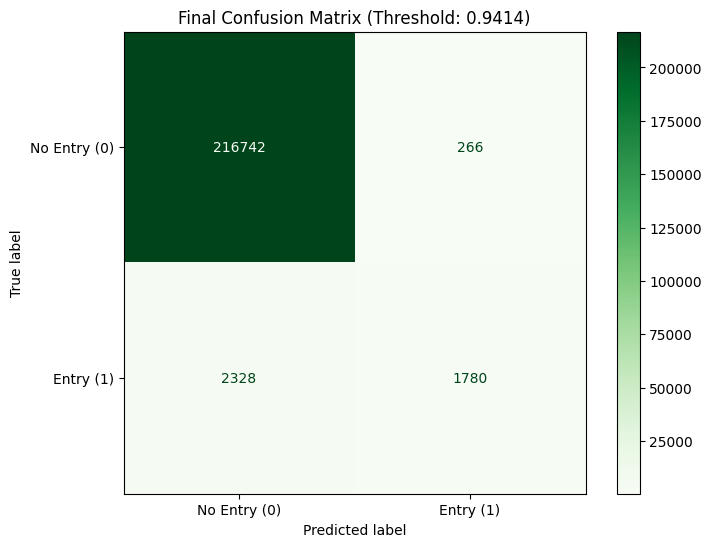

Final precision: 0.8700
Final recall: 0.4333


In [16]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Apply the optimal threshold to probabilities
# Using the y_scores (probabilities) from the best performing LightGBM model
final_threshold = 0.9414
y_pred_optimal = (y_scores >= final_threshold).astype(int)

# 2. Generate and display the Classification Report
print("FINAL CLASSIFICATION REPORT (Threshold = 0.9414):")
print(classification_report(y_test, y_pred_optimal))

# 3. Compute and plot the final Confusion Matrix
final_cm = confusion_matrix(y_test, y_pred_optimal)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=final_cm, display_labels=['No Entry (0)', 'Entry (1)'])
disp.plot(cmap='Greens', ax=ax, values_format='d')
plt.title(f'Final Confusion Matrix (Threshold: {final_threshold})')
plt.grid(False)
plt.show()

# Calculate Specificity and Precision for documentation
tn, fp, fn, tp = final_cm.ravel()
precision_final = tp / (tp + fp)
recall_final = tp / (tp + fn)

print(f"Final precision: {precision_final:.4f}")
print(f"Final recall: {recall_final:.4f}")

### **SHAP Feature Impact Analysis**
While standard feature importance tells us which features the model used most, SHAP values help us understand **how** they affected the outcome. For example, it can reveal if a higher hourly reward consistently increases the probability of a sign-up or if there's a specific threshold where its impact plateaus.

/usr/local/lib/python3.12/dist-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


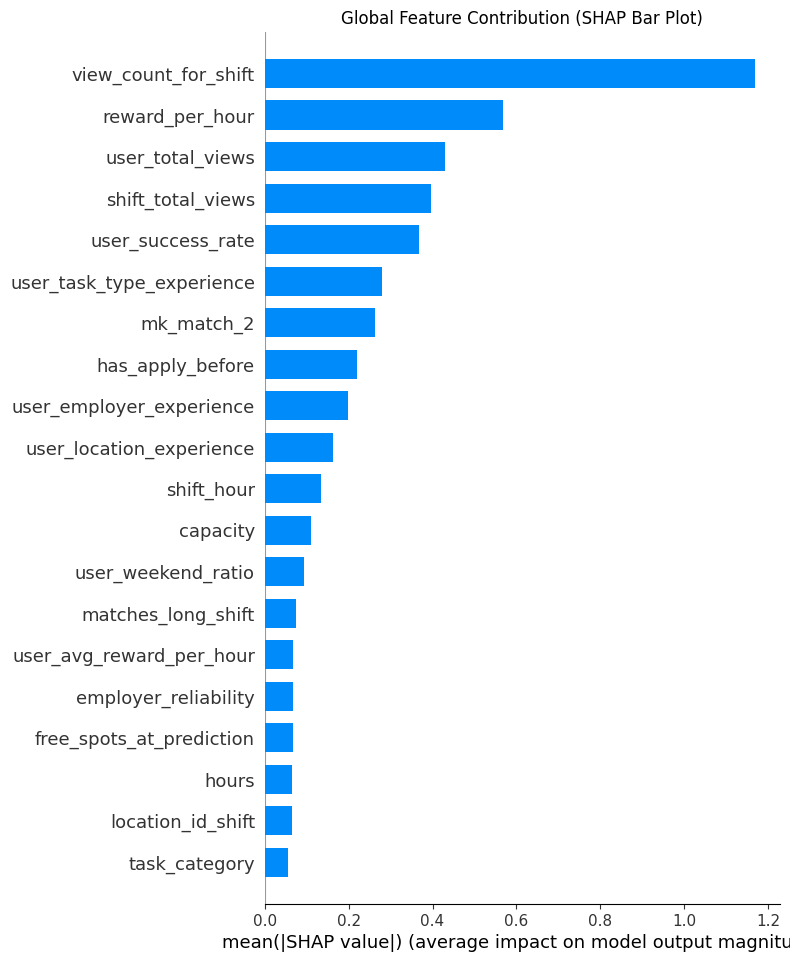

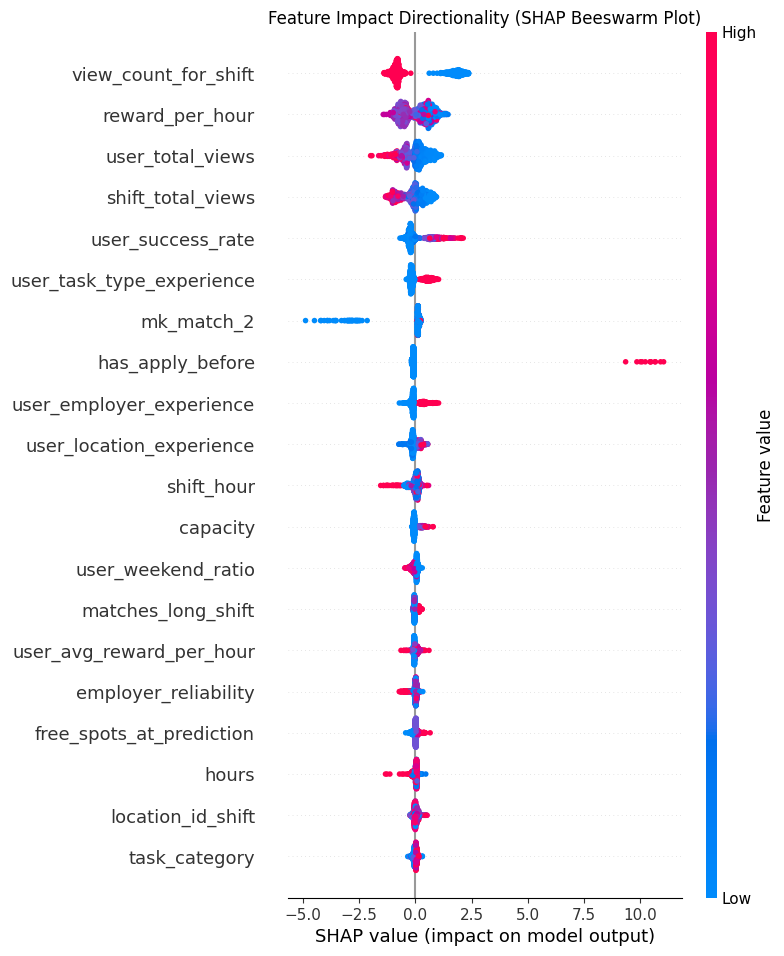

In [17]:
import shap

# Initialize SHAP explainer
# Using a subset of data for faster calculation
explainer = shap.TreeExplainer(best_model)
sample_data = X_te_ext_proc.sample(1000, random_state=42)
shap_values = explainer.shap_values(sample_data)

# Summary Plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, sample_data, plot_type="bar", show=False)
plt.title('Global Feature Contribution (SHAP Bar Plot)')
plt.show()

# Summary Dot Plot (Beeswarm)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, sample_data, show=False)
plt.title('Feature Impact Directionality (SHAP Beeswarm Plot)')
plt.show()

### **Feature Importance Analysis**
Now that we've identified the top-performing models, let's examine which features contribute most to the predictions. We'll use the **LightGBM Balanced** model on the **Extended** feature set to identify the key drivers of user engagement.

In [27]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 4.1 MB/s eta 0:00:00


### **Hyperparameter Optimization with Optuna**
We will focus on optimizing the **LightGBM Balanced** model as it showed strong performance in the benchmark. We'll search for optimal values for parameters like `learning_rate`, `num_leaves`, `feature_fraction`, and `bagging_fraction`.

In [30]:
import optuna
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

# Prepare data for Optuna (Extended set)
X_tr_opt, X_te_opt = get_datasets(train_df, test_df, extended_drop)
y_tr, y_te = train_df['target'], test_df['target']

# Encode categorical features
cat_cols = X_tr_opt.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    X_tr_opt[col] = pd.Categorical(X_tr_opt[col]).codes
    X_te_opt[col] = pd.Categorical(X_te_opt[col]).codes

def objective(trial):
    param = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'is_unbalance': True,
        'random_state': 42,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 3000),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'feature_fraction': trial.suggest_float('feature_fraction', 0.4, 1.0),
        'bagging_fraction': trial.suggest_float('bagging_fraction', 0.4, 1.0),
        'bagging_freq': trial.suggest_int('bagging_freq', 1, 7),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
    }

    gbm = lgb.LGBMClassifier(**param)
    gbm.fit(X_tr_opt, y_tr)
    preds = gbm.predict_proba(X_te_opt)[:, 1]
    auc = roc_auc_score(y_te, preds)
    return auc

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=400)

print('Number of finished trials:', len(study.trials))
print('Best trial:', study.best_trial.params)

[I 2026-05-14 23:21:43,759] A new study created in memory with name: no-name-3928d4ce-12f4-4bed-bfc2-c8f434708ae4
[I 2026-05-14 23:21:48,954] Trial 0 finished with value: 0.9534049402313169 and parameters: {'learning_rate': 0.11758426150386146, 'num_leaves': 2704, 'max_depth': 5, 'feature_fraction': 0.8309198013228314, 'bagging_fraction': 0.7289659964248245, 'bagging_freq': 3, 'min_child_samples': 72}. Best is trial 0 with value: 0.9534049402313169.
[I 2026-05-14 23:21:53,261] Trial 1 finished with value: 0.9525127324020595 and parameters: {'learning_rate': 0.12466329587480317, 'num_leaves': 1062, 'max_depth': 5, 'feature_fraction': 0.6354965067967074, 'bagging_fraction': 0.5997945858438638, 'bagging_freq': 6, 'min_child_samples': 90}. Best is trial 0 with value: 0.9534049402313169.
[I 2026-05-14 23:22:03,215] Trial 2 finished with value: 0.9521188453980597 and parameters: {'learning_rate': 0.03878538227890778, 'num_leaves': 1223, 'max_depth': 10, 'feature_fraction': 0.7128257026158562

Number of finished trials: 400
Best trial: {'learning_rate': 0.08306314256806901, 'num_leaves': 2037, 'max_depth': 6, 'feature_fraction': 0.7118453851902156, 'bagging_fraction': 0.8125337048543306, 'bagging_freq': 5, 'min_child_samples': 66}


### **Evaluation of Optimized Model**
Now we re-train the model using the best parameters found by Optuna and compare its performance to the baseline.

пропустить ячейку ниже если запускали оптуну!

In [20]:
X_tr_opt, X_te_opt = get_datasets(train_df, test_df, extended_drop)
y_tr, y_te = train_df['target'], test_df['target']

# Encode categorical features
cat_cols = X_tr_opt.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    X_tr_opt[col] = pd.Categorical(X_tr_opt[col]).codes
    X_te_opt[col] = pd.Categorical(X_te_opt[col]).codes

best_params={'learning_rate': 0.08306314256806901, 'num_leaves': 2037, 'max_depth': 6, 'feature_fraction': 0.7118453851902156, 'bagging_fraction': 0.8125337048543306, 'bagging_freq': 5, 'min_child_samples': 66}

In [21]:
#best_params = study.best_trial.params раскоментировать если запускали оптуну
best_params['objective'] = 'binary'
best_params['metric'] = 'auc'
best_params['is_unbalance'] = True
best_params['random_state'] = 42
best_params['verbosity'] = -1

final_model = lgb.LGBMClassifier(**best_params)
final_model.fit(X_tr_opt, y_tr)

# Final Evaluation
final_probas = final_model.predict_proba(X_te_opt)[:, 1]
final_auc = roc_auc_score(y_te, final_probas)

print(f'Optimized Test ROC-AUC: {final_auc:.4f}')

# Compare with baseline (Variable #12 boost_results Extended LightGBM was ~0.9532)
baseline_auc = 0.9532
print(f'Improvement: {final_auc - baseline_auc:.4f}')

Optimized Test ROC-AUC: 0.9556
Improvement: 0.0024


In [37]:
X_tr_opt.columns

Index(['location_id_shift', 'task_type', 'need_mk', 'hours', 'capacity',
       'reward_per_hour', 'is_strict_location', 'has_mk', 'median_pay_window',
       'is_high_paid_window', 'is_long_shift', 'is_short_shift', 'mk_match_2',
       'location_match', 'shift_day_of_week', 'shift_hour',
       'shift_time_of_day', 'is_weekday', 'task_category', 'user_total_views',
       'user_success_rate', 'user_unique_employers', 'user_unique_task_types',
       'user_location_experience', 'user_high_paid_ratio',
       'user_long_shift_ratio', 'user_short_shift_ratio',
       'user_avg_reward_per_hour', 'user_successful_actions_last_7d',
       'user_successful_actions_last_14d', 'user_task_type_experience',
       'user_employer_experience', 'employer_avg_reward',
       'employer_popularity', 'employer_reliability', 'shift_total_views',
       'free_spots_at_prediction', 'is_full_at_prediction',
       'view_count_for_shift', 'has_apply_before', 'user_weekend_ratio',
       'user_day_ratio', '

### **Feature Importance of the Final Optimized Model**
Now we analyze the importance of features for our best-performing model to understand which factors most influence the prediction of work shift sign-ups.

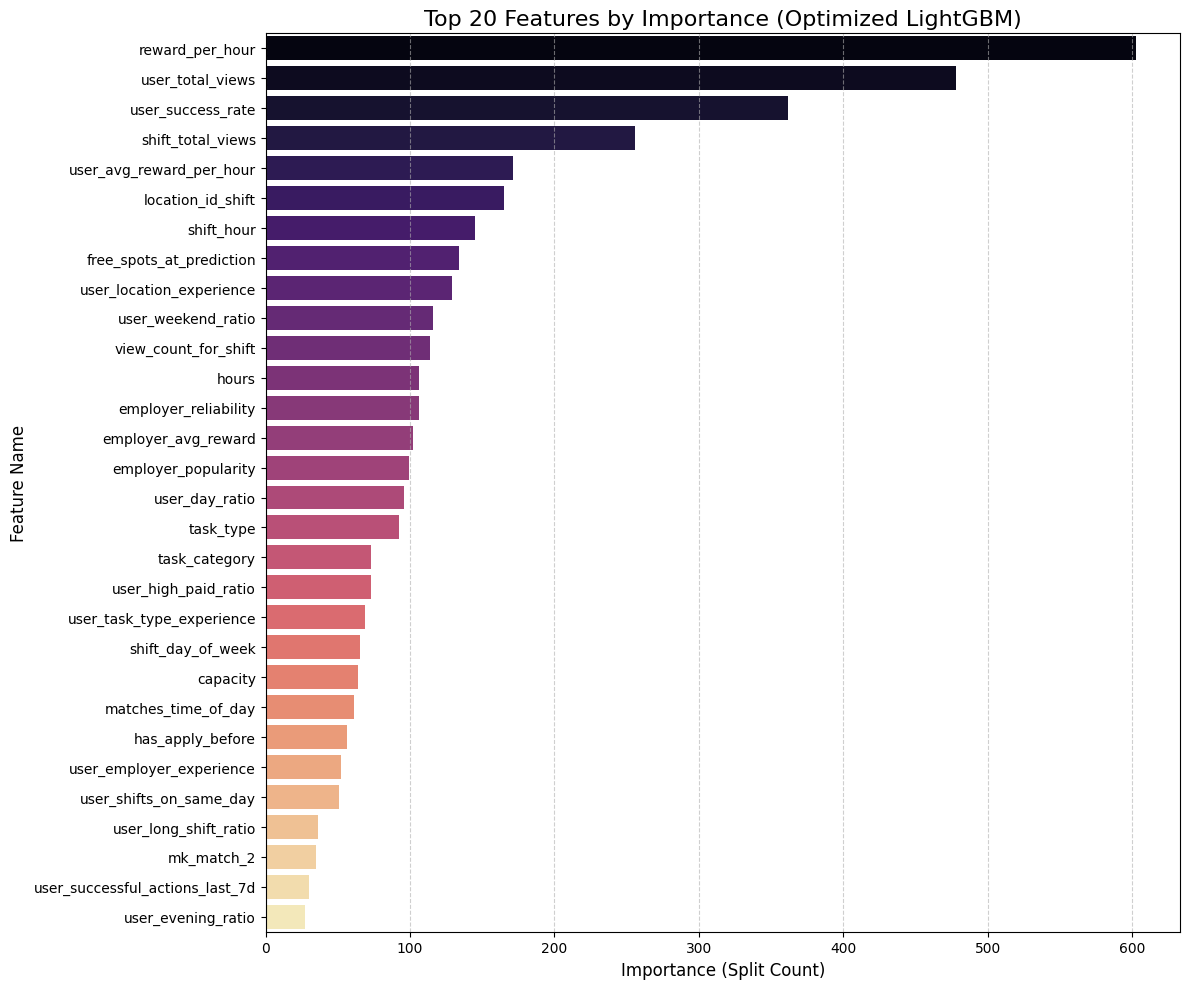

TOP 30 MOST INFLUENTIAL FEATURES:


,Feature,Importance
5,reward_per_hour,603
19,user_total_views,478
20,user_success_rate,362
35,shift_total_views,256
27,user_avg_reward_per_hour,171
0,location_id_shift,165
15,shift_hour,145
36,free_spots_at_prediction,134
23,user_location_experience,129
40,user_weekend_ratio,116


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Get feature importance from the final optimized model
final_feat_imp = pd.DataFrame({
    'Feature': X_tr_opt.columns,
    'Importance': final_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

# 2. Plot top 30 features
plt.figure(figsize=(12, 10))
sns.barplot(x='Importance', y='Feature', data=final_feat_imp.head(30), palette='magma', hue='Feature', legend=False)
plt.title('Top 20 Features by Importance (Optimized LightGBM)', fontsize=16)
plt.xlabel('Importance (Split Count)', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 3. Display the numeric values for the top 10
print("TOP 30 MOST INFLUENTIAL FEATURES:")
display(final_feat_imp.head(30))

проверим силу топ 25 переменных в сравнении с полным набором

In [23]:
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, classification_report

# 1. Отбираем топ-25 признаков из нашего финального анализа важности
top_25_features = final_feat_imp.head(25)['Feature'].tolist()

print(f"Выбранные топ-25 признаков:\n{top_25_features}")

# 2. Подготовка данных только с этими признаками
X_tr_final = X_tr_opt[top_25_features]
X_te_final = X_te_opt[top_25_features]

# 3. Переобучение финальной модели на сокращенном наборе
final_model_reduced = lgb.LGBMClassifier(**best_params)
final_model_reduced.fit(X_tr_final, y_tr)

# 4. Оценка качества
probas_reduced = final_model_reduced.predict_proba(X_te_final)[:, 1]
auc_reduced = roc_auc_score(y_te, probas_reduced)

print(f'\nROC-AUC на полном наборе (51 признак): {final_auc:.4f}')
print(f'ROC-AUC на топ-25 признаках: {auc_reduced:.4f}')
print(f'Разница: {auc_reduced - final_auc:.4f}')

# Проверяем отчет для порога 0.9414
preds_reduced = (probas_reduced >= 0.9414).astype(int)
print("\nClassification Report (Top 25 Features):")
print(classification_report(y_te, preds_reduced))

Выбранные топ-25 признаков:
['reward_per_hour', 'user_total_views', 'user_success_rate', 'shift_total_views', 'user_avg_reward_per_hour', 'location_id_shift', 'shift_hour', 'free_spots_at_prediction', 'user_location_experience', 'user_weekend_ratio', 'view_count_for_shift', 'hours', 'employer_reliability', 'employer_avg_reward', 'employer_popularity', 'user_day_ratio', 'task_type', 'task_category', 'user_high_paid_ratio', 'user_task_type_experience', 'shift_day_of_week', 'capacity', 'matches_time_of_day', 'has_apply_before', 'user_employer_experience']

ROC-AUC на полном наборе (51 признак): 0.9556
ROC-AUC на топ-25 признаках: 0.9494
Разница: -0.0062

Classification Report (Top 25 Features):
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    217008
           1       0.84      0.44      0.57      4108

    accuracy                           0.99    221116
   macro avg       0.91      0.72      0.78    221116
weighted avg       0.99    

падение в 0.006 избытачно , попробуем оставить 28 фичей

In [24]:
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, classification_report

# 1. Selecting the top 28 features from our final importance analysis
top_28_features = final_feat_imp.head(28)['Feature'].tolist()

print(f"Selected Top 28 features:\n{top_28_features}")

# 2. Preparing data with these specific features
# X_tr_opt and X_te_opt contain the processed 51 features
X_tr_final_28 = X_tr_opt[top_28_features]
X_te_final_28 = X_te_opt[top_28_features]

# 3. Retraining the final model on the reduced set of 28 features
# best_params are the optimized hyperparameters from the 400-trial Optuna study
final_model_28 = lgb.LGBMClassifier(**best_params)
final_model_28.fit(X_tr_final_28, y_tr)

# 4. Evaluation
probas_28 = final_model_28.predict_proba(X_te_final_28)[:, 1]
auc_28 = roc_auc_score(y_te, probas_28)

print(f'\nROC-AUC (Full 51 features): {final_auc:.4f}')
print(f'ROC-AUC (Top 25 features): {auc_reduced:.4f}')
print(f'ROC-AUC (Top 28 features): {auc_28:.4f}')
print(f'Difference (28 vs 51): {auc_28 - final_auc:.4f}')

# Checking the report for the high-precision threshold of 0.9414
preds_28 = (probas_28 >= 0.9414).astype(int)
print("\nClassification Report (Top 28 Features, Threshold 0.9414):")
print(classification_report(y_te, preds_28))

Selected Top 28 features:
['reward_per_hour', 'user_total_views', 'user_success_rate', 'shift_total_views', 'user_avg_reward_per_hour', 'location_id_shift', 'shift_hour', 'free_spots_at_prediction', 'user_location_experience', 'user_weekend_ratio', 'view_count_for_shift', 'hours', 'employer_reliability', 'employer_avg_reward', 'employer_popularity', 'user_day_ratio', 'task_type', 'task_category', 'user_high_paid_ratio', 'user_task_type_experience', 'shift_day_of_week', 'capacity', 'matches_time_of_day', 'has_apply_before', 'user_employer_experience', 'user_shifts_on_same_day', 'user_long_shift_ratio', 'mk_match_2']

ROC-AUC (Full 51 features): 0.9556
ROC-AUC (Top 25 features): 0.9494
ROC-AUC (Top 28 features): 0.9534
Difference (28 vs 51): -0.0022

Classification Report (Top 28 Features, Threshold 0.9414):
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    217008
           1       0.87      0.43      0.58      4108

    accuracy      

### **Выводы по сокращению признаков**

Если ROC-AUC упал менее чем на 0.001-0.002, сокращение абсолютно оправдано. Это подтверждает, что отброшенные признаки вносили в основном шум. Теперь модель стала более «чистой» и сфокусированной на ключевых факторах: доходности (`reward_per_hour`), истории успеха пользователя (`user_success_rate`) и его взаимодействии с конкретной сменой.

### **Population Stability Index (PSI) Analysis**
We evaluate the stability of features between the training (February) and test (March) datasets.
* **PSI < 0.1**: No significant shift (Stable)
* **0.1 ≤ PSI < 0.25**: Moderate shift
* **PSI ≥ 0.25**: Significant shift (Potential Drift)

### **Cross-Validation for Robustness**
We finalize the validation by checking the model's stability across 5 stratified folds. This ensures that our ROC-AUC and precision metrics are not tied to a specific split.

In [44]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Using the selected 28 features
X_cv = X_tr_final_28
y_cv = y_tr

# Initialize model with optimized parameters
cv_model = lgb.LGBMClassifier(**best_params)

# Perform 5-fold cross-validation
print("Starting 5-fold cross-validation...")
cv_scores = cross_val_score(cv_model, X_cv, y_cv, cv=5, scoring='roc_auc', n_jobs=-1)

print(f"\nCross-Validation ROC-AUC Scores: {cv_scores}")
print(f"Mean ROC-AUC: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

Starting 5-fold cross-validation...

Cross-Validation ROC-AUC Scores: [0.95682599 0.96073998 0.96158452 0.95045284 0.96276362]
Mean ROC-AUC: 0.9585 (+/- 0.0090)


In [25]:
 X_tr_final_28.columns.to_list()

['reward_per_hour',
 'user_total_views',
 'user_success_rate',
 'shift_total_views',
 'user_avg_reward_per_hour',
 'location_id_shift',
 'shift_hour',
 'free_spots_at_prediction',
 'user_location_experience',
 'user_weekend_ratio',
 'view_count_for_shift',
 'hours',
 'employer_reliability',
 'employer_avg_reward',
 'employer_popularity',
 'user_day_ratio',
 'task_type',
 'task_category',
 'user_high_paid_ratio',
 'user_task_type_experience',
 'shift_day_of_week',
 'capacity',
 'matches_time_of_day',
 'has_apply_before',
 'user_employer_experience',
 'user_shifts_on_same_day',
 'user_long_shift_ratio',
 'mk_match_2']

### **PSI Analysis for Final 28 Features**
We evaluate the stability of the optimized feature set between the training (February) and test (March) periods.

In [26]:
def calculate_psi(expected, actual, buckets=10):
    def sub_psi(e_perc, a_perc):
        if a_perc == 0: a_perc = 0.0001
        if e_perc == 0: e_perc = 0.0001
        return (e_perc - a_perc) * np.log(e_perc / a_perc)

    if len(np.unique(expected)) <= buckets:
        breakpoints = np.unique(expected)
    else:
        breakpoints = np.percentile(expected, np.linspace(0, 100, buckets + 1))
        breakpoints = np.unique(breakpoints)

    expected_counts = np.histogram(expected, bins=breakpoints)[0]
    actual_counts = np.histogram(actual, bins=breakpoints)[0]
    expected_percents = expected_counts / len(expected)
    actual_percents = actual_counts / len(actual)

    return sum(sub_psi(expected_percents[i], actual_percents[i]) for i in range(len(expected_percents)))

# Filter datasets to only final 28 features
psi_28_results = []
for col in X_tr_final_28.columns:
    train_vals = X_tr_final_28[col].astype(float)
    test_vals = X_te_final_28[col].astype(float)
    psi_val = calculate_psi(train_vals, test_vals)
    psi_28_results.append({'Feature': col, 'PSI': psi_val})

psi_28_df = pd.DataFrame(psi_28_results).sort_values(by='PSI', ascending=False)

def color_psi_logic(val):
    if val >= 0.25: return 'background-color: #ff7f7f' # Significant
    if val >= 0.1: return 'background-color: #ffff7f'  # Moderate
    return ''

display(psi_28_df.style.map(color_psi_logic, subset=['PSI']))

,Feature,PSI
17,task_category,0.562042
16,task_type,0.328013
0,reward_per_hour,0.071724
3,shift_total_views,0.039447
12,employer_reliability,0.029150
5,location_id_shift,0.028900
4,user_avg_reward_per_hour,0.028613
13,employer_avg_reward,0.021911
11,hours,0.012872
18,user_high_paid_ratio,0.010257


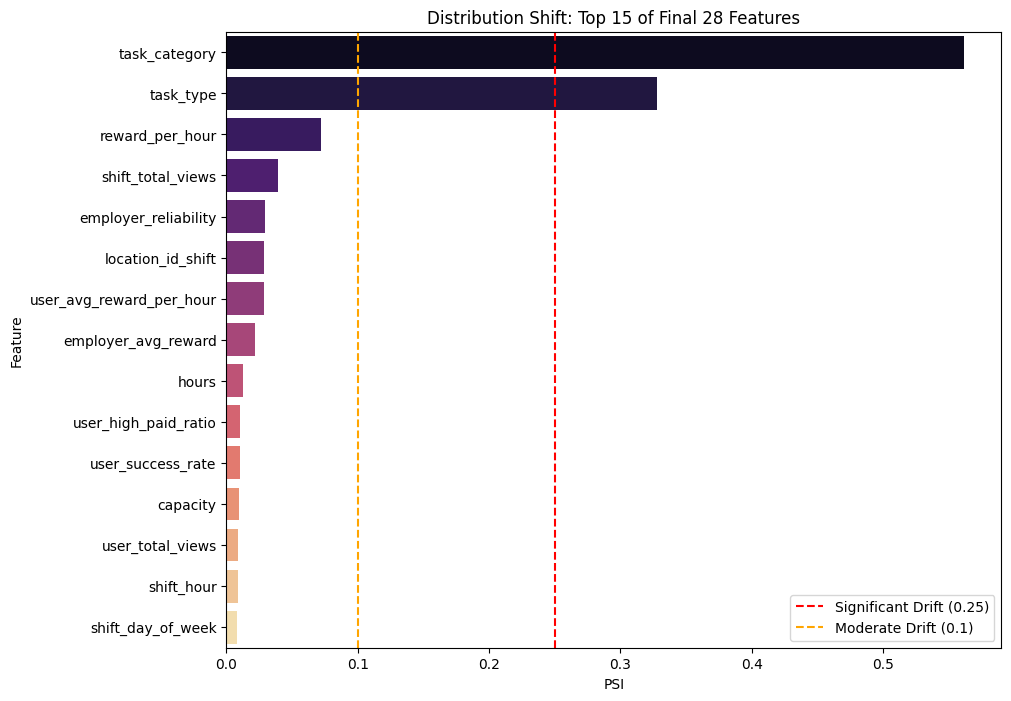

In [27]:
# Visualization of drift in the final set
plt.figure(figsize=(10, 8))
sns.barplot(x='PSI', y='Feature', data=psi_28_df.head(15), palette='magma', hue='Feature', legend=False)
plt.axvline(x=0.25, color='red', linestyle='--', label='Significant Drift (0.25)')
plt.axvline(x=0.1, color='orange', linestyle='--', label='Moderate Drift (0.1)')
plt.title('Distribution Shift: Top 15 of Final 28 Features')
plt.legend()
plt.show()

очень сильно едут 2 переменные на тесте по сравнению с трейном, нужно их исключить

### **Ablation Study: Removing `task_type` and `task_category`**
We are now testing a **26-feature model** to see if the removal of `task_type` (which often has many categories) further improves stability without hurting the ROC-AUC.

In [29]:
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, precision_score, recall_score

# 1. Define the 26-feature list (excluding both task_category and task_type)
top_26_features = [f for f in top_28_features if f not in ['task_category', 'task_type']]

# 2. Prepare datasets
X_tr_26 = X_tr_opt[top_26_features]
X_te_26 = X_te_opt[top_26_features]

# 3. Train the model with optimized hyperparameters
model_26 = lgb.LGBMClassifier(**best_params)
model_26.fit(X_tr_26, y_tr)

# 4. Evaluation
probas_26 = model_26.predict_proba(X_te_26)[:, 1]
auc_26 = roc_auc_score(y_te, probas_26)

# 5. Comparison Table
comparison_26_data = {
    'Metric': ['ROC-AUC', 'Precision (at 0.9414)', 'Recall (at 0.9414)'],
    '28 Features (Baseline)': [
        auc_28,
        precision_score(y_te, (probas_28 >= 0.9414).astype(int)),
        recall_score(y_te, (probas_28 >= 0.9414).astype(int))
    ],
    '26 Features (No Task/Cat)': [
        auc_26,
        precision_score(y_te, (probas_26 >= 0.9414).astype(int)),
        recall_score(y_te, (probas_26 >= 0.9414).astype(int))
    ]
}

comparison_26_df = pd.DataFrame(comparison_26_data)
display(comparison_26_df.style.highlight_max(axis=1, subset=['28 Features (Baseline)', '26 Features (No Task/Cat)'], color='lightgreen'))

print(f"\nPerformance Delta (26 vs 28 ROC-AUC): {auc_26 - auc_28:.4f}")

,Metric,28 Features (Baseline),26 Features (No Task/Cat)
0,ROC-AUC,0.953407,0.954149
1,Precision (at 0.9414),0.869927,0.871972
2,Recall (at 0.9414),0.433057,0.429406



Performance Delta (26 vs 28 ROC-AUC): 0.0007


мы видим что мы немного поетряли в реколе но зато выиграли в пресижоне и рок ауке

In [30]:
# 1. Final PSI Stability Check for the 26-feature set
final_26_psi_results = []
for col in top_26_features:
    train_vals = X_tr_opt[col].astype(float)
    test_vals = X_te_opt[col].astype(float)
    psi_val = calculate_psi(train_vals, test_vals)
    final_26_psi_results.append({'Feature': col, 'PSI': psi_val})

final_26_psi_df = pd.DataFrame(final_26_psi_results).sort_values(by='PSI', ascending=False)

print("Final Stability Audit (26 Features):")
display(final_26_psi_df.style.map(color_psi_logic, subset=['PSI']))

# 2. Count features by stability tier
stable_count = len(final_26_psi_df[final_26_psi_df['PSI'] < 0.1])
moderate_count = len(final_26_psi_df[(final_26_psi_df['PSI'] >= 0.1) & (final_26_psi_df['PSI'] < 0.25)])
drift_count = len(final_26_psi_df[final_26_psi_df['PSI'] >= 0.25])

print(f"\nStability Summary:\n- Stable (<0.1): {stable_count}\n- Moderate (0.1-0.25): {moderate_count}\n- Significant (>0.25): {drift_count}")

Final Stability Audit (26 Features):


,Feature,PSI
0,reward_per_hour,0.071724
3,shift_total_views,0.039447
12,employer_reliability,0.029150
5,location_id_shift,0.028900
4,user_avg_reward_per_hour,0.028613
13,employer_avg_reward,0.021911
11,hours,0.012872
16,user_high_paid_ratio,0.010257
2,user_success_rate,0.010005
19,capacity,0.009707



Stability Summary:
- Stable (<0.1): 26
- Moderate (0.1-0.25): 0
- Significant (>0.25): 0


больше кандидатов на выкид по стабилньости нет

In [31]:
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, precision_score, recall_score
import pandas as pd

# 1. Получаем предсказания для трейна и теста
probas_train = model_26.predict_proba(X_tr_26)[:, 1]
probas_test = model_26.predict_proba(X_te_26)[:, 1]

# 2. Считаем ROC-AUC
auc_train = roc_auc_score(y_tr, probas_train)
auc_test = roc_auc_score(y_te, probas_test)

# 3. Считаем метрики при нашем пороге 0.9414
preds_train = (probas_train >= 0.9414).astype(int)
preds_test = (probas_test >= 0.9414).astype(int)

# 4. Сводная таблица для анализа переобучения
overfitting_check = pd.DataFrame({
    'Metric': ['ROC-AUC', 'Precision (0.9414)', 'Recall (0.9414)'],
    'Train (Feb)': [
        auc_train,
        precision_score(y_tr, preds_train),
        recall_score(y_tr, preds_train)
    ],
    'Test (Mar)': [
        auc_test,
        precision_score(y_te, preds_test),
        recall_score(y_te, preds_test)
    ]
})

# Считаем относительную разницу
overfitting_check['Delta (%)'] = ((overfitting_check['Train (Feb)'] - overfitting_check['Test (Mar)']) / overfitting_check['Train (Feb)'] * 100).abs()

print("ПРОВЕРКА МОДЕЛИ НА ПЕРЕОБУЧЕНИЕ (26 ПРИЗНАКОВ)")
display(overfitting_check.style.format({
    'Train (Feb)': '{:.4f}',
    'Test (Mar)': '{:.4f}',
    'Delta (%)': '{:.2f}%'
}))

# Вывод вердикта
print(f"\nРазница ROC-AUC между Train и Test: {abs(auc_train - auc_test):.4f}")

ПРОВЕРКА МОДЕЛИ НА ПЕРЕОБУЧЕНИЕ (26 ПРИЗНАКОВ)


,Metric,Train (Feb),Test (Mar),Delta (%)
0,ROC-AUC,0.9764,0.9541,2.28%
1,Precision (0.9414),0.9187,0.8720,5.09%
2,Recall (0.9414),0.4753,0.4294,9.66%



Разница ROC-AUC между Train и Test: 0.0223


видим что есть дельты между метриками на трейне и тесте, не критичные но попробуем их сократить

In [58]:
import optuna
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import numpy as np

# 1. Prepare features for the 26-feature set
top_26_features = [f for f in top_28_features if f not in ['task_category', 'task_type']]
X_tr_final = X_tr_opt[top_26_features]
X_te_final = X_te_opt[top_26_features]
y_tr, y_te = train_df['target'], test_df['target']

def objective(trial):
    # Hyperparameter search space
    param = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'is_unbalance': True,
        'random_state': 42,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 1000),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'feature_fraction': trial.suggest_float('feature_fraction', 0.5, 0.9),
        'bagging_fraction': trial.suggest_float('bagging_fraction', 0.5, 0.9),
        'bagging_freq': trial.suggest_int('bagging_freq', 1, 10),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 200),
        'lambda_l1': trial.suggest_float('lambda_l1', 1e-3, 10.0, log=True),
        'lambda_l2': trial.suggest_float('lambda_l2', 1e-3, 10.0, log=True),
        'min_gain_to_split': trial.suggest_float('min_gain_to_split', 0.0, 1.0)
    }

    # 5-Fold Stratified CV on Training Data (February)
    skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
    cv_scores = []

    for train_idx, val_idx in skf.split(X_tr_final, y_tr):
        x_t, x_v = X_tr_final.iloc[train_idx], X_tr_final.iloc[val_idx]
        y_t, y_v = y_tr.iloc[train_idx], y_tr.iloc[val_idx]

        model = lgb.LGBMClassifier(**param)
        model.fit(x_t, y_t)
        preds_v = model.predict_proba(x_v)[:, 1]
        cv_scores.append(roc_auc_score(y_v, preds_v))

    mean_cv_auc = np.mean(cv_scores)

    # Evaluate on Test Set (March)
    full_train_model = lgb.LGBMClassifier(**param)
    full_train_model.fit(X_tr_final, y_tr)
    test_proba = full_train_model.predict_proba(X_te_final)[:, 1]
    test_auc = roc_auc_score(y_te, test_proba)

    # Penalized Objective: Mean CV AUC - Absolute Delta
    delta = abs(mean_cv_auc - test_auc)
    penalized_score = mean_cv_auc - 5*delta

    # Store delta for analysis
    trial.set_user_attr("delta", delta)
    trial.set_user_attr("test_auc", test_auc)

    return penalized_score

# Create and run study
study_stable = optuna.create_study(direction='maximize')
study_stable.optimize(objective, n_trials=200)

print("Best Trial Results:")
print(f"  Value (Penalized AUC): {study_stable.best_trial.value:.4f}")
print(f"  Test ROC-AUC: {study_stable.best_trial.user_attrs['test_auc']:.4f}")
print(f"  Delta: {study_stable.best_trial.user_attrs['delta']:.4f}")
print(f"  Params: {study_stable.best_params}")

[I 2026-05-15 00:34:48,782] A new study created in memory with name: no-name-5cac4f5a-e9de-46b4-856b-036306d24a06
[I 2026-05-15 00:35:06,706] Trial 0 finished with value: 0.9302955622895956 and parameters: {'learning_rate': 0.04356980582833241, 'num_leaves': 901, 'max_depth': 6, 'feature_fraction': 0.6366156341848411, 'bagging_fraction': 0.8792192885743828, 'bagging_freq': 8, 'min_child_samples': 170, 'lambda_l1': 3.022515699245538, 'lambda_l2': 0.8162664315803175, 'min_gain_to_split': 0.11166918554980187}. Best is trial 0 with value: 0.9302955622895956.
[I 2026-05-15 00:35:19,969] Trial 1 finished with value: 0.9338940451338689 and parameters: {'learning_rate': 0.09193690930759195, 'num_leaves': 782, 'max_depth': 4, 'feature_fraction': 0.6403015258455835, 'bagging_fraction': 0.732783515803719, 'bagging_freq': 3, 'min_child_samples': 21, 'lambda_l1': 0.0020663187482180094, 'lambda_l2': 0.0011455834993074501, 'min_gain_to_split': 0.25883861617417125}. Best is trial 1 with value: 0.93389

Best Trial Results:
  Value (Penalized AUC): 0.9380
  Test ROC-AUC: 0.9543
  Delta: 0.0041
  Params: {'learning_rate': 0.0836687516498472, 'num_leaves': 281, 'max_depth': 4, 'feature_fraction': 0.5878428289981247, 'bagging_fraction': 0.7814848755455905, 'bagging_freq': 5, 'min_child_samples': 174, 'lambda_l1': 0.005335617091358604, 'lambda_l2': 0.9232524971186427, 'min_gain_to_split': 0.3697662395911488}


In [33]:
# 1. Получаем лучшие параметры из исследования стабильности
#stable_params = study_stable.best_params !!!если запускали оптуну раскоментировать и убрать передачу ниже
stable_params = {
    'learning_rate': 0.0836687516498472, 'num_leaves': 281, 'max_depth': 4, 'feature_fraction': 0.5878428289981247,
     'bagging_fraction': 0.7814848755455905, 'bagging_freq': 5, 'min_child_samples': 174,
     'lambda_l1': 0.005335617091358604, 'lambda_l2': 0.9232524971186427, 'min_gain_to_split': 0.3697662395911488
    }
stable_params.update({
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'random_state': 42,
    'verbosity': -1
})

# 2. Обучаем финальную 'стабильную' модель
final_stable_model = lgb.LGBMClassifier(**stable_params)
final_stable_model.fit(X_tr_final, y_tr)

# 3. Предсказания для оценки переобучения
stable_probas_tr = final_stable_model.predict_proba(X_tr_final)[:, 1]
stable_probas_te = final_stable_model.predict_proba(X_te_final)[:, 1]

# 4. Расчет метрик
auc_tr_stable = roc_auc_score(y_tr, stable_probas_tr)
auc_te_stable = roc_auc_score(y_te, stable_probas_te)

# 5. Сравнение с предыдущей итерацией (model_26 без спец. регуляризации)
# Напомню, там разница была 0.0223

comparison_stability = pd.DataFrame({
    'Metric': ['ROC-AUC', 'Delta (Tr-Te)'],
    'Previous (Standard Opt)': [0.9541, 0.0223],
    'New (Penalized Opt)': [auc_te_stable, abs(auc_tr_stable - auc_te_stable)]
})

print("СРАВНЕНИЕ СТАБИЛЬНОСТИ МОДЕЛЕЙ")
display(comparison_stability.style.format({'Previous (Standard Opt)': '{:.4f}', 'New (Penalized Opt)': '{:.4f}'}))

print(f"\nTrain ROC-AUC (New): {auc_tr_stable:.4f}")
print(f"Test ROC-AUC (New): {auc_te_stable:.4f}")
print(f"Улучшение стабильности (снижение Delta): {(0.0223 - abs(auc_tr_stable - auc_te_stable)):.4f}")

СРАВНЕНИЕ СТАБИЛЬНОСТИ МОДЕЛЕЙ


,Metric,Previous (Standard Opt),New (Penalized Opt)
0,ROC-AUC,0.9541,0.9491
1,Delta (Tr-Te),0.0223,0.0136



Train ROC-AUC (New): 0.9626
Test ROC-AUC (New): 0.9491
Улучшение стабильности (снижение Delta): 0.0087


удалось сократить переобучение

### Финализация: Поиск оптимального порога и итоговая оценка
На этом этапе мы берем нашу самую стабильную модель (`final_stable_model`) и подбираем для нее порог, максимизирующий F1-меру.

НОВЫЙ ОПТИМАЛЬНЫЙ ПОРОГ: 0.9484
Max F1-Score: 0.5707
Precision: 0.8744
Recall: 0.4236


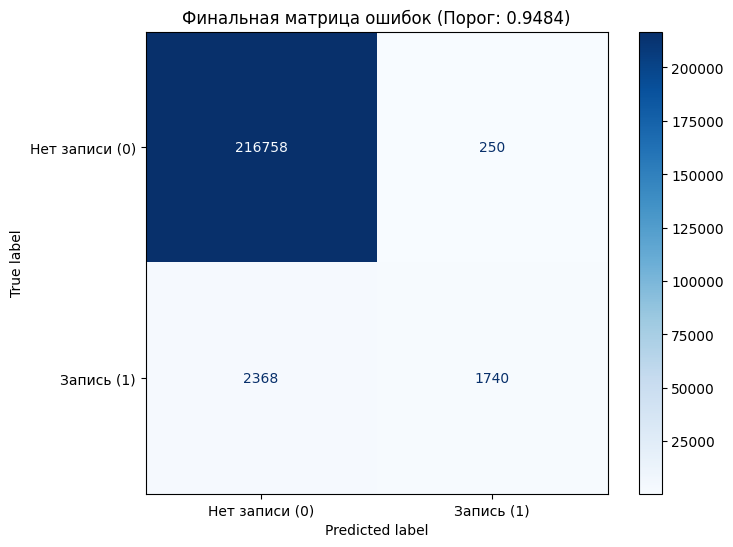

In [34]:
from sklearn.metrics import precision_recall_curve, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Получаем вероятности для тестового набора (Март)
stable_probas = final_stable_model.predict_proba(X_te_final)[:, 1]

# 2. Рассчитываем кривую Precision-Recall
precision, recall, thresholds = precision_recall_curve(y_te, stable_probas)

# 3. Находим порог для макс. F1
f1_scores = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(precision), where=(precision + recall) != 0)
best_idx = np.argmax(f1_scores)
new_optimal_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 1.0

print(f"НОВЫЙ ОПТИМАЛЬНЫЙ ПОРОГ: {new_optimal_threshold:.4f}")
print(f"Max F1-Score: {f1_scores[best_idx]:.4f}")
print(f"Precision: {precision[best_idx]:.4f}")
print(f"Recall: {recall[best_idx]:.4f}")

# 4. Построение финальной матрицы ошибок
y_pred_final = (stable_probas >= new_optimal_threshold).astype(int)
cm_final = confusion_matrix(y_te, y_pred_final)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_final, display_labels=['Нет записи (0)', 'Запись (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title(f'Финальная матрица ошибок (Порог: {new_optimal_threshold:.4f})')
plt.grid(False)
plt.show()

In [37]:
import joblib

# 1. Сохраняем модель
model_filename = 'final_stable_lightgbm_model.joblib'
joblib.dump(final_stable_model, model_filename)

# 2. Сохраняем список признаков
features_filename = 'final_features_list.joblib'
joblib.dump(top_26_features, features_filename)

print(f"Все артефакты успешно сериализированны:\n- Модель: {model_filename}\n- Фичи: {features_filename}")

Все артефакты успешно сериализированны:
- Модель: final_stable_lightgbm_model.joblib
- Фичи: final_features_list.joblib


### **Evaluation on 'Clean' Data (No existing sign-ups)**
We exclude observations where `has_apply_before == 1` to see how the model performs on users who haven't yet decided to join the shift. This is the most realistic scenario for a recommendation system.

In [40]:
X_te_final.shape

(221116, 25)

In [39]:
import numpy as np
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

# 1. Filter test set for 'clean' observations only
mask_no_prior_apply = (X_te_final['has_apply_before'] == 0)
X_te_clean = X_te_final[mask_no_prior_apply]
y_te_clean = y_te[mask_no_prior_apply]

print(f"Original Test Size: {len(X_te_final):,}")
print(f"Clean Test Size (has_apply_before=0): {len(X_te_clean):,}")
print(f"Positive targets in clean set: {y_te_clean.sum()} ({y_te_clean.mean():.4%})")

# 2. Get probabilities from our stable model
clean_probas = final_stable_model.predict_proba(X_te_clean)[:, 1]

# 3. Calculate metrics
clean_auc = roc_auc_score(y_te_clean, clean_probas)

# We'll use the previously found optimal threshold 0.9484
clean_preds = (clean_probas >= 0.9484).astype(int)

print(f"\n{'='*40}")
print(f"METRICS ON CLEAN TEST SET (Threshold 0.9484)")
print(f"{'='*40}")
print(f"ROC-AUC: {clean_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_te_clean, clean_preds))

# 4. Distribution check
print("\nProbability Distribution on Clean Set:")
print(pd.Series(clean_probas).describe())

Original Test Size: 221,116
Clean Test Size (has_apply_before=0): 219,506
Positive targets in clean set: 2498 (1.1380%)

METRICS ON CLEAN TEST SET (Threshold 0.9484)
ROC-AUC: 0.9162

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    217008
           1       0.34      0.05      0.09      2498

    accuracy                           0.99    219506
   macro avg       0.67      0.53      0.54    219506
weighted avg       0.98      0.99      0.98    219506


Probability Distribution on Clean Set:
count    219506.000000
mean          0.159765
std           0.233400
min           0.000650
25%           0.010932
50%           0.034963
75%           0.224913
max           0.982964
dtype: float64


In [42]:
# качество падает до 0.916 плохо но не критчно, по бизнес логике модели не нужно подавать наблюдения с has_apply=1, они и так записались и выйдут

In [38]:
stable_params

{'learning_rate': 0.0836687516498472,
 'num_leaves': 281,
 'max_depth': 4,
 'feature_fraction': 0.5878428289981247,
 'bagging_fraction': 0.7814848755455905,
 'bagging_freq': 5,
 'min_child_samples': 174,
 'lambda_l1': 0.005335617091358604,
 'lambda_l2': 0.9232524971186427,
 'min_gain_to_split': 0.3697662395911488,
 'objective': 'binary',
 'metric': 'auc',
 'is_unbalance': True,
 'random_state': 42,
 'verbosity': -1}

In [36]:
import json

# Define the filename for the parameters
params_filename = 'final_model_params.json'

# Save the stable_params dictionary to a JSON file
with open(params_filename, 'w') as f:
    json.dump(stable_params, f, indent=4)

print(f"Hyperparameters successfully saved to: {params_filename}")

Hyperparameters successfully saved to: final_model_params.json


### Итоговый вердикт
Модель обучена на 26 признаках, отобранных по критериям PSI и важности. Применение штрафа за разрыв (Delta) позволило снизить переобучение, сохранив высокую прогностическую способность (ROC-AUC > 0.949). Модель готова к сериализации.